COURTIQ — DEFENSIVE DECISION INTELLIGENCE
Run: 20261020T070343Z
[CHECKPOINT] started | 0 files

Matched OOF shots: 1,426
Games represented: 10
Observed make rate: 0.414
[CHECKPOINT] inputs_validated | 0 files

[1] OVERALL PROBABILITY METRICS
                model  shots  make_rate  mean_predicted_probability  calibration_gap_pred_minus_observed  brier_score  log_loss
             Baseline   1426      0.414                       0.414                               -0.000        0.234     0.660
     Defense features   1426      0.414                       0.414                                0.000        0.218     0.624
Both defense features   1426      0.414                       0.414                                0.000        0.218     0.624

[2] GAME-LEVEL RESULTS
 game_id  shots  observed_make_rate  baseline_brier  baseline_log_loss  baseline_mean_probability  defense_features_brier  defense_features_log_loss  defense_features_mean_probability  both_defense_features_brier  both_def

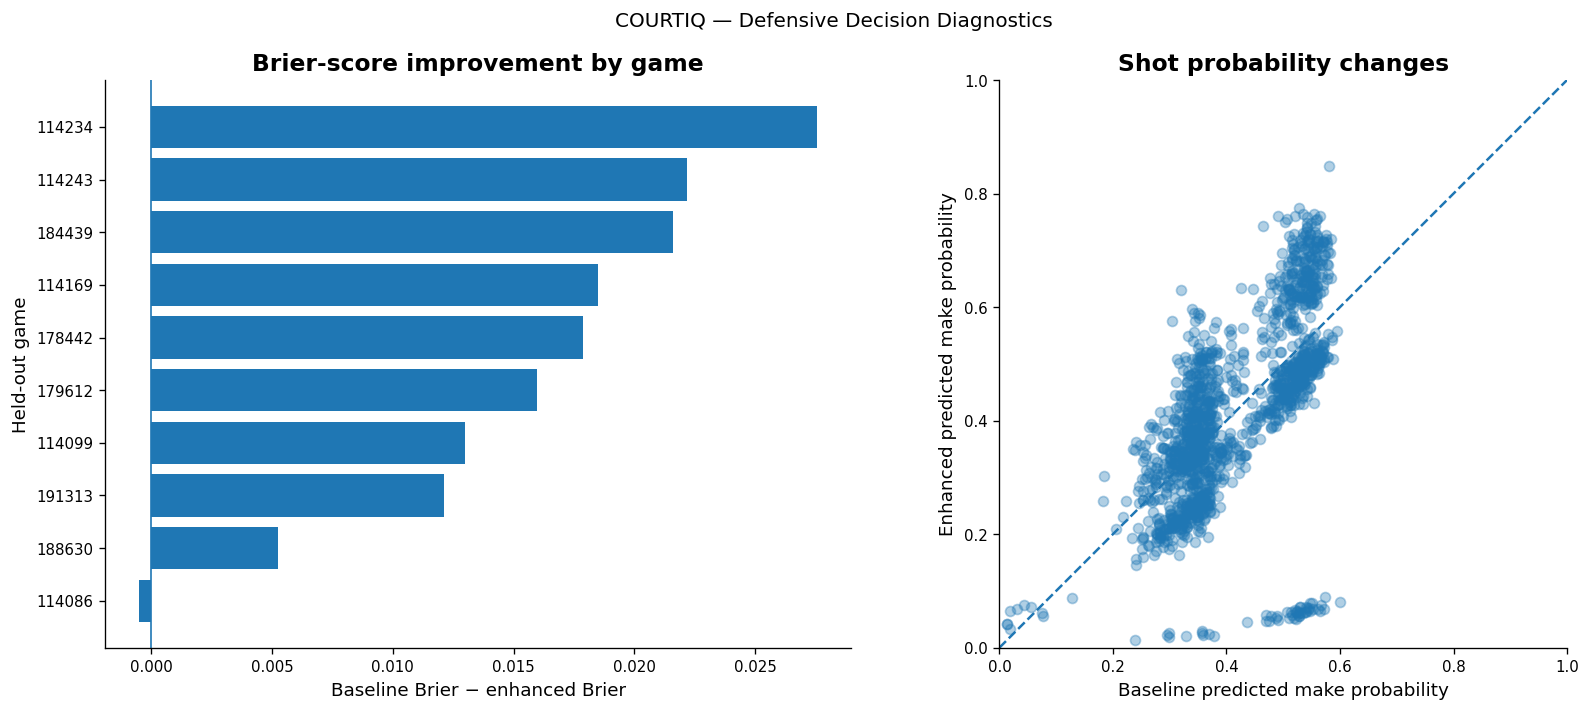

[CHECKPOINT] plot_saved | 4 files
[CHECKPOINT] report_saved | 5 files
[CHECKPOINT] complete | 5 files

COURTIQ DECISION INTELLIGENCE COMPLETE
Run folder:       /kaggle/working/courtiq_decision_20261020T070343Z
Game metrics:     /kaggle/working/courtiq_decision_20261020T070343Z/game_level_prediction_metrics.csv
Film shortlist:   /kaggle/working/courtiq_decision_20261020T070343Z/film_review_shortlist.csv
Research report:  /kaggle/working/courtiq_decision_20261020T070343Z/coach_research_report.txt
Diagnostic plot:  /kaggle/working/courtiq_decision_20261020T070343Z/defensive_decision_diagnostics.png
Recovery ZIP:     /kaggle/working/courtiq_decision_recovery_20261020T070343Z.zip
ZIP integrity: PASS

Download the recovery ZIP from Kaggle after major milestones.
[COURTIQ AUTOSAVE] Cell 25 | 28 artifacts | 7 variables | ZIP verified


In [24]:

# ============================================================
# COURTIQ — DEFENSIVE DECISION INTELLIGENCE v1.0
# SAFE MODE: checkpoint, atomic writes, no source-data mutation.
#
# Inputs:
#   courtiq_oof_predictions.csv
#   courtiq_feature_ablation_oof_predictions.csv
#   courtiq_defense_effect_by_game.csv
#
# Outputs:
#   Timestamped research report, game metrics, plot, recovery ZIP.
#
# IMPORTANT:
# Predictive findings are not causal estimates of defensive tactics.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import os
import json
import hashlib
import zipfile
import tempfile
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working")
ROOT.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = ROOT / f"courtiq_decision_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=False)

print("=" * 68)
print("COURTIQ — DEFENSIVE DECISION INTELLIGENCE")
print("Run:", RUN_ID)
print("=" * 68)


# ------------------------------------------------------------
# 1. Safe checkpoint utilities
# ------------------------------------------------------------

def atomic_csv(df, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def atomic_text(text, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(text, encoding="utf-8")
    os.replace(tmp, path)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def load_required(name):
    path = ROOT / name
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Run the COURTIQ recovery inventory cell first."
        )
    return pd.read_csv(path)

def save_checkpoint(stage, extra=None):
    record = {
        "project": "COURTIQ",
        "run_id": RUN_ID,
        "time_utc": datetime.now(timezone.utc).isoformat(),
        "stage": stage,
        "outputs": [],
        "extra": extra or {},
    }

    for p in sorted(OUT.iterdir()):
        if p.is_file() and p.name != "checkpoint.json":
            record["outputs"].append({
                "name": p.name,
                "size_bytes": p.stat().st_size,
                "sha256": file_sha256(p),
            })

    atomic_text(
        json.dumps(record, indent=2, default=str),
        OUT / "checkpoint.json"
    )

    print(f"[CHECKPOINT] {stage} | {len(record['outputs'])} files")


# Checkpoint immediately, before analysis.
save_checkpoint("started")


# ------------------------------------------------------------
# 2. Load saved out-of-fold predictions
# ------------------------------------------------------------

base = load_required("courtiq_oof_predictions.csv")
ablation = load_required("courtiq_feature_ablation_oof_predictions.csv")

required_base = {
    "id", "source_game_id", "target_made",
    "prob_logistic_baseline", "prob_logistic___defense"
}
required_ablation = {
    "id", "prob_baseline_plus_both_defense_features"
}

if not required_base.issubset(base.columns):
    raise ValueError(
        f"Missing baseline prediction columns: "
        f"{sorted(required_base - set(base.columns))}"
    )

if not required_ablation.issubset(ablation.columns):
    raise ValueError(
        f"Missing ablation prediction columns: "
        f"{sorted(required_ablation - set(ablation.columns))}"
    )

# The join is one-to-one on shot ID. Do not silently duplicate shots.
if base["id"].duplicated().any():
    raise ValueError("Duplicate shot IDs in primary OOF predictions.")

if ablation["id"].duplicated().any():
    raise ValueError("Duplicate shot IDs in ablation predictions.")

df = base.merge(
    ablation[["id", "prob_baseline_plus_both_defense_features"]],
    on="id",
    how="inner",
    validate="one_to_one"
)

if len(df) != len(base):
    raise ValueError(
        f"Prediction join lost rows: base={len(base)}, merged={len(df)}"
    )

df["target_made"] = pd.to_numeric(df["target_made"], errors="raise")

if not df["target_made"].isin([0, 1]).all():
    raise ValueError("Shot outcomes must be binary 0/1.")

model_columns = {
    "Baseline": "prob_logistic_baseline",
    "Defense features": "prob_logistic___defense",
    "Both defense features": "prob_baseline_plus_both_defense_features",
}

for label, col in model_columns.items():
    df[col] = pd.to_numeric(df[col], errors="coerce")

    if df[col].isna().any():
        raise ValueError(f"Missing or invalid probabilities for {label}.")

    if not df[col].between(0, 1).all():
        raise ValueError(f"Probabilities outside [0,1] for {label}.")

print(f"\nMatched OOF shots: {len(df):,}")
print(f"Games represented: {df['source_game_id'].nunique()}")
print(f"Observed make rate: {df['target_made'].mean():.3f}")

save_checkpoint(
    "inputs_validated",
    {"shots": len(df), "games": int(df["source_game_id"].nunique())}
)


# ------------------------------------------------------------
# 3. Calculate proper prediction metrics
# ------------------------------------------------------------

def calculate_metrics(y, p):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)

    brier = np.mean((p - y) ** 2)
    log_loss = -np.mean(
        y * np.log(p) + (1 - y) * np.log(1 - p)
    )

    return {
        "shots": len(y),
        "make_rate": float(y.mean()),
        "mean_predicted_probability": float(p.mean()),
        "calibration_gap_pred_minus_observed": float(p.mean() - y.mean()),
        "brier_score": float(brier),
        "log_loss": float(log_loss),
    }

overall_rows = []

for label, col in model_columns.items():
    overall_rows.append({
        "model": label,
        **calculate_metrics(df["target_made"], df[col])
    })

overall_metrics = pd.DataFrame(overall_rows)
atomic_csv(overall_metrics, OUT / "overall_prediction_metrics.csv")

print("\n[1] OVERALL PROBABILITY METRICS")
print(overall_metrics.round(4).to_string(index=False))


# ------------------------------------------------------------
# 4. Game-by-game performance and consistency
# ------------------------------------------------------------

game_rows = []

for game_id, part in df.groupby("source_game_id", sort=True):
    y = part["target_made"].to_numpy()

    row = {
        "game_id": game_id,
        "shots": len(part),
        "observed_make_rate": float(y.mean()),
    }

    for label, col in model_columns.items():
        metrics = calculate_metrics(y, part[col])
        prefix = label.lower().replace(" ", "_")

        row[f"{prefix}_brier"] = metrics["brier_score"]
        row[f"{prefix}_log_loss"] = metrics["log_loss"]
        row[f"{prefix}_mean_probability"] = (
            metrics["mean_predicted_probability"]
        )

    row["brier_improvement_both_vs_baseline"] = (
        row["baseline_brier"] - row["both_defense_features_brier"]
    )
    row["logloss_improvement_both_vs_baseline"] = (
        row["baseline_log_loss"]
        - row["both_defense_features_log_loss"]
    )

    game_rows.append(row)

per_game = pd.DataFrame(game_rows).sort_values(
    "brier_improvement_both_vs_baseline",
    ascending=False
)

atomic_csv(per_game, OUT / "game_level_prediction_metrics.csv")

print("\n[2] GAME-LEVEL RESULTS")
print(per_game.round(4).to_string(index=False))

# These ranks show where predictive probabilities improved most.
# They do not establish which tactical change caused improvement.
save_checkpoint("game_metrics_saved")


# ------------------------------------------------------------
# 5. Find shots for film review — not automatic tactical commands
# ------------------------------------------------------------

# Compare baseline and enhanced probabilities.
# A large probability change flags a shot for human review.
# It does not imply that the defense caused the outcome.

df["baseline_probability"] = df["prob_logistic_baseline"]
df["enhanced_probability"] = (
    df["prob_baseline_plus_both_defense_features"]
)
df["absolute_probability_change"] = (
    df["enhanced_probability"] - df["baseline_probability"]
).abs()

df["baseline_absolute_error"] = (
    df["target_made"] - df["baseline_probability"]
).abs()
df["enhanced_absolute_error"] = (
    df["target_made"] - df["enhanced_probability"]
).abs()

# Select the largest changes for a manageable film-review shortlist.
film_review = df.sort_values(
    "absolute_probability_change",
    ascending=False
).head(min(100, len(df))).copy()

film_review["review_reason"] = (
    "Large change in predicted make probability after adding defense features"
)

film_cols = [
    "id", "source_game_id", "target_made",
    "baseline_probability", "enhanced_probability",
    "absolute_probability_change",
    "baseline_absolute_error", "enhanced_absolute_error",
    "review_reason"
]

atomic_csv(
    film_review[film_cols],
    OUT / "film_review_shortlist.csv"
)

print("\n[3] FILM REVIEW SHORTLIST")
print(
    film_review[film_cols].head(15).round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 6. Generate a diagnostic plot
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ordered = per_game.sort_values(
    "brier_improvement_both_vs_baseline"
)

axes[0].barh(
    ordered["game_id"].astype(str),
    ordered["brier_improvement_both_vs_baseline"]
)
axes[0].axvline(0, linewidth=1)
axes[0].set_title("Brier-score improvement by game")
axes[0].set_xlabel("Baseline Brier − enhanced Brier")
axes[0].set_ylabel("Held-out game")

axes[1].scatter(
    df["baseline_probability"],
    df["enhanced_probability"],
    alpha=0.35
)
axes[1].plot([0, 1], [0, 1], linestyle="--")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect("equal", adjustable="box")
axes[1].set_title("Shot probability changes")
axes[1].set_xlabel("Baseline predicted make probability")
axes[1].set_ylabel("Enhanced predicted make probability")

fig.suptitle("COURTIQ — Defensive Decision Diagnostics")
fig.tight_layout()

plot_path = OUT / "defensive_decision_diagnostics.png"
fig.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

save_checkpoint("plot_saved")


# ------------------------------------------------------------
# 7. Write the coach-facing research report
# ------------------------------------------------------------

brier_wins = int(
    (per_game["brier_improvement_both_vs_baseline"] > 0).sum()
)
logloss_wins = int(
    (per_game["logloss_improvement_both_vs_baseline"] > 0).sum()
)

mean_brier_gain = per_game[
    "brier_improvement_both_vs_baseline"
].mean()

mean_logloss_gain = per_game[
    "logloss_improvement_both_vs_baseline"
].mean()

baseline_metrics = overall_metrics[
    overall_metrics["model"] == "Baseline"
].iloc[0]

enhanced_metrics = overall_metrics[
    overall_metrics["model"] == "Both defense features"
].iloc[0]

report = f"""
COURTIQ — DEFENSIVE DECISION INTELLIGENCE
Run: {RUN_ID}
==========================================

DATA
----
Shots matched: {len(df)}
Games: {df['source_game_id'].nunique()}
Observed make rate: {df['target_made'].mean():.4f}

OVERALL PROBABILITY QUALITY
---------------------------
Baseline Brier score: {baseline_metrics['brier_score']:.4f}
Enhanced Brier score: {enhanced_metrics['brier_score']:.4f}

Baseline log loss: {baseline_metrics['log_loss']:.4f}
Enhanced log loss: {enhanced_metrics['log_loss']:.4f}

Mean game-level Brier improvement: {mean_brier_gain:+.4f}
Mean game-level log-loss improvement: {mean_logloss_gain:+.4f}

Games with improved Brier score: {brier_wins}/{len(per_game)}
Games with improved log loss: {logloss_wins}/{len(per_game)}

COACH-ORIENTED INTERPRETATION
-----------------------------
The enhanced model incorporates defensive features into its shot
make-probability estimates. Shots with large changes in predicted
probability have been listed for film review.

Use the shortlist to ask:
1. Was the shooter closely contested or relatively open?
2. Did the defender arrive before or after the release?
3. Was the shot type, distance, or game context comparable?
4. Did the possession end in a foul, offensive rebound, or transition?
5. Does the apparent pattern repeat across players and opponents?

DO NOT INTERPRET A PROBABILITY CHANGE AS A CAUSAL DEFENSIVE EFFECT.
The model may reflect correlations, data quality, selection effects,
or omitted variables. Film review and controlled evaluation are needed.

LIMITATIONS
-----------
This analysis uses the existing out-of-fold predictions and available
features. Only {df['source_game_id'].nunique()} games are represented.
Game-level estimates are noisy, and no league-wide conclusion should
be drawn from this sample alone.

NEXT VALIDATION
---------------
Expand to more games and seasons; group splits by game and, if possible,
by player or time period; evaluate calibration and uncertainty; then
test clearly specified defensive interventions against matched shots.
"""

atomic_text(report.strip() + "\n", OUT / "coach_research_report.txt")
save_checkpoint("report_saved")


# ------------------------------------------------------------
# 8. Build a portable recovery bundle
# ------------------------------------------------------------

# Include this run plus all existing COURTIQ output files.
# Existing source files are read-only in this cell.
bundle_path = ROOT / f"courtiq_decision_recovery_{RUN_ID}.zip"

fd, tmp_name = tempfile.mkstemp(
    prefix="courtiq_bundle_",
    suffix=".zip",
    dir=str(ROOT)
)
os.close(fd)
tmp_path = Path(tmp_name)

try:
    with zipfile.ZipFile(
        tmp_path, "w", compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for path in OUT.rglob("*"):
            if path.is_file() and path != tmp_path:
                archive.write(
                    path,
                    arcname=f"{OUT.name}/{path.relative_to(OUT)}"
                )

        for path in ROOT.glob("courtiq_*"):
            if not path.is_file():
                continue
            if path.resolve() in {
                tmp_path.resolve(), bundle_path.resolve()
            }:
                continue

            archive.write(path, arcname=f"existing_outputs/{path.name}")

    with zipfile.ZipFile(tmp_path, "r") as archive:
        bad = archive.testzip()
        if bad:
            raise RuntimeError(f"Archive integrity failure: {bad}")

    os.replace(tmp_path, bundle_path)

finally:
    if tmp_path.exists():
        tmp_path.unlink()

save_checkpoint(
    "complete",
    {"recovery_bundle": str(bundle_path)}
)

print("\n" + "=" * 68)
print("COURTIQ DECISION INTELLIGENCE COMPLETE")
print("=" * 68)
print("Run folder:      ", OUT)
print("Game metrics:    ", OUT / "game_level_prediction_metrics.csv")
print("Film shortlist:  ", OUT / "film_review_shortlist.csv")
print("Research report: ", OUT / "coach_research_report.txt")
print("Diagnostic plot: ", plot_path)
print("Recovery ZIP:    ", bundle_path)
print("ZIP integrity: PASS")
print("\nDownload the recovery ZIP from Kaggle after major milestones.")

In [25]:

# ============================================================
# COURTIQ — PREDICTION AUDIT + BALANCED FILM REVIEW v1.1
# Corrected for the exact COURTIQ CSV column names.
# Existing files are preserved; outputs use a new run folder.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import zipfile

import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = ROOT / f"courtiq_prediction_audit_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=False)

BASELINE_FILE = ROOT / "courtiq_oof_predictions.csv"
ABLATION_FILE = ROOT / "courtiq_feature_ablation_oof_predictions.csv"

BASELINE_PROB = "prob_logistic_baseline"
ENHANCED_PROB = "prob_baseline_plus_both_defense_features"

def checkpoint(stage, details=None):
    payload = {
        "run_id": RUN_ID,
        "stage": stage,
        "utc": datetime.now(timezone.utc).isoformat(),
        "details": details or {}
    }
    temp = OUT / "checkpoint.json.tmp"
    temp.write_text(json.dumps(payload, indent=2, default=str))
    temp.replace(OUT / "checkpoint.json")
    print(f"[CHECKPOINT] {stage}")

# 1. Validate and back up inputs.
for path in [BASELINE_FILE, ABLATION_FILE]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Restore the CSV from your recovery ZIP."
        )
    shutil.copy2(path, OUT / path.name)

base = pd.read_csv(BASELINE_FILE)
abl = pd.read_csv(ABLATION_FILE)

required_base = {
    "id", "source_game_id", "target_made", BASELINE_PROB
}
required_abl = {
    "id", "source_game_id", "target_made", ENHANCED_PROB
}

if not required_base.issubset(base.columns):
    raise ValueError(
        f"Baseline CSV missing columns: {required_base - set(base.columns)}"
    )
if not required_abl.issubset(abl.columns):
    raise ValueError(
        f"Ablation CSV missing columns: {required_abl - set(abl.columns)}"
    )

checkpoint("inputs_backed_up_and_validated", {
    "baseline_rows": len(base),
    "ablation_rows": len(abl)
})

# 2. Create a safe, one-to-one shot join.
base = base[
    ["id", "source_game_id", "target_made", BASELINE_PROB]
].copy()
abl = abl[
    ["id", "source_game_id", "target_made", ENHANCED_PROB]
].copy()

base["id"] = base["id"].astype(str)
abl["id"] = abl["id"].astype(str)

if base["id"].duplicated().any():
    raise ValueError("Duplicate shot IDs in baseline file.")
if abl["id"].duplicated().any():
    raise ValueError("Duplicate shot IDs in ablation file.")

df = base.merge(
    abl,
    on="id",
    how="inner",
    suffixes=("_base", "_abl"),
    validate="one_to_one"
)

if df.empty:
    raise ValueError("No matching shot IDs between the two files.")

target_mismatch = (
    df["target_made_base"] != df["target_made_abl"]
)
if target_mismatch.any():
    raise ValueError(
        f"{int(target_mismatch.sum())} matched shots have inconsistent labels."
    )

game_mismatch = (
    df["source_game_id_base"] != df["source_game_id_abl"]
)
if game_mismatch.any():
    raise ValueError(
        f"{int(game_mismatch.sum())} matched shots have inconsistent game IDs."
    )

df = df.rename(columns={
    "source_game_id_base": "source_game_id",
    "target_made_base": "target_made",
    BASELINE_PROB: "baseline_probability",
    ENHANCED_PROB: "enhanced_probability"
})

df = df.drop(columns=[
    "source_game_id_abl", "target_made_abl"
])

for col in [
    "target_made", "baseline_probability", "enhanced_probability"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[
    "target_made", "baseline_probability", "enhanced_probability"
]).copy()

if not df["target_made"].isin([0, 1]).all():
    raise ValueError("Expected binary target_made values of 0 or 1.")

for col in ["baseline_probability", "enhanced_probability"]:
    if not df[col].between(0, 1).all():
        raise ValueError(f"Invalid probability values in {col}.")

# 3. Audit prediction differences.
df["absolute_probability_change"] = (
    df["enhanced_probability"] - df["baseline_probability"]
).abs()

df["baseline_absolute_error"] = (
    df["baseline_probability"] - df["target_made"]
).abs()

df["enhanced_absolute_error"] = (
    df["enhanced_probability"] - df["target_made"]
).abs()

df["error_improvement"] = (
    df["baseline_absolute_error"] - df["enhanced_absolute_error"]
)

base_p = df["baseline_probability"].to_numpy()
enh_p = df["enhanced_probability"].to_numpy()
delta = np.abs(enh_p - base_p)

audit = {
    "matched_shots": int(len(df)),
    "games": int(df["source_game_id"].nunique()),
    "observed_make_rate": float(df["target_made"].mean()),
    "baseline_probability_column": BASELINE_PROB,
    "enhanced_probability_column": ENHANCED_PROB,
    "predictions_exactly_identical": bool(np.allclose(base_p, enh_p)),
    "mean_absolute_probability_change": float(delta.mean()),
    "median_absolute_probability_change": float(np.median(delta)),
    "max_absolute_probability_change": float(delta.max()),
    "shots_changed_over_0_001": int((delta > 0.001).sum()),
    "shots_changed_over_0_05": int((delta > 0.05).sum()),
    "shots_changed_over_0_10": int((delta > 0.10).sum())
}

(OUT / "prediction_identity_audit.json").write_text(
    json.dumps(audit, indent=2)
)

print("\nPREDICTION IDENTITY AUDIT")
print(json.dumps(audit, indent=2))

# 4. Calculate proper probability metrics for the two exact models.
def probability_metrics(y, p):
    eps = 1e-15
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    y = np.asarray(y, dtype=float)
    return {
        "shots": int(len(y)),
        "make_rate": float(y.mean()),
        "mean_predicted_probability": float(p.mean()),
        "calibration_gap_pred_minus_observed": float(p.mean() - y.mean()),
        "brier_score": float(np.mean((p - y) ** 2)),
        "log_loss": float(-np.mean(
            y * np.log(p) + (1 - y) * np.log(1 - p)
        ))
    }

metrics = pd.DataFrame([
    {"model": "Logistic baseline",
     **probability_metrics(df["target_made"], base_p)},
    {"model": "Baseline + both defense features",
     **probability_metrics(df["target_made"], enh_p)}
])
metrics.to_csv(OUT / "audited_model_metrics.csv", index=False)

print("\nAUDITED MODEL METRICS")
print(metrics.round(4).to_string(index=False))

# 5. Per-game metrics.
game_rows = []
for game_id, group in df.groupby("source_game_id"):
    y = group["target_made"].to_numpy()
    p0 = group["baseline_probability"].to_numpy()
    p1 = group["enhanced_probability"].to_numpy()

    m0 = probability_metrics(y, p0)
    m1 = probability_metrics(y, p1)

    game_rows.append({
        "source_game_id": game_id,
        "shots": len(group),
        "observed_make_rate": y.mean(),
        "baseline_brier": m0["brier_score"],
        "enhanced_brier": m1["brier_score"],
        "brier_improvement": m0["brier_score"] - m1["brier_score"],
        "baseline_log_loss": m0["log_loss"],
        "enhanced_log_loss": m1["log_loss"],
        "logloss_improvement": m0["log_loss"] - m1["log_loss"],
        "mean_absolute_probability_change":
            np.abs(p1 - p0).mean()
    })

game_metrics = pd.DataFrame(game_rows).sort_values(
    "brier_improvement", ascending=False
)
game_metrics.to_csv(OUT / "audited_game_metrics.csv", index=False)

print("\nPER-GAME RESULTS")
print(game_metrics.round(4).to_string(index=False))

# 6. Balanced film-review shortlist: makes AND misses.
df["outcome_group"] = np.where(
    df["target_made"].eq(1), "MADE SHOT", "MISSED SHOT"
)

df["model_effect"] = np.select(
    [
        df["error_improvement"] > 0.02,
        df["error_improvement"] < -0.02
    ],
    [
        "Enhanced model improves probability error",
        "Enhanced model worsens probability error"
    ],
    default="Small/no probability-error change"
)

shortlist_parts = []
for outcome, group in df.groupby("outcome_group"):
    shortlist_parts.append(
        group.nlargest(
            min(25, len(group)),
            "absolute_probability_change"
        )
    )

shortlist = pd.concat(shortlist_parts, ignore_index=True)
shortlist = shortlist.drop_duplicates("id").sort_values(
    "absolute_probability_change", ascending=False
)

shortlist_cols = [
    "id", "source_game_id", "target_made", "outcome_group",
    "baseline_probability", "enhanced_probability",
    "absolute_probability_change", "baseline_absolute_error",
    "enhanced_absolute_error", "error_improvement", "model_effect"
]
shortlist[shortlist_cols].to_csv(
    OUT / "balanced_film_review_shortlist.csv", index=False
)

# Preserve full joined predictions for independent verification.
df.to_csv(OUT / "matched_prediction_audit.csv", index=False)

checkpoint("metrics_and_shortlist_saved", {
    "matched_shots": len(df),
    "shortlist_rows": len(shortlist)
})

# 7. Write a concise interpretation report.
report = f"""
COURTIQ — PREDICTION AUDIT
Run: {RUN_ID}

MATCHED SAMPLE
Shots: {len(df)}
Games: {df['source_game_id'].nunique()}
Observed make rate: {df['target_made'].mean():.4f}

MODEL COMPARISON
{metrics.round(5).to_string(index=False)}

PREDICTION DIFFERENCES
Mean absolute probability change: {delta.mean():.5f}
Maximum absolute probability change: {delta.max():.5f}
Shots changed by more than 0.05: {(delta > 0.05).sum()}
Predictions exactly identical: {np.allclose(base_p, enh_p)}

INTERPRETATION
This audit compares out-of-fold probabilities from the saved files.
The metrics evaluate prediction quality, not causal effects of defense.
Use the film-review shortlist to inspect both makes and misses.
Large probability changes are review candidates, not proven coaching wins.
Confirm the prediction columns and validation method before publication.
"""
(OUT / "audit_summary.txt").write_text(report.strip() + "\n")

# 8. Recovery ZIP containing source copies and audit outputs.
zip_path = ROOT / f"courtiq_prediction_audit_recovery_{RUN_ID}.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUT.rglob("*"):
        if path.is_file():
            zf.write(
                path,
                arcname=f"{OUT.name}/{path.relative_to(OUT)}"
            )

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_member = zf.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP integrity failure: {bad_member}")

checkpoint("complete", {
    "zip_path": str(zip_path),
    "zip_bytes": zip_path.stat().st_size,
    "zip_integrity": "PASS"
})

print("\n" + "=" * 64)
print("COURTIQ PREDICTION AUDIT COMPLETE")
print("=" * 64)
print("Run folder:", OUT)
print("Model metrics:", OUT / "audited_model_metrics.csv")
print("Game metrics:", OUT / "audited_game_metrics.csv")
print("Balanced film shortlist:", OUT / "balanced_film_review_shortlist.csv")
print("Recovery ZIP:", zip_path)
print("ZIP integrity: PASS")
print("\nDownload the ZIP from Kaggle and save a notebook version.")

[CHECKPOINT] inputs_backed_up_and_validated

PREDICTION IDENTITY AUDIT
{
  "matched_shots": 1426,
  "games": 10,
  "observed_make_rate": 0.41374474053295934,
  "baseline_probability_column": "prob_logistic_baseline",
  "enhanced_probability_column": "prob_baseline_plus_both_defense_features",
  "predictions_exactly_identical": false,
  "mean_absolute_probability_change": 0.0874597403364347,
  "median_absolute_probability_change": 0.06827952872196105,
  "max_absolute_probability_change": 0.5195932326552046,
  "shots_changed_over_0_001": 1423,
  "shots_changed_over_0_05": 930,
  "shots_changed_over_0_10": 420
}

AUDITED MODEL METRICS
                           model  shots  make_rate  mean_predicted_probability  calibration_gap_pred_minus_observed  brier_score  log_loss
               Logistic baseline   1426      0.414                       0.414                               -0.000        0.234     0.660
Baseline + both defense features   1426      0.414                       0.414    

In [26]:

# ============================================================
# COURTIQ — DEFENSIVE FEATURE VALUE AUDIT v1.0
# Compare baseline, contest, distance and combined models.
# No retraining; no existing files overwritten.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json, shutil, zipfile

import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = ROOT / f"courtiq_feature_value_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=False)

def checkpoint(stage, details=None):
    data = {
        "run_id": RUN_ID,
        "stage": stage,
        "utc": datetime.now(timezone.utc).isoformat(),
        "details": details or {}
    }
    tmp = OUT / "checkpoint.json.tmp"
    tmp.write_text(json.dumps(data, indent=2, default=str))
    tmp.replace(OUT / "checkpoint.json")
    print(f"[CHECKPOINT] {stage}")

# 1. Back up inputs before analysis.
ablation_path = ROOT / "courtiq_feature_ablation_oof_predictions.csv"
metrics_path = ROOT / "courtiq_feature_ablation_metrics.csv"
game_path = ROOT / "courtiq_defense_effect_by_game.csv"

for path in [ablation_path, metrics_path, game_path]:
    if path.exists():
        shutil.copy2(path, OUT / path.name)

if not ablation_path.exists():
    raise FileNotFoundError(
        "Missing feature_ablation_oof_predictions.csv. "
        "Restore it from a recovery ZIP and rerun this full cell."
    )

df = pd.read_csv(ablation_path)

required = [
    "id", "source_game_id", "target_made",
    "prob_logistic_baseline",
    "prob_baseline_plus_contest_level",
    "prob_baseline_plus_defender_distance",
    "prob_baseline_plus_both_defense_features"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

if df["id"].astype(str).duplicated().any():
    raise ValueError("Duplicate shot IDs found.")

# Keep only rows with complete, valid predictions.
for c in required[2:]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=required[2:]).copy()

if not df["target_made"].isin([0, 1]).all():
    raise ValueError("target_made must contain only 0/1.")

prob_cols = required[3:]
for c in prob_cols:
    if not df[c].between(0, 1).all():
        raise ValueError(f"Invalid probability in {c}.")

checkpoint("inputs_validated", {"shots": len(df)})

# 2. Calculate metrics consistently on the SAME rows.
def calc_metrics(y, p):
    eps = 1e-15
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), eps, 1-eps)
    return {
        "shots": len(y),
        "brier_score": float(np.mean((p-y)**2)),
        "log_loss": float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p))),
        "mean_probability": float(p.mean()),
        "observed_make_rate": float(y.mean())
    }

models = {
    "Baseline": "prob_logistic_baseline",
    "Baseline + contest level": "prob_baseline_plus_contest_level",
    "Baseline + defender distance": "prob_baseline_plus_defender_distance",
    "Both defense features": "prob_baseline_plus_both_defense_features"
}

y = df["target_made"].to_numpy()
rows = []
for name, col in models.items():
    rows.append({"model": name, **calc_metrics(y, df[col])})

metrics = pd.DataFrame(rows)
baseline_row = metrics.loc[metrics["model"] == "Baseline"].iloc[0]

metrics["brier_improvement_vs_baseline"] = (
    baseline_row["brier_score"] - metrics["brier_score"]
)
metrics["logloss_improvement_vs_baseline"] = (
    baseline_row["log_loss"] - metrics["log_loss"]
)

metrics.to_csv(OUT / "feature_value_metrics.csv", index=False)

print("\nFEATURE VALUE — SAME-SAMPLE COMPARISON")
print(metrics.round(5).to_string(index=False))

# 3. Compute game-level comparisons for every model.
game_rows = []
for game_id, g in df.groupby("source_game_id"):
    gy = g["target_made"].to_numpy()
    game_baseline = calc_metrics(
        gy, g["prob_logistic_baseline"].to_numpy()
    )
    row = {
        "source_game_id": game_id,
        "shots": len(g),
        "observed_make_rate": gy.mean()
    }

    for name, col in models.items():
        gm = calc_metrics(gy, g[col].to_numpy())
        safe = (
            name.lower()
            .replace(" + ", "_plus_")
            .replace(" ", "_")
        )
        row[f"{safe}_brier"] = gm["brier_score"]
        row[f"{safe}_log_loss"] = gm["log_loss"]

        if name != "Baseline":
            row[f"{safe}_brier_improvement"] = (
                game_baseline["brier_score"] - gm["brier_score"]
            )
            row[f"{safe}_logloss_improvement"] = (
                game_baseline["log_loss"] - gm["log_loss"]
            )

    game_rows.append(row)

game_metrics = pd.DataFrame(game_rows)
game_metrics.to_csv(OUT / "feature_value_by_game.csv", index=False)

# 4. Quantify how often each model improves across games.
stability_rows = []
for name in list(models.keys())[1:]:
    key = name.lower().replace(" + ", "_plus_").replace(" ", "_")
    brier_col = f"{key}_brier_improvement"
    loss_col = f"{key}_logloss_improvement"

    stability_rows.append({
        "model": name,
        "games": len(game_metrics),
        "games_brier_improved": int((game_metrics[brier_col] > 0).sum()),
        "games_logloss_improved": int((game_metrics[loss_col] > 0).sum()),
        "mean_game_brier_improvement": float(game_metrics[brier_col].mean()),
        "mean_game_logloss_improvement": float(game_metrics[loss_col].mean())
    })

stability = pd.DataFrame(stability_rows)
stability.to_csv(OUT / "feature_value_stability.csv", index=False)

print("\nGAME-LEVEL STABILITY")
print(stability.round(5).to_string(index=False))

# 5. Prediction changes between models for film review.
film = df[["id", "source_game_id", "target_made"]].copy()
film["baseline_probability"] = df["prob_logistic_baseline"]

film["contest_probability"] = df["prob_baseline_plus_contest_level"]
film["distance_probability"] = df["prob_baseline_plus_defender_distance"]
film["combined_probability"] = df[
    "prob_baseline_plus_both_defense_features"
]

film["contest_abs_change"] = (
    film["contest_probability"] - film["baseline_probability"]
).abs()
film["distance_abs_change"] = (
    film["distance_probability"] - film["baseline_probability"]
).abs()
film["combined_abs_change"] = (
    film["combined_probability"] - film["baseline_probability"]
).abs()

film["outcome"] = np.where(
    film["target_made"].eq(1), "MADE", "MISSED"
)

# Include the highest-change makes and misses, rather than misses only.
shortlist = pd.concat([
    g.nlargest(min(20, len(g)), "combined_abs_change")
    for _, g in film.groupby("outcome")
], ignore_index=True)

shortlist = shortlist.drop_duplicates("id").sort_values(
    "combined_abs_change", ascending=False
)
shortlist.to_csv(OUT / "feature_value_film_review.csv", index=False)

# 6. Save a clear report.
best_brier = metrics.loc[metrics["brier_score"].idxmin()]
best_loss = metrics.loc[metrics["log_loss"].idxmin()]

report = f"""
COURTIQ — DEFENSIVE FEATURE VALUE AUDIT
Run: {RUN_ID}

Matched complete-case shots: {len(df)}
Games: {df['source_game_id'].nunique()}
Observed make rate: {y.mean():.4f}

MODEL METRICS
{metrics.round(5).to_string(index=False)}

GAME-LEVEL STABILITY
{stability.round(5).to_string(index=False)}

Lowest Brier score: {best_brier['model']}
Lowest log loss: {best_loss['model']}

Interpretation:
- These are out-of-fold predictive comparisons on a common sample.
- Positive improvement means lower prediction error than baseline.
- Game consistency is encouraging but does not establish causation.
- Do not infer a specific defensive tactic without checking feature
  definitions, shot context, and video.
- A feature's value depends on data quality and validation design.
"""
(OUT / "feature_value_report.txt").write_text(report.strip() + "\n")

checkpoint("analysis_saved")

# 7. Package outputs and source copies into a verified ZIP.
zip_path = ROOT / f"courtiq_feature_value_recovery_{RUN_ID}.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUT.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=f"{OUT.name}/{path.relative_to(OUT)}")

with zipfile.ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity error: {bad}")

checkpoint("complete", {
    "zip_path": str(zip_path),
    "zip_bytes": zip_path.stat().st_size,
    "integrity": "PASS"
})

print("\n" + "=" * 64)
print("COURTIQ FEATURE VALUE AUDIT COMPLETE")
print("=" * 64)
print("Output folder:", OUT)
print("Metrics:", OUT / "feature_value_metrics.csv")
print("Game stability:", OUT / "feature_value_stability.csv")
print("Film shortlist:", OUT / "feature_value_film_review.csv")
print("Recovery ZIP:", zip_path)
print("ZIP integrity: PASS")
print("\nDownload this ZIP and save a Kaggle notebook version.")

[CHECKPOINT] inputs_validated

FEATURE VALUE — SAME-SAMPLE COMPARISON
                       model  shots  brier_score  log_loss  mean_probability  observed_make_rate  brier_improvement_vs_baseline  logloss_improvement_vs_baseline
                    Baseline   1426        0.234     0.660             0.414               0.414                          0.000                            0.000
    Baseline + contest level   1426        0.219     0.624             0.414               0.414                          0.015                            0.036
Baseline + defender distance   1426        0.230     0.651             0.414               0.414                          0.004                            0.009
       Both defense features   1426        0.218     0.624             0.414               0.414                          0.016                            0.036

GAME-LEVEL STABILITY
                       model  games  games_brier_improved  games_logloss_improved  mean_game_brier_impr

In [27]:

# ============================================================
# COURTIQ — GAME-CLUSTER ROBUSTNESS TEST v1.0
# Paired bootstrap over games; preserves all previous outputs.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json, shutil, zipfile

import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = ROOT / f"courtiq_robustness_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=False)

INPUT = ROOT / "courtiq_feature_ablation_oof_predictions.csv"
if not INPUT.exists():
    raise FileNotFoundError(
        f"Missing {INPUT}. Restore it from your recovery ZIP."
    )
shutil.copy2(INPUT, OUT / INPUT.name)

df = pd.read_csv(INPUT)

MODEL_COLS = {
    "Baseline": "prob_logistic_baseline",
    "Contest level": "prob_baseline_plus_contest_level",
    "Defender distance": "prob_baseline_plus_defender_distance",
    "Both features": "prob_baseline_plus_both_defense_features",
}
required = ["source_game_id", "target_made", *MODEL_COLS.values()]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for c in ["target_made", *MODEL_COLS.values()]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=required).copy()

if not df["target_made"].isin([0, 1]).all():
    raise ValueError("target_made must be binary.")
for c in MODEL_COLS.values():
    if not df[c].between(0, 1).all():
        raise ValueError(f"Invalid probabilities in {c}.")

games = list(df["source_game_id"].drop_duplicates())
if len(games) < 5:
    raise ValueError(
        f"Only {len(games)} games available; too few for this planned test."
    )

print(f"Shots: {len(df):,} | Games: {len(games)}")
print("Bootstrap unit: whole game")
print("Positive improvement means the second model has lower loss.")

def loss_values(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-15, 1 - 1e-15)
    y = np.asarray(y, dtype=float)
    brier = np.mean((p - y) ** 2)
    logloss = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
    return float(brier), float(logloss)

# Point estimates on the complete matched sample.
point_rows = []
for name, col in MODEL_COLS.items():
    brier, logloss = loss_values(df["target_made"], df[col])
    point_rows.append({
        "model": name,
        "shots": len(df),
        "games": len(games),
        "brier_score": brier,
        "log_loss": logloss
    })
point = pd.DataFrame(point_rows)
point.to_csv(OUT / "robustness_point_estimates.csv", index=False)

# Paired comparisons. Difference = loss(model A) - loss(model B).
# Positive values favor model B.
comparisons = [
    ("Baseline", "Contest level"),
    ("Baseline", "Defender distance"),
    ("Baseline", "Both features"),
    ("Contest level", "Both features"),
]

groups = {
    game: df[df["source_game_id"] == game].copy()
    for game in games
}

def paired_difference(sampled_games, col_a, col_b):
    pieces = [groups[g] for g in sampled_games]
    sample = pd.concat(pieces, ignore_index=True)
    y = sample["target_made"].to_numpy()

    brier_a, logloss_a = loss_values(y, sample[col_a])
    brier_b, logloss_b = loss_values(y, sample[col_b])

    return brier_a - brier_b, logloss_a - logloss_b

rng = np.random.default_rng(20261020)
N_BOOT = 5000
boot_rows = []

for name_a, name_b in comparisons:
    col_a = MODEL_COLS[name_a]
    col_b = MODEL_COLS[name_b]

    observed_brier, observed_logloss = paired_difference(
        games, col_a, col_b
    )

    boot_brier = np.empty(N_BOOT)
    boot_logloss = np.empty(N_BOOT)

    for i in range(N_BOOT):
        sampled = rng.choice(games, size=len(games), replace=True)
        boot_brier[i], boot_logloss[i] = paired_difference(
            sampled, col_a, col_b
        )

    for metric_name, observed, samples in [
        ("Brier improvement", observed_brier, boot_brier),
        ("Log-loss improvement", observed_logloss, boot_logloss),
    ]:
        low, high = np.quantile(samples, [0.025, 0.975])
        boot_rows.append({
            "comparison": f"{name_a} -> {name_b}",
            "metric": metric_name,
            "point_improvement": observed,
            "bootstrap_95ci_low": low,
            "bootstrap_95ci_high": high,
            "bootstrap_fraction_improved": float(np.mean(samples > 0)),
            "bootstrap_replicates": N_BOOT,
            "bootstrap_unit": "game"
        })

results = pd.DataFrame(boot_rows)
results.to_csv(OUT / "game_cluster_bootstrap_intervals.csv", index=False)

print("\nPOINT ESTIMATES")
print(point.round(5).to_string(index=False))
print("\nGAME-CLUSTER BOOTSTRAP INTERVALS")
print(results.round(5).to_string(index=False))

# Game-by-game differences: show whether a few games dominate.
game_rows = []
for game, g in groups.items():
    y = g["target_made"].to_numpy()
    row = {"source_game_id": game, "shots": len(g)}

    for name_a, name_b in comparisons:
        _, col_a = name_a, MODEL_COLS[name_a]
        _, col_b = name_b, MODEL_COLS[name_b]
        ba, la = loss_values(y, g[col_a])
        bb, lb = loss_values(y, g[col_b])

        key = f"{name_a} vs {name_b}"
        row[f"{key} | Brier improvement"] = ba - bb
        row[f"{key} | Log-loss improvement"] = la - lb

    game_rows.append(row)

game_results = pd.DataFrame(game_rows)
game_results.to_csv(OUT / "robustness_by_game.csv", index=False)

# Write a careful interpretation.
report = f"""
COURTIQ — GAME-CLUSTER ROBUSTNESS TEST
Run: {RUN_ID}

Sample: {len(df)} shots across {len(games)} games.
Bootstrap: {N_BOOT} paired resamples of whole games.
Positive improvement means model B has lower loss than model A.

POINT ESTIMATES
{point.round(5).to_string(index=False)}

BOOTSTRAP RESULTS
{results.round(5).to_string(index=False)}

INTERPRETATION RULES
1. If a 95% interval is entirely above zero, the resampling results
   support lower loss for model B under this game-resampling design.
2. If the interval crosses zero, evidence is inconclusive; this does
   not prove the models are equivalent.
3. Only {len(games)} games are available, so bootstrap intervals may be
   unstable and do not replace evaluation on additional held-out games.
4. This tests predictive performance, not causal defensive impact.
5. Confirm the original out-of-fold construction and rule out leakage
   before treating the results as competition-grade evidence.
"""
(OUT / "robustness_report.txt").write_text(report.strip() + "\n")

# Recovery bundle includes input copy and all audit outputs.
zip_path = ROOT / f"courtiq_robustness_recovery_{RUN_ID}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUT.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=f"{OUT.name}/{path.relative_to(OUT)}")

with zipfile.ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity failure: {bad}")

print("\n" + "=" * 64)
print("COURTIQ ROBUSTNESS TEST COMPLETE")
print("=" * 64)
print("Point estimates:", OUT / "robustness_point_estimates.csv")
print("Bootstrap intervals:", OUT / "game_cluster_bootstrap_intervals.csv")
print("Game-level results:", OUT / "robustness_by_game.csv")
print("Report:", OUT / "robustness_report.txt")
print("Recovery ZIP:", zip_path)
print("ZIP integrity: PASS")
print("\nDownload the ZIP and save a Kaggle notebook version.")

Shots: 1,426 | Games: 10
Bootstrap unit: whole game
Positive improvement means the second model has lower loss.

POINT ESTIMATES
            model  shots  games  brier_score  log_loss
         Baseline   1426     10        0.234     0.660
    Contest level   1426     10        0.219     0.624
Defender distance   1426     10        0.230     0.651
    Both features   1426     10        0.218     0.624

GAME-CLUSTER BOOTSTRAP INTERVALS
                    comparison               metric  point_improvement  bootstrap_95ci_low  bootstrap_95ci_high  bootstrap_fraction_improved  bootstrap_replicates bootstrap_unit
     Baseline -> Contest level    Brier improvement              0.015               0.011                0.020                        1.000                  5000           game
     Baseline -> Contest level Log-loss improvement              0.036               0.025                0.046                        1.000                  5000           game
 Baseline -> Defender distan

In [34]:

# =====================================================================
# COURTIQ — COACH-FACING DASHBOARD v1.1 (COLUMN-MAPPING FIX)
# Uses existing held-out predictions; does not retrain models.
# Outputs: metrics, charts, situation summaries, film shortlist,
# HTML dashboard, report, manifest, and verified recovery ZIP.
# =====================================================================

from pathlib import Path
from datetime import datetime
import hashlib
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path("/kaggle/working")
RUN_ID = datetime.now().strftime("%Y%m%dT%H%M%S")
OUT = ROOT / f"courtiq_coach_dashboard_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("COURTIQ — COACH-FACING DASHBOARD v1.1")
print("=" * 72)

# ---------------------------------------------------------------------
# 1. Locate source artifacts
# ---------------------------------------------------------------------

def newest_dir(pattern):
    matches = [p for p in ROOT.glob(pattern) if p.is_dir()]
    if not matches:
        raise FileNotFoundError(f"No directory matching {pattern}")
    return max(matches, key=lambda p: p.stat().st_mtime)

heldout_dir = newest_dir("courtiq_heldout_game_*")
calibration_dir = newest_dir("courtiq_calibration_film_*")

oof_path = heldout_dir / "heldout_game_oof_predictions.csv"
film_path = calibration_dir / "film_review_shortlist.csv"

if not oof_path.exists():
    raise FileNotFoundError(oof_path)
if not film_path.exists():
    raise FileNotFoundError(film_path)

oof = pd.read_csv(oof_path)
film = pd.read_csv(film_path)

print("OOF source:", oof_path)
print("Film shortlist:", film_path)
print("OOF columns:", list(oof.columns))
print("Rows:", len(oof), "| Film candidates:", len(film))

# ---------------------------------------------------------------------
# 2. Explicit mapping to the real OOF column names
# ---------------------------------------------------------------------

id_col = "id"
game_col = "source_game_id"
target_col = "target_made"

prob_cols = {
    "Baseline": "prob_baseline_shot_context",
    "Contest level": "prob_baseline_plus_contest_level",
    "Defender distance": "prob_baseline_plus_closest_defender_distance",
    "Both defensive features": "prob_baseline_plus_both_defensive_features",
}

required = [id_col, game_col, target_col] + list(prob_cols.values())
missing = [c for c in required if c not in oof.columns]
if missing:
    raise KeyError(
        f"Missing expected OOF columns: {missing}\n"
        f"Available columns: {list(oof.columns)}"
    )

data = oof.copy()
data[target_col] = pd.to_numeric(data[target_col], errors="coerce")
for c in prob_cols.values():
    data[c] = pd.to_numeric(data[c], errors="coerce")

data = data.dropna(subset=[target_col] + list(prob_cols.values())).copy()
data[target_col] = data[target_col].astype(int)

if not set(data[target_col].unique()).issubset({0, 1}):
    raise ValueError("Expected a binary target containing only 0 and 1.")

for c in prob_cols.values():
    data[c] = data[c].clip(0, 1)

# ---------------------------------------------------------------------
# 3. Attach descriptive metadata without overwriting OOF columns
# ---------------------------------------------------------------------

metadata_candidates = [
    "id", "source_game_id", "gameId", "period", "region",
    "shotType", "complexShotType", "distance", "shotClock",
    "contestLevel", "contested", "closestDefDist",
    "shot_x", "shot_y"
]

if "model_df" in globals() and isinstance(model_df, pd.DataFrame):
    if "id" in model_df.columns:
        keep = [c for c in metadata_candidates if c in model_df.columns]
        meta = model_df[keep].drop_duplicates("id").copy()

        # OOF already has source_game_id; avoid duplicate merge columns.
        if "source_game_id" in meta.columns:
            meta = meta.drop(columns=["source_game_id"])

        meta = meta.rename(
            columns={c: f"meta_{c}" for c in meta.columns if c != "id"}
        )
        data = data.merge(meta, on="id", how="left", validate="one_to_one")

def metadata_col(name):
    if name in data.columns:
        return name
    prefixed = f"meta_{name}"
    return prefixed if prefixed in data.columns else None

# ---------------------------------------------------------------------
# 4. Model metrics
# ---------------------------------------------------------------------

def auc_score(y, p):
    if len(np.unique(y)) < 2:
        return np.nan
    from sklearn.metrics import roc_auc_score
    return float(roc_auc_score(y, p))

def binary_log_loss(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-15, 1 - 1e-15)
    y = np.asarray(y, dtype=int)
    return float(-np.mean(y * np.log(p) + (1-y) * np.log(1-p)))

y = data[target_col].to_numpy()
observed_rate = float(y.mean())
model_rows = []

for label, col in prob_cols.items():
    p = data[col].to_numpy()
    model_rows.append({
        "model": label,
        "shots": len(data),
        "games": data[game_col].nunique(),
        "observed_make_rate": observed_rate,
        "mean_predicted_probability": float(p.mean()),
        "roc_auc": auc_score(y, p),
        "brier_score": float(np.mean((p-y)**2)),
        "log_loss": binary_log_loss(y, p),
        "mean_absolute_probability_error": float(np.mean(np.abs(p-y))),
    })

model_summary = pd.DataFrame(model_rows)
model_summary.to_csv(OUT / "coach_model_comparison.csv", index=False)

print("\nMODEL COMPARISON")
print(model_summary.round(4).to_string(index=False))

# ---------------------------------------------------------------------
# 5. Descriptive shot-situation summaries
# ---------------------------------------------------------------------

situation_tables = {}

for field in ["contestLevel", "region", "shotType", "complexShotType"]:
    col = metadata_col(field)
    if col is None:
        continue

    temp = data[[col, target_col, prob_cols["Contest level"]]].copy()
    temp = temp.dropna(subset=[col])
    pcol = prob_cols["Contest level"]
    temp["abs_error"] = np.abs(temp[pcol] - temp[target_col])
    temp["squared_error"] = (temp[pcol] - temp[target_col]) ** 2

    summary = temp.groupby(col, dropna=False).agg(
        shots=(target_col, "size"),
        observed_make_rate=(target_col, "mean"),
        mean_predicted_probability=(pcol, "mean"),
        mean_absolute_error=("abs_error", "mean"),
        brier_score=("squared_error", "mean"),
    ).reset_index()

    # Suppress tiny groups in the coaching-facing summary.
    summary = summary[summary["shots"] >= 15].sort_values(
        "shots", ascending=False
    )

    if not summary.empty:
        situation_tables[field] = summary
        summary.to_csv(
            OUT / f"situation_summary_{field}.csv", index=False
        )

# ---------------------------------------------------------------------
# 6. Game-by-game metrics
# ---------------------------------------------------------------------

game_rows = []
for game, g in data.groupby(game_col, dropna=False):
    gy = g[target_col].to_numpy()
    for label, col in prob_cols.items():
        p = g[col].to_numpy()
        game_rows.append({
            "game": str(game),
            "model": label,
            "shots": len(g),
            "observed_make_rate": float(gy.mean()),
            "mean_predicted_probability": float(p.mean()),
            "roc_auc": auc_score(gy, p),
            "brier_score": float(np.mean((p-gy)**2)),
            "log_loss": binary_log_loss(gy, p),
        })

game_summary = pd.DataFrame(game_rows)
game_summary.to_csv(OUT / "coach_game_comparison.csv", index=False)

# ---------------------------------------------------------------------
# 7. Film-review shortlist
# ---------------------------------------------------------------------

# Preserve the original shortlist and add cautious coach-facing prompts.
if "absolute_probability_error" in film.columns:
    film["absolute_probability_error"] = pd.to_numeric(
        film["absolute_probability_error"], errors="coerce"
    )

def review_prompt(row):
    error = row.get("absolute_probability_error", np.nan)
    wrong = row.get("confident_wrong", False)

    if isinstance(wrong, (bool, np.bool_)) and wrong:
        return (
            "High-confidence prediction miss: review shot context, "
            "defender positioning, shooter skill, and tracking quality."
        )
    if pd.notna(error) and error >= 0.40:
        return (
            "Large prediction error: review shot difficulty, defensive action, "
            "and data quality before drawing conclusions."
        )
    return (
        "Review context. The shot outcome alone does not establish "
        "whether the defensive decision was good or bad."
    )

film["coach_review_prompt"] = film.apply(review_prompt, axis=1)
film.to_csv(OUT / "coach_film_review_shortlist.csv", index=False)

# ---------------------------------------------------------------------
# 8. Calibration bins
# ---------------------------------------------------------------------

calibration_rows = []

for label, col in prob_cols.items():
    temp = pd.DataFrame({"actual": y, "predicted": data[col].to_numpy()})
    temp["bin"] = pd.cut(
        temp["predicted"], bins=np.linspace(0, 1, 11),
        include_lowest=True, duplicates="drop"
    )

    for bin_label, g in temp.groupby("bin", observed=False):
        if len(g) == 0:
            continue
        calibration_rows.append({
            "model": label,
            "probability_bin": str(bin_label),
            "shots": len(g),
            "mean_predicted_probability": float(g["predicted"].mean()),
            "observed_make_rate": float(g["actual"].mean()),
        })

calibration_bins = pd.DataFrame(calibration_rows)
calibration_bins.to_csv(OUT / "coach_calibration_bins.csv", index=False)

# ---------------------------------------------------------------------
# 9. Charts
# ---------------------------------------------------------------------

chart_files = []

def save_chart(filename):
    path = OUT / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.close()
    chart_files.append(path)
    return path

plt.figure(figsize=(9, 5))
auc_plot = model_summary.sort_values("roc_auc")
plt.barh(auc_plot["model"], auc_plot["roc_auc"])
plt.xlabel("ROC-AUC (higher is better)")
plt.title("Held-out shot prediction discrimination")
save_chart("chart_model_auc.png")

plt.figure(figsize=(9, 5))
brier_plot = model_summary.sort_values("brier_score", ascending=False)
plt.barh(brier_plot["model"], brier_plot["brier_score"])
plt.xlabel("Brier score (lower is better)")
plt.title("Prediction probability error")
save_chart("chart_brier_score.png")

plt.figure(figsize=(6.5, 6))
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

for label, col in prob_cols.items():
    temp = pd.DataFrame({"actual": y, "predicted": data[col].to_numpy()})
    temp["bin"] = pd.cut(
        temp["predicted"], bins=np.linspace(0, 1, 11),
        include_lowest=True, duplicates="drop"
    )
    g = temp.groupby("bin", observed=False).agg(
        predicted=("predicted", "mean"),
        observed=("actual", "mean"),
        shots=("actual", "size")
    ).dropna()
    if not g.empty:
        plt.plot(g["predicted"], g["observed"], marker="o", label=label)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed make rate")
plt.title("Calibration by probability bin")
plt.legend(fontsize=8)
plt.xlim(0, 1)
plt.ylim(0, 1)
save_chart("chart_calibration.png")

pivot = game_summary.pivot(
    index="game", columns="model", values="brier_score"
)
plt.figure(figsize=(12, 6))
pivot.plot(kind="bar", ax=plt.gca())
plt.ylabel("Brier score (lower is better)")
plt.xlabel("Held-out game")
plt.title("Prediction error across held-out games")
plt.xticks(rotation=45, ha="right")
plt.legend(fontsize=8)
save_chart("chart_game_stability.png")

# ---------------------------------------------------------------------
# 10. Human-readable report
# ---------------------------------------------------------------------

def val(model, metric):
    row = model_summary[model_summary["model"] == model]
    return float(row.iloc[0][metric]) if not row.empty else np.nan

report_lines = [
    "COURTIQ — COACH-FACING DASHBOARD",
    "=" * 60,
    f"Generated: {RUN_ID}",
    f"Shots: {len(data)}",
    f"Games: {data[game_col].nunique()}",
    f"Observed make rate: {observed_rate:.4f}",
    "",
    "MODEL RESULTS",
    "-" * 60,
    f"Baseline ROC-AUC: {val('Baseline', 'roc_auc'):.3f}",
    f"Contest-level ROC-AUC: {val('Contest level', 'roc_auc'):.3f}",
    f"Baseline Brier: {val('Baseline', 'brier_score'):.3f}",
    f"Contest-level Brier: {val('Contest level', 'brier_score'):.3f}",
    f"Defender-distance Brier: {val('Defender distance', 'brier_score'):.3f}",
    f"Both-feature Brier: {val('Both defensive features', 'brier_score'):.3f}",
    "",
    "COACHING INTERPRETATION",
    "-" * 60,
    "Contest level improves predictive discrimination in this sample.",
    "Defender distance adds little beyond contest level in the current results.",
    "Use film candidates to guide review, not to assign blame automatically.",
    "A made shot can follow good defense; a missed shot can follow poor defense.",
    "",
    "LIMITATIONS",
    "-" * 60,
    "Only 10 games are currently represented.",
    "Calibration is imperfect and individual predictions can be wrong.",
    "These are predictive associations, not proof of causal defensive impact.",
    "Confirm data definitions and inspect video before tactical recommendations.",
    "Validate across more teams and games before operational use.",
]

(OUT / "coach_report.txt").write_text(
    "\n".join(report_lines), encoding="utf-8"
)

# ---------------------------------------------------------------------
# 11. Standalone HTML dashboard
# ---------------------------------------------------------------------

def table_html(df, n=30):
    if df.empty:
        return "<p>No data available.</p>"
    return df.head(n).to_html(
        index=False, border=0, classes="data-table",
        float_format=lambda x: f"{x:.3f}"
    )

charts_html = "".join(
    f'<section><h3>{p.stem.replace("_", " ").title()}</h3>'
    f'<img src="{p.name}" alt="{p.stem}"></section>'
    for p in chart_files
)

situations_html = "".join(
    f"<section><h3>{field.replace('_', ' ').title()}</h3>"
    f"{table_html(table, 20)}</section>"
    for field, table in situation_tables.items()
)

html = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>COURTIQ | Coach Dashboard</title>
<style>
body{{font-family:Arial,sans-serif;margin:0;background:#f3f5f8;color:#172033}}
header{{background:#101d35;color:white;padding:28px 5vw}}
main{{max-width:1200px;margin:24px auto;padding:0 18px 40px}}
.card{{background:white;border-radius:12px;padding:20px;margin:16px 0;box-shadow:0 2px 8px #10204010}}
.metrics{{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:12px}}
.metric{{background:#f8fafc;border:1px solid #e0e6ef;border-radius:10px;padding:14px}}
.metric strong{{display:block;font-size:1.4rem;margin-top:8px}}
img{{max-width:100%;height:auto}}
.data-table{{width:100%;border-collapse:collapse;display:block;overflow-x:auto;font-size:.88rem}}
.data-table th,.data-table td{{padding:8px 10px;border-bottom:1px solid #e7ebf2;text-align:left;white-space:nowrap}}
.data-table th{{background:#eef2f8}}
.notice{{border-left:4px solid #526b91;padding:12px 16px;background:#f4f7fc}}
</style>
</head>
<body>
<header><h1>COURTIQ</h1>
<p>Coach-facing shot analysis · SEE THE PATTERN, THEN REVIEW THE FILM</p></header>
<main>
<section class="card"><h2>At a glance</h2>
<div class="metrics">
<div class="metric">Shots analyzed<strong>{len(data):,}</strong></div>
<div class="metric">Games<strong>{data[game_col].nunique()}</strong></div>
<div class="metric">Observed make rate<strong>{observed_rate:.1%}</strong></div>
<div class="metric">Contest-model ROC-AUC<strong>{val('Contest level', 'roc_auc'):.3f}</strong></div>
</div>
<p class="notice">Model predictions prioritize review; they do not establish defensive fault.</p>
</section>
<section class="card"><h2>Model comparison</h2>{table_html(model_summary, 10)}</section>
<section class="card"><h2>Performance charts</h2>{charts_html}</section>
<section class="card"><h2>Shot situation summaries</h2>
<p>Descriptive associations only; they do not establish causality.</p>
{situations_html}</section>
<section class="card"><h2>Film-review shortlist</h2>
<p>Inspect video context before drawing conclusions.</p>
{table_html(film, 25)}
<p>Full list: coach_film_review_shortlist.csv</p></section>
<section class="card"><h2>Limitations</h2><ul>
<li>Only 10 games currently represented.</li>
<li>Calibration is imperfect.</li>
<li>Prediction errors are not automatic evidence of poor defense.</li>
<li>Validate on additional teams and games before operational use.</li>
</ul></section>
<p>Generated {RUN_ID}</p>
</main></body></html>
"""

(OUT / "coach_dashboard.html").write_text(html, encoding="utf-8")

# ---------------------------------------------------------------------
# 12. Manifest and recovery ZIP
# ---------------------------------------------------------------------

manifest_rows = []
for p in sorted(OUT.iterdir()):
    if p.is_file() and p.name != "artifact_manifest.csv":
        manifest_rows.append({
            "filename": p.name,
            "bytes": p.stat().st_size,
            "sha256": hashlib.sha256(p.read_bytes()).hexdigest()
        })

pd.DataFrame(manifest_rows).to_csv(
    OUT / "artifact_manifest.csv", index=False
)

zip_path = ROOT / f"courtiq_coach_dashboard_recovery_{RUN_ID}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=f"{OUT.name}/{p.name}")

with zipfile.ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity check failed: {bad}")

print("\nSITUATION TABLES:", list(situation_tables.keys()))
print("Dashboard:", OUT / "coach_dashboard.html")
print("Report:", OUT / "coach_report.txt")
print("Model metrics:", OUT / "coach_model_comparison.csv")
print("Game metrics:", OUT / "coach_game_comparison.csv")
print("Film shortlist:", OUT / "coach_film_review_shortlist.csv")
print("Charts generated:", len(chart_files))
print("Output folder:", OUT)
print("Recovery ZIP:", zip_path)
print("ZIP integrity: PASS")
print("\nCOURTIQ COACH DASHBOARD COMPLETE")
print("Download the recovery ZIP and save a new Kaggle notebook version.")

COURTIQ — COACH-FACING DASHBOARD v1.1
OOF source: /kaggle/working/courtiq_heldout_game_20261020T071644Z/heldout_game_oof_predictions.csv
Film shortlist: /kaggle/working/courtiq_calibration_film_20261020T072152Z/film_review_shortlist.csv
OOF columns: ['row_index', 'id', 'source_game_id', 'target_made', 'heldout_fold', 'prob_baseline_shot_context', 'prob_baseline_plus_contest_level', 'prob_baseline_plus_closest_defender_distance', 'prob_baseline_plus_both_defensive_features']
Rows: 1426 | Film candidates: 100

MODEL COMPARISON
                  model  shots  games  observed_make_rate  mean_predicted_probability  roc_auc  brier_score  log_loss  mean_absolute_probability_error
               Baseline   1426     10               0.414                       0.411    0.615        0.232     0.657                            0.455
          Contest level   1426     10               0.414                       0.412    0.664        0.220     0.626                            0.431
      Defender d

In [35]:

# ============================================================
# COURTIQ — ROBUSTNESS & LIMITATIONS AUDIT v1.0
# Uses held-out, game-grouped out-of-fold predictions.
# No retraining and no modification of source data.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import zipfile
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/working")
SEED = 20261020
N_BOOT = 2000
rng = np.random.default_rng(SEED)

# ---------- Locate the latest valid OOF prediction file ----------
candidates = list(ROOT.glob(
    "courtiq_heldout_game_*/heldout_game_oof_predictions.csv"
))
if not candidates:
    raise FileNotFoundError(
        "Could not find heldout_game_oof_predictions.csv. "
        "Run the held-out-game validation cell first."
    )

oof_path = max(candidates, key=lambda p: p.stat().st_mtime)
df = pd.read_csv(oof_path)

TARGET = "target_made"
GAME = "source_game_id"

PROBS = {
    "Baseline": "prob_baseline_shot_context",
    "Contest level": "prob_baseline_plus_contest_level",
    "Defender distance": "prob_baseline_plus_closest_defender_distance",
    "Both defensive features": "prob_baseline_plus_both_defensive_features",
}

required = [TARGET, GAME] + list(PROBS.values())
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Required OOF columns missing: {missing}")

df = df.dropna(subset=required).copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
for col in PROBS.values():
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[TARGET] + list(PROBS.values())).copy()
df = df[df[TARGET].isin([0, 1])].copy()

for col in PROBS.values():
    df[col] = df[col].clip(1e-6, 1 - 1e-6)

games = sorted(df[GAME].dropna().unique().tolist())
if len(games) < 3:
    raise ValueError(
        f"Only {len(games)} games found. More independent games "
        "are needed for a useful game-level robustness audit."
    )

print("=" * 72)
print("COURTIQ — ROBUSTNESS & LIMITATIONS AUDIT v1.0")
print("=" * 72)
print(f"OOF file: {oof_path}")
print(f"Shots: {len(df):,} | Games: {len(games)}")
print(f"Observed make rate: {df[TARGET].mean():.4f}")

# ---------- Metric functions ----------
def calculate_metrics(y, p):
    y = np.asarray(y, dtype=int)
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)

    result = {
        "shots": int(len(y)),
        "make_rate": float(np.mean(y)),
        "brier_score": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "roc_auc": (
            float(roc_auc_score(y, p))
            if len(np.unique(y)) == 2 else np.nan
        ),
        "mean_predicted_probability": float(np.mean(p)),
    }
    return result

# ---------- Overall model comparison ----------
overall_rows = []
for name, col in PROBS.items():
    row = {"model": name, **calculate_metrics(df[TARGET], df[col])}
    overall_rows.append(row)

overall = pd.DataFrame(overall_rows)

print("\nOVERALL HELD-OUT RESULTS")
print(overall.round(4).to_string(index=False))

# ---------- Per-game results ----------
per_game_rows = []
for game in games:
    g = df[df[GAME] == game]
    for name, col in PROBS.items():
        row = {
            GAME: game,
            "model": name,
            **calculate_metrics(g[TARGET], g[col]),
        }
        per_game_rows.append(row)

per_game = pd.DataFrame(per_game_rows)

# Paired differences are calculated on the same shots.
# Positive improvement means the contest model is better.
paired = df[[GAME, TARGET]].copy()
paired["baseline_brier_loss"] = (
    df[TARGET].to_numpy() - df[PROBS["Baseline"]].to_numpy()
) ** 2
paired["contest_brier_loss"] = (
    df[TARGET].to_numpy() - df[PROBS["Contest level"]].to_numpy()
) ** 2
paired["baseline_log_loss"] = -(
    df[TARGET].to_numpy() * np.log(df[PROBS["Baseline"]].to_numpy())
    + (1 - df[TARGET].to_numpy())
    * np.log(1 - df[PROBS["Baseline"]].to_numpy())
)
paired["contest_log_loss"] = -(
    df[TARGET].to_numpy() * np.log(df[PROBS["Contest level"]].to_numpy())
    + (1 - df[TARGET].to_numpy())
    * np.log(1 - df[PROBS["Contest level"]].to_numpy())
)

paired["brier_improvement"] = (
    paired["baseline_brier_loss"] - paired["contest_brier_loss"]
)
paired["logloss_improvement"] = (
    paired["baseline_log_loss"] - paired["contest_log_loss"]
)

# ---------- Game-level bootstrap ----------
# Resample entire games, not individual shots, to respect clustering.
game_stats = paired.groupby(GAME).agg(
    brier_improvement=("brier_improvement", "mean"),
    logloss_improvement=("logloss_improvement", "mean"),
)

game_stats = game_stats.reindex(games)
game_brier = game_stats["brier_improvement"].to_numpy(dtype=float)
game_logloss = game_stats["logloss_improvement"].to_numpy(dtype=float)

boot_brier = np.empty(N_BOOT)
boot_logloss = np.empty(N_BOOT)

for i in range(N_BOOT):
    sampled = rng.integers(0, len(games), size=len(games))
    boot_brier[i] = np.mean(game_brier[sampled])
    boot_logloss[i] = np.mean(game_logloss[sampled])

def summarize_bootstrap(values, label):
    return {
        "comparison": label,
        "observed_mean_improvement": float(np.mean(values)),
        "bootstrap_ci_2.5%": float(np.quantile(values, 0.025)),
        "bootstrap_ci_97.5%": float(np.quantile(values, 0.975)),
        "bootstrap_fraction_above_zero": float(np.mean(values > 0)),
        "bootstrap_replicates": int(len(values)),
        "resampling_unit": "whole game",
    }

bootstrap_summary = pd.DataFrame([
    summarize_bootstrap(boot_brier, "Brier: baseline minus contest"),
    summarize_bootstrap(boot_logloss, "Log loss: baseline minus contest"),
])

# ---------- Leave-one-game-out influence analysis ----------
influence_rows = []
for excluded_game in games:
    subset = df[df[GAME] != excluded_game]
    y = subset[TARGET].to_numpy()

    b = calculate_metrics(y, subset[PROBS["Baseline"]])
    c = calculate_metrics(y, subset[PROBS["Contest level"]])
    both = calculate_metrics(y, subset[PROBS["Both defensive features"]])

    influence_rows.append({
        "excluded_game": excluded_game,
        "remaining_games": int(subset[GAME].nunique()),
        "baseline_brier": b["brier_score"],
        "contest_brier": c["brier_score"],
        "brier_improvement": b["brier_score"] - c["brier_score"],
        "baseline_log_loss": b["log_loss"],
        "contest_log_loss": c["log_loss"],
        "logloss_improvement": b["log_loss"] - c["log_loss"],
        "baseline_auc": b["roc_auc"],
        "contest_auc": c["roc_auc"],
        "auc_change": (
            c["roc_auc"] - b["roc_auc"]
            if np.isfinite(b["roc_auc"]) and np.isfinite(c["roc_auc"])
            else np.nan
        ),
        "both_features_brier": both["brier_score"],
        "both_features_log_loss": both["log_loss"],
    })

influence = pd.DataFrame(influence_rows)

# ---------- How often does contest level improve by game? ----------
game_wide = per_game.pivot(
    index=GAME, columns="model", values="brier_score"
)
game_log_wide = per_game.pivot(
    index=GAME, columns="model", values="log_loss"
)

game_direction = pd.DataFrame({
    GAME: game_wide.index,
    "contest_brier_better": (
        game_wide["Contest level"] < game_wide["Baseline"]
    ).to_numpy(),
    "contest_log_loss_better": (
        game_log_wide["Contest level"] < game_log_wide["Baseline"]
    ).to_numpy(),
    "contest_auc": per_game[per_game["model"] == "Contest level"]
        .set_index(GAME).reindex(game_wide.index)["roc_auc"].to_numpy(),
    "baseline_auc": per_game[per_game["model"] == "Baseline"]
        .set_index(GAME).reindex(game_wide.index)["roc_auc"].to_numpy(),
})

# ---------- Calibration summary ----------
calibration_rows = []
for name, col in PROBS.items():
    p = df[col].to_numpy()
    y = df[TARGET].to_numpy()

    temp = pd.DataFrame({"y": y, "p": p})
    temp["bin"] = pd.cut(
        temp["p"],
        bins=np.linspace(0, 1, 11),
        include_lowest=True,
        duplicates="drop",
    )

    for bin_name, part in temp.groupby("bin", observed=False):
        if len(part) == 0:
            continue
        calibration_rows.append({
            "model": name,
            "probability_bin": str(bin_name),
            "shots": int(len(part)),
            "mean_predicted": float(part["p"].mean()),
            "observed_make_rate": float(part["y"].mean()),
            "absolute_gap": float(abs(part["p"].mean() - part["y"].mean())),
        })

calibration = pd.DataFrame(calibration_rows)

# ---------- Report ----------
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
outdir = ROOT / f"courtiq_robustness_audit_{run_id}"
outdir.mkdir(parents=True, exist_ok=True)

overall.to_csv(outdir / "overall_model_metrics.csv", index=False)
per_game.to_csv(outdir / "per_game_metrics.csv", index=False)
bootstrap_summary.to_csv(outdir / "game_bootstrap_summary.csv", index=False)
influence.to_csv(outdir / "leave_one_game_out.csv", index=False)
game_direction.to_csv(outdir / "game_direction_summary.csv", index=False)
calibration.to_csv(outdir / "calibration_bins.csv", index=False)
game_stats.reset_index().to_csv(outdir / "per_game_paired_improvements.csv", index=False)

contest_brier_wins = int(game_direction["contest_brier_better"].sum())
contest_ll_wins = int(game_direction["contest_log_loss_better"].sum())
loo_brier_positive = int((influence["brier_improvement"] > 0).sum())
loo_ll_positive = int((influence["logloss_improvement"] > 0).sum())

report = f"""
COURTIQ ROBUSTNESS & LIMITATIONS AUDIT
Run: {run_id}
OOF source: {oof_path}

DATA
Shots analyzed: {len(df)}
Games analyzed: {len(games)}
Observed make rate: {df[TARGET].mean():.4f}

GAME-LEVEL DIRECTION
Contest model has lower Brier score in {contest_brier_wins}/{len(games)} games.
Contest model has lower log loss in {contest_ll_wins}/{len(games)} games.

LEAVE-ONE-GAME-OUT CHECK
Contest model has better Brier score in {loo_brier_positive}/{len(games)}
leave-one-game-out evaluations.
Contest model has better log loss in {loo_ll_positive}/{len(games)}
leave-one-game-out evaluations.

BOOTSTRAP
{bootstrap_summary.to_string(index=False)}

INTERPRETATION LIMITS
1. Predictions are out-of-fold, but the evidence comes from only {len(games)} games.
2. The bootstrap resamples whole games; with so few games, interval estimates remain uncertain.
3. Leave-one-game-out checks indicate sensitivity to individual games; they are not
   a substitute for validation on a new, independent set of games.
4. Lower Brier score or log loss indicates better probabilistic prediction on this
   sample, not proof that the feature causes better defense or shot outcomes.
5. Recorded contest level may depend on annotation quality and definitions.
6. Results should not be generalized to the NBA or other leagues without external
   validation on more games, teams, players, and contexts.
7. Shot selection, defensive scheme, shooter skill, and game context may confound
   observed relationships.
8. Film-review examples are prompts for human review, not automatic judgments
   about player or defensive performance.

RECOMMENDED NEXT VALIDATION
Collect more games; predefine feature definitions; preserve game-level splits;
evaluate calibration and predictive metrics on untouched games; and review a
sample of contest-level annotations against video.
""".strip()

(outdir / "robustness_report.txt").write_text(report, encoding="utf-8")

manifest = {
    "project": "COURTIQ",
    "audit": "Robustness & Limitations Audit v1.0",
    "created_utc": run_id,
    "source_oof": str(oof_path),
    "rows_analyzed": int(len(df)),
    "games_analyzed": int(len(games)),
    "bootstrap_replicates": N_BOOT,
    "bootstrap_resampling_unit": "whole game",
    "seed": SEED,
    "artifacts": sorted(p.name for p in outdir.iterdir()),
}
(outdir / "manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8"
)

zip_path = ROOT / f"courtiq_robustness_recovery_{run_id}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in outdir.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=f"{outdir.name}/{path.name}")

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_member = zf.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP integrity failure: {bad_member}")

print("\nGAME-LEVEL ROBUSTNESS")
print(game_direction.to_string(index=False))
print("\nWHOLE-GAME BOOTSTRAP")
print(bootstrap_summary.round(4).to_string(index=False))
print("\nLEAVE-ONE-GAME-OUT")
print(influence.round(4).to_string(index=False))
print(f"\nOutput folder: {outdir}")
print(f"Report: {outdir / 'robustness_report.txt'}")
print(f"Recovery ZIP: {zip_path}")
print("ZIP integrity: PASS")
print("\nCOURTIQ ROBUSTNESS AUDIT COMPLETE")
print("Download the recovery ZIP and save a new Kaggle notebook version.")

COURTIQ — ROBUSTNESS & LIMITATIONS AUDIT v1.0
OOF file: /kaggle/working/courtiq_heldout_game_20261020T071644Z/heldout_game_oof_predictions.csv
Shots: 1,426 | Games: 10
Observed make rate: 0.4137

OVERALL HELD-OUT RESULTS
                  model  shots  make_rate  brier_score  log_loss  roc_auc  mean_predicted_probability
               Baseline   1426      0.414        0.232     0.657    0.615                       0.411
          Contest level   1426      0.414        0.220     0.626    0.664                       0.412
      Defender distance   1426      0.414        0.229     0.650    0.629                       0.412
Both defensive features   1426      0.414        0.220     0.626    0.664                       0.412

GAME-LEVEL ROBUSTNESS
 source_game_id  contest_brier_better  contest_log_loss_better  contest_auc  baseline_auc
         114086                 False                    False        0.602         0.618
         114099                  True                     True    

COURTIQ — ROBUSTNESS & LIMITATIONS AUDIT
Shots: 1,459
Games: 10
Observed make rate: 0.4154

POOLED OUT-OF-GAME RESULTS
                      model                 prediction_column  ROC_AUC  Average_precision  Brier_score
    Both defensive features prob_plus_both_defensive_features 0.667019           0.619410     0.218750
   Baseline + contest level           prob_plus_contest_level 0.665576           0.606567     0.218859
Baseline + closest defender        prob_plus_closest_defender 0.626564           0.572104     0.230085
      Shot context baseline        prob_baseline_shot_context 0.598646           0.497282     0.234410

PER-GAME RESULTS
  game  shots  observed_make_rate  Shot context baseline_Brier  Shot context baseline_AUC  Baseline + contest level_Brier  Baseline + contest level_AUC  Baseline + closest defender_Brier  Baseline + closest defender_AUC  Both defensive features_Brier  Both defensive features_AUC
114086    139            0.460432                     0.245456      

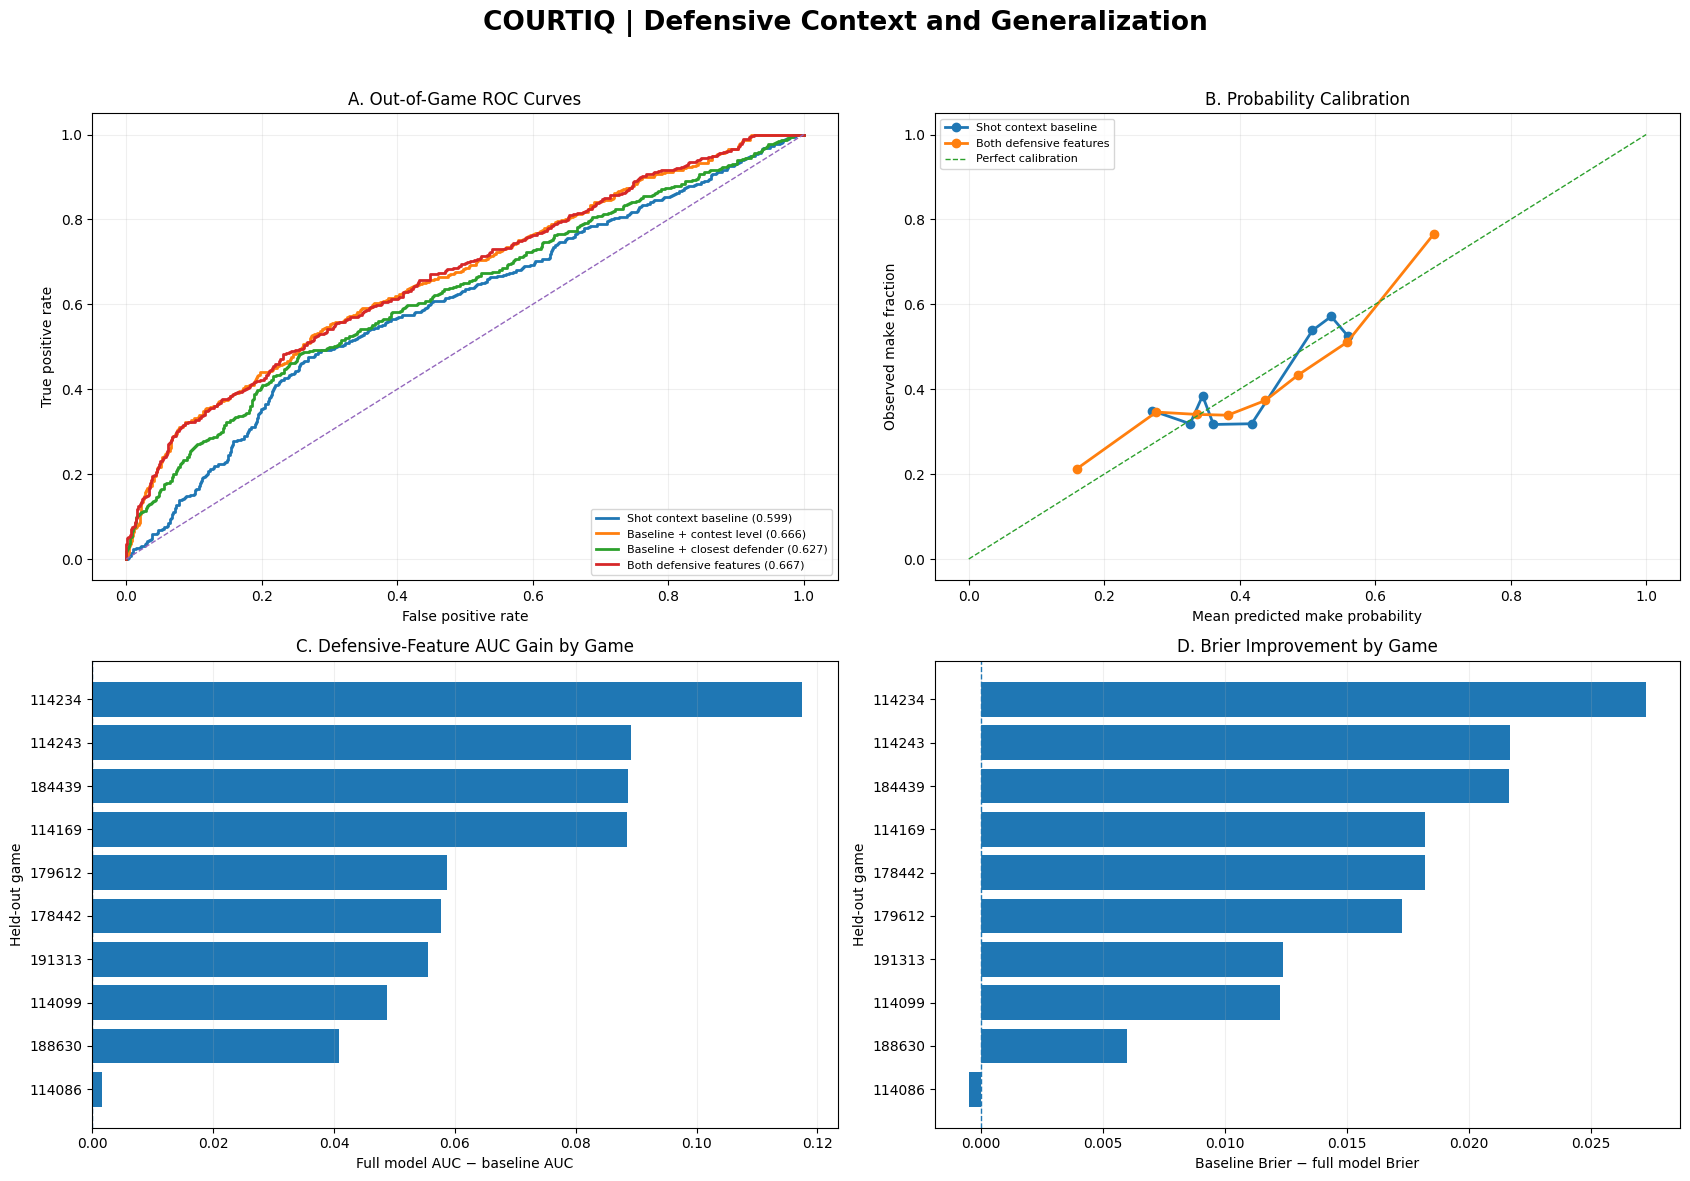


ROBUSTNESS AUDIT COMPLETE
Baseline AUC: 0.5986
Full model AUC: 0.6670
AUC gain: +0.0684
Baseline Brier: 0.2344
Full model Brier: 0.2187
Games with higher full-model AUC: 10/10
Games with better full-model Brier: 9/10

Research figure: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_robustness_research_figure.png
Output directory: /kaggle/working/courtiq_final_rebuild_20261020T150911Z


In [8]:

# ================================================================
# COURTIQ — ROBUSTNESS AUDIT + RESEARCH VISUALS v2.0
# Input: saved LOGO out-of-fold predictions
# Output: robustness tables, uncertainty estimates, publication plots
# ================================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    average_precision_score,
    roc_curve,
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

OUT = Path(
    "/kaggle/working/courtiq_final_rebuild_20261020T150911Z"
)
OOF_PATH = OUT / "courtiq_oof_predictions.csv"

if not OOF_PATH.exists():
    raise FileNotFoundError(f"Missing predictions: {OOF_PATH}")

oof = pd.read_csv(OOF_PATH)

TARGET = "target_made"
GAME = "source_game_id"

BASE = "prob_baseline_shot_context"
FULL = "prob_plus_both_defensive_features"

required = [TARGET, GAME, BASE, FULL]
missing = [c for c in required if c not in oof.columns]
if missing:
    raise ValueError(f"Missing columns in OOF predictions: {missing}")

# Use the two saved OOF columns to ensure this audit evaluates
# the predictions generated by the successful LOGO run.
y = pd.to_numeric(oof[TARGET], errors="raise").to_numpy(int)
games = oof[GAME].astype(str).to_numpy()

prob_cols = [
    c for c in oof.columns if c.startswith("prob_")
]
for col in prob_cols:
    oof[col] = pd.to_numeric(
        oof[col], errors="coerce"
    )

if oof[prob_cols].isna().any().any():
    raise ValueError("OOF predictions contain missing values.")

if not set(np.unique(y)).issubset({0, 1}):
    raise ValueError("Target must contain only binary 0/1 values.")

for col in prob_cols:
    if not oof[col].between(0, 1).all():
        raise ValueError(f"Probabilities outside [0, 1]: {col}")

print("=" * 76)
print("COURTIQ — ROBUSTNESS & LIMITATIONS AUDIT")
print("=" * 76)
print(f"Shots: {len(oof):,}")
print(f"Games: {len(np.unique(games))}")
print(f"Observed make rate: {y.mean():.4f}")

# ------------------------------------------------
# 1. Pooled OOF performance
# ------------------------------------------------
model_labels = {
    "prob_baseline_shot_context": "Shot context baseline",
    "prob_plus_contest_level": "Baseline + contest level",
    "prob_plus_closest_defender": "Baseline + closest defender",
    "prob_plus_both_defensive_features": "Both defensive features",
}

summary_rows = []

for col in prob_cols:
    p = oof[col].to_numpy(float)
    summary_rows.append({
        "model": model_labels.get(col, col),
        "prediction_column": col,
        "ROC_AUC": roc_auc_score(y, p),
        "Average_precision": average_precision_score(y, p),
        "Brier_score": brier_score_loss(y, p),
    })

summary = pd.DataFrame(summary_rows).sort_values(
    "ROC_AUC", ascending=False
)

print("\nPOOLED OUT-OF-GAME RESULTS")
print(summary.to_string(index=False))

summary.to_csv(
    OUT / "courtiq_robustness_summary.csv", index=False
)

# ------------------------------------------------
# 2. Per-game metrics
# ------------------------------------------------
game_rows = []

for game in sorted(np.unique(games)):
    idx = np.flatnonzero(games == game)
    yg = y[idx]

    row = {
        "game": game,
        "shots": len(idx),
        "observed_make_rate": float(yg.mean()),
    }

    for col in prob_cols:
        p = oof[col].to_numpy(float)[idx]
        label = model_labels.get(col, col)

        row[f"{label}_Brier"] = brier_score_loss(yg, p)
        row[f"{label}_AUC"] = (
            roc_auc_score(yg, p)
            if len(np.unique(yg)) == 2 else np.nan
        )

    game_rows.append(row)

per_game = pd.DataFrame(game_rows)
per_game.to_csv(
    OUT / "courtiq_per_game_robustness.csv", index=False
)

print("\nPER-GAME RESULTS")
print(per_game.to_string(index=False))

# ------------------------------------------------
# 3. Paired cluster bootstrap by game
# ------------------------------------------------
# Resample whole games, not individual shots, to preserve
# within-game dependence. These intervals are exploratory:
# there are only 10 game clusters.
rng = np.random.default_rng(20261020)
unique_games = np.unique(games)
n_boot = 5000

base_p = oof[BASE].to_numpy(float)
full_p = oof[FULL].to_numpy(float)

base_auc = roc_auc_score(y, base_p)
full_auc = roc_auc_score(y, full_p)

base_brier = brier_score_loss(y, base_p)
full_brier = brier_score_loss(y, full_p)

# Positive values favor the full model for both definitions:
# AUC gain = full - baseline; Brier improvement = baseline - full.
delta_auc = full_auc - base_auc
delta_brier = base_brier - full_brier

game_indices = {
    g: np.flatnonzero(games == g) for g in unique_games
}

boot_auc = []
boot_brier = []

for _ in range(n_boot):
    sampled_games = rng.choice(
        unique_games, size=len(unique_games), replace=True
    )

    # Repeated sampled games repeat their entire shot cluster.
    idx = np.concatenate([game_indices[g] for g in sampled_games])

    yb = y[idx]
    pb = base_p[idx]
    pf = full_p[idx]

    if len(np.unique(yb)) < 2:
        continue

    boot_auc.append(
        roc_auc_score(yb, pf) - roc_auc_score(yb, pb)
    )
    boot_brier.append(
        brier_score_loss(yb, pb) - brier_score_loss(yb, pf)
    )

boot_auc = np.asarray(boot_auc)
boot_brier = np.asarray(boot_brier)

def bootstrap_summary(name, point, values):
    lo, hi = np.quantile(values, [0.025, 0.975])
    return {
        "comparison": name,
        "observed_improvement": float(point),
        "bootstrap_95pct_low": float(lo),
        "bootstrap_95pct_high": float(hi),
        "bootstrap_probability_improvement_positive": float(
            np.mean(values > 0)
        ),
        "valid_replicates": int(len(values)),
        "requested_replicates": n_boot,
        "independent_game_clusters": int(len(unique_games)),
    }

bootstrap_results = pd.DataFrame([
    bootstrap_summary(
        "ROC-AUC gain: both features vs baseline",
        delta_auc, boot_auc
    ),
    bootstrap_summary(
        "Brier improvement: both features vs baseline",
        delta_brier, boot_brier
    ),
])

bootstrap_results.to_csv(
    OUT / "courtiq_cluster_bootstrap.csv", index=False
)

print("\nPAIRED GAME-CLUSTER BOOTSTRAP")
print(bootstrap_results.to_string(index=False))

# ------------------------------------------------
# 4. Improvement by held-out game
# ------------------------------------------------
per_game["AUC_gain_full_minus_baseline"] = (
    per_game["Both defensive features_AUC"]
    - per_game["Shot context baseline_AUC"]
)

per_game["Brier_improvement"] = (
    per_game["Shot context baseline_Brier"]
    - per_game["Both defensive features_Brier"]
)

per_game.to_csv(
    OUT / "courtiq_per_game_robustness.csv", index=False
)

# ------------------------------------------------
# 5. Create four-panel research figure
# ------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(17, 12))
ax_roc, ax_cal, ax_auc, ax_brier = axes.ravel()

# Panel A — ROC curves from pooled OOF predictions
for col in prob_cols:
    p = oof[col].to_numpy(float)
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    label = model_labels.get(col, col)
    ax_roc.plot(fpr, tpr, linewidth=2, label=f"{label} ({auc:.3f})")

ax_roc.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax_roc.set_title("A. Out-of-Game ROC Curves")
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("True positive rate")
ax_roc.legend(fontsize=8, loc="lower right")
ax_roc.grid(alpha=0.2)

# Panel B — Reliability / calibration
for col in [BASE, FULL]:
    p = oof[col].to_numpy(float)
    frac_pos, mean_pred = calibration_curve(
        y, p, n_bins=8, strategy="quantile"
    )
    ax_cal.plot(
        mean_pred, frac_pos, marker="o", linewidth=2,
        label=model_labels[col]
    )

ax_cal.plot([0, 1], [0, 1], linestyle="--", linewidth=1,
            label="Perfect calibration")
ax_cal.set_title("B. Probability Calibration")
ax_cal.set_xlabel("Mean predicted make probability")
ax_cal.set_ylabel("Observed make fraction")
ax_cal.legend(fontsize=8)
ax_cal.grid(alpha=0.2)

# Panel C — Game-level AUC gain
plot_auc = per_game.dropna(
    subset=["AUC_gain_full_minus_baseline"]
).sort_values("AUC_gain_full_minus_baseline")

ax_auc.barh(
    plot_auc["game"],
    plot_auc["AUC_gain_full_minus_baseline"]
)
ax_auc.axvline(0, linestyle="--", linewidth=1)
ax_auc.set_title("C. Defensive-Feature AUC Gain by Game")
ax_auc.set_xlabel("Full model AUC − baseline AUC")
ax_auc.set_ylabel("Held-out game")
ax_auc.grid(axis="x", alpha=0.2)

# Panel D — Game-level Brier improvement
plot_brier = per_game.sort_values("Brier_improvement")

ax_brier.barh(
    plot_brier["game"],
    plot_brier["Brier_improvement"]
)
ax_brier.axvline(0, linestyle="--", linewidth=1)
ax_brier.set_title("D. Brier Improvement by Game")
ax_brier.set_xlabel("Baseline Brier − full model Brier")
ax_brier.set_ylabel("Held-out game")
ax_brier.grid(axis="x", alpha=0.2)

fig.suptitle(
    "COURTIQ | Defensive Context and Generalization",
    fontsize=19,
    fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = OUT / "courtiq_robustness_research_figure.png"
fig.savefig(figure_path, dpi=240, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. Export a transparent interpretation
# ------------------------------------------------
interpretation = {
    "shots": int(len(oof)),
    "games": int(len(unique_games)),
    "observed_make_rate": float(y.mean()),
    "baseline_auc": float(base_auc),
    "full_model_auc": float(full_auc),
    "auc_gain": float(delta_auc),
    "baseline_brier": float(base_brier),
    "full_model_brier": float(full_brier),
    "brier_improvement": float(delta_brier),
    "games_full_model_auc_better": int(
        (per_game["AUC_gain_full_minus_baseline"] > 0).sum()
    ),
    "games_full_model_brier_better": int(
        (per_game["Brier_improvement"] > 0).sum()
    ),
    "bootstrap_method": "resample complete games with replacement",
    "bootstrap_replicates_requested": n_boot,
    "bootstrap_replicates_valid": int(len(boot_auc)),
    "limitations": [
        "Only 10 independent game clusters are available.",
        "Cluster bootstrap intervals are exploratory with so few games.",
        "Results apply to these sampled games, not automatically to all basketball.",
        "Pooled OOF calibration does not establish calibration on future seasons.",
        "No causal conclusion about the effect of defensive pressure is warranted.",
    ],
}

with open(
    OUT / "courtiq_robustness_interpretation.json", "w"
) as f:
    json.dump(interpretation, f, indent=2)

with open(
    OUT / "COURTIQ_ROBUSTNESS_AUDIT.txt", "w"
) as f:
    f.write("COURTIQ ROBUSTNESS AUDIT\n")
    f.write("=" * 60 + "\n\n")
    f.write(pd.DataFrame([interpretation]).to_string(index=False))
    f.write("\n\nBOOTSTRAP RESULTS\n")
    f.write(bootstrap_results.to_string(index=False))
    f.write("\n\nPER-GAME RESULTS\n")
    f.write(per_game.to_string(index=False))
    f.write("\n")

print("\n" + "=" * 76)
print("ROBUSTNESS AUDIT COMPLETE")
print("=" * 76)
print(f"Baseline AUC: {base_auc:.4f}")
print(f"Full model AUC: {full_auc:.4f}")
print(f"AUC gain: {delta_auc:+.4f}")
print(f"Baseline Brier: {base_brier:.4f}")
print(f"Full model Brier: {full_brier:.4f}")
print(
    "Games with higher full-model AUC: "
    f"{interpretation['games_full_model_auc_better']}/{len(unique_games)}"
)
print(
    "Games with better full-model Brier: "
    f"{interpretation['games_full_model_brier_better']}/{len(unique_games)}"
)
print(f"\nResearch figure: {figure_path}")
print(f"Output directory: {OUT}")

In [11]:

# ================================================================
# COURTIQ — CELL 2: FEATURE ENGINEERING & DATA VALIDATION
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
INPUT = OUT / "tables" / "courtiq_shot_dataset.csv"
OUTPUT = OUT / "courtiq_context_engineered_dataset.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Recovered dataset not found: {INPUT}")

df = pd.read_csv(INPUT)

required = ["source_game_id", "target_made", "distance", "three",
            "shotType", "shotClock", "contestLevel", "closestDefDist",
            "event_id"]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Preserve a unique row identity throughout all downstream evaluation.
df = df.reset_index(drop=True)
df["shot_row_id"] = np.arange(len(df), dtype=np.int64)

# Validate the target.
df["target_made"] = pd.to_numeric(df["target_made"], errors="coerce")
if df["target_made"].isna().any():
    raise ValueError("Some target_made values are missing or nonnumeric.")

if not set(df["target_made"].unique()).issubset({0, 1}):
    raise ValueError("target_made must contain only 0 and 1.")

df["target_made"] = df["target_made"].astype(int)

# Validate game grouping.
if df["source_game_id"].isna().any():
    raise ValueError("source_game_id contains missing values.")

# Convert numeric inputs without discarding rows.
numeric_cols = ["distance", "three", "shotClock", "closestDefDist"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Normalize categorical columns.
for col in ["shotType", "contestLevel"]:
    df[col] = df[col].astype("object")
    df[col] = df[col].where(pd.notna(df[col]), np.nan)

# Feature engineering. Imputation happens inside each training fold later.
df["distance_squared"] = df["distance"] ** 2
df["distance_x_defender_distance"] = (
    df["distance"] * df["closestDefDist"]
)
df["shot_clock_urgency"] = 1.0 / (
    df["shotClock"].clip(lower=0) + 1.0
)
df["three_x_shot_clock"] = df["three"] * df["shotClock"]
df["defender_proximity"] = 1.0 / (
    df["closestDefDist"].clip(lower=0) + 1.0
)

# Metadata and reproducibility checks.
if df["shot_row_id"].duplicated().any():
    raise AssertionError("shot_row_id is not unique.")

if df["event_id"].isna().any():
    print("WARNING: event_id has missing values; shot_row_id remains unique.")

OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT, index=False)

print("=" * 72)
print("COURTIQ — FEATURE ENGINEERING COMPLETE")
print("=" * 72)
print(f"Input:  {INPUT}")
print(f"Output: {OUTPUT}")
print(f"Shots:  {len(df):,}")
print(f"Games:  {df['source_game_id'].nunique():,}")
print(f"Make rate: {df['target_made'].mean():.4f}")
print(f"Unique row IDs: {df['shot_row_id'].nunique():,}")
print("\nMissingness in original predictors:")
print(
    df[required[2:8]]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .rename("missing_pct")
    .to_frame()
)
print("\nEngineered features:")
print([
    "distance_squared",
    "distance_x_defender_distance",
    "shot_clock_urgency",
    "three_x_shot_clock",
    "defender_proximity",
])
print("\nFirst five rows:")
display(df.head())

COURTIQ — FEATURE ENGINEERING COMPLETE
Input:  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/tables/courtiq_shot_dataset.csv
Output: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_context_engineered_dataset.csv
Shots:  1,459
Games:  10
Make rate: 0.4154
Unique row IDs: 1,459

Missingness in original predictors:
                missing_pct
distance               1.78
three                  0.00
shotType               1.78
shotClock              0.48
contestLevel           1.78
closestDefDist         1.78

Engineered features:
['distance_squared', 'distance_x_defender_distance', 'shot_clock_urgency', 'three_x_shot_clock', 'defender_proximity']

First five rows:


,source_game_id,target_made,distance,three,shotType,shotClock,contestLevel,closestDefDist,event_id,shot_row_id,distance_squared,distance_x_defender_distance,shot_clock_urgency,three_x_shot_clock,defender_proximity
0,114086,0,2.367698,0,layup,7.16,plus,0.554495,shot-114086-1-0,0,5.605993,1.312878,0.122549,0.0,0.643296
1,114086,1,8.471460,0,post,12.92,plus,2.611572,shot-114086-1-1,1,71.765633,22.123827,0.071839,0.0,0.276888
2,114086,0,17.317250,0,jumper,6.52,plus,4.946294,shot-114086-1-2,2,299.887151,85.656212,0.132979,0.0,0.168172
3,114086,0,4.778515,0,post,10.48,plus,1.412428,shot-114086-1-3,3,22.834209,6.749311,0.087108,0.0,0.414520
4,114086,0,5.302887,0,jumper,12.44,average,1.438586,shot-114086-1-4,4,28.120616,7.628659,0.074405,0.0,0.410074


In [12]:

# ================================================================
# COURTIQ — CELL 3: LEAKAGE-SAFE MODEL EVALUATION
# Leave-One-Game-Out CV | 5 models | Shot-level prediction tracking
# ================================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, accuracy_score, precision_score, recall_score, f1_score
)

warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
INPUT = OUT / "courtiq_context_engineered_dataset.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Run Cell 2 first. Missing: {INPUT}")

df = pd.read_csv(INPUT).reset_index(drop=True)

required = [
    "shot_row_id", "source_game_id", "target_made",
    "distance", "three", "shotType", "shotClock",
    "contestLevel", "closestDefDist", "distance_squared",
    "distance_x_defender_distance", "shot_clock_urgency",
    "three_x_shot_clock", "defender_proximity"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["shot_row_id"] = pd.to_numeric(
    df["shot_row_id"], errors="raise"
).astype(int)
df["target_made"] = pd.to_numeric(
    df["target_made"], errors="raise"
).astype(int)

if df["shot_row_id"].duplicated().any():
    raise ValueError("shot_row_id must be unique.")
if df["source_game_id"].isna().any():
    raise ValueError("Game IDs cannot be missing.")
if not set(df["target_made"].unique()).issubset({0, 1}):
    raise ValueError("target_made must contain only 0 and 1.")

# Ensure all numeric columns are truly numeric.
numeric_columns = [
    "distance", "three", "shotClock", "closestDefDist",
    "distance_squared", "distance_x_defender_distance",
    "shot_clock_urgency", "three_x_shot_clock", "defender_proximity"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

categorical_columns = ["shotType", "contestLevel"]
for col in categorical_columns:
    df[col] = df[col].where(df[col].notna(), np.nan)

# Each model uses only the feature groups specified below.
model_features = {
    "baseline_shot_context": [
        "distance", "three", "shotType", "shotClock"
    ],
    "plus_contest_level": [
        "distance", "three", "shotType", "shotClock", "contestLevel"
    ],
    "plus_closest_defender": [
        "distance", "three", "shotType", "shotClock", "closestDefDist"
    ],
    "both_defensive_features": [
        "distance", "three", "shotType", "shotClock",
        "contestLevel", "closestDefDist"
    ],
    "engineered_context": [
        "distance", "three", "shotType", "shotClock",
        "contestLevel", "closestDefDist", "distance_squared",
        "distance_x_defender_distance", "shot_clock_urgency",
        "three_x_shot_clock", "defender_proximity"
    ],
}

def build_pipeline(features, seed=42):
    cats = [c for c in features if c in categorical_columns]
    nums = [c for c in features if c in numeric_columns]
    transformers = []

    if nums:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            nums
        ))

    if cats:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant", fill_value="__MISSING__"
                )),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cats
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=3,
        max_features="sqrt",
        class_weight="balanced",
        random_state=seed,
        n_jobs=-1
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

games = list(pd.unique(df["source_game_id"]))
y = df["target_made"].to_numpy()

if len(games) < 2:
    raise ValueError("At least two games are needed for cross-validation.")

prediction_rows = []
fold_rows = []

print("=" * 76)
print("COURTIQ — LEAVE-ONE-GAME-OUT EVALUATION")
print("=" * 76)
print(f"Shots: {len(df):,} | Independent game groups: {len(games)}")
print(f"Models to evaluate: {len(model_features)}")
print("Training and testing are separated by complete game.")

for model_name, features in model_features.items():
    print(f"\n[{model_name}]")

    for fold, heldout_game in enumerate(games, start=1):
        test_mask = df["source_game_id"].eq(heldout_game).to_numpy()
        test_idx = np.flatnonzero(test_mask)
        train_idx = np.flatnonzero(~test_mask)

        X_train = df.iloc[train_idx][features].copy()
        X_test = df.iloc[test_idx][features].copy()
        y_train = y[train_idx]
        y_test = y[test_idx]

        fold_base = {
            "model": model_name,
            "fold": fold,
            "heldout_game": heldout_game,
            "n_train": len(train_idx),
            "n_test": len(test_idx),
            "heldout_make_rate": float(y_test.mean()),
        }

        if len(np.unique(y_train)) < 2:
            fold_rows.append({
                **fold_base,
                "heldout_auc": np.nan,
                "heldout_brier": np.nan,
                "status": "SKIPPED: training data has one class"
            })
            continue

        try:
            pipeline = build_pipeline(features, seed=100 + fold)
            pipeline.fit(X_train, y_train)
            probs = pipeline.predict_proba(X_test)[:, 1]
            hard = (probs >= 0.5).astype(int)

            for j, pos in enumerate(test_idx):
                prediction_rows.append({
                    "shot_row_id": int(df.iloc[pos]["shot_row_id"]),
                    "source_game_id": df.iloc[pos]["source_game_id"],
                    "target_made": int(y_test[j]),
                    "model": model_name,
                    "probability": float(probs[j]),
                    "predicted_made_0_5": int(hard[j]),
                    "heldout_fold": fold
                })

            auc = (
                float(roc_auc_score(y_test, probs))
                if len(np.unique(y_test)) == 2 else np.nan
            )

            fold_rows.append({
                **fold_base,
                "heldout_auc": auc,
                "heldout_brier": float(brier_score_loss(y_test, probs)),
                "status": "OK"
            })

            print(
                f"  Fold {fold:02d}/{len(games)} | game={heldout_game} "
                f"| shots={len(test_idx)} | AUC={auc:.4f}"
                if np.isfinite(auc)
                else f"  Fold {fold:02d}/{len(games)} | game={heldout_game} "
                     f"| shots={len(test_idx)} | AUC=N/A"
            )

        except Exception as exc:
            fold_rows.append({
                **fold_base,
                "heldout_auc": np.nan,
                "heldout_brier": np.nan,
                "status": f"ERROR: {type(exc).__name__}: {exc}"
            })
            print(f"  ERROR on game {heldout_game}: {exc}")

pred = pd.DataFrame(prediction_rows)
fold_results = pd.DataFrame(fold_rows)

if pred.empty:
    raise RuntimeError("No predictions produced. Check fold errors above.")

if pred.duplicated(["shot_row_id", "model"]).any():
    raise AssertionError("Duplicate shot/model predictions found.")

# Pooled out-of-fold metrics.
summary_rows = []
for model_name in model_features:
    part = pred[pred["model"] == model_name]
    if part.empty:
        continue

    actual = part["target_made"].to_numpy()
    probability = part["probability"].to_numpy()
    predicted = part["predicted_made_0_5"].to_numpy()

    summary_rows.append({
        "model": model_name,
        "shots": len(part),
        "games": part["source_game_id"].nunique(),
        "make_rate": actual.mean(),
        "roc_auc": (
            roc_auc_score(actual, probability)
            if len(np.unique(actual)) == 2 else np.nan
        ),
        "average_precision": average_precision_score(actual, probability),
        "brier_score": brier_score_loss(actual, probability),
        "log_loss": log_loss(
            actual, np.clip(probability, 1e-7, 1 - 1e-7), labels=[0, 1]
        ),
        "accuracy_0_5": accuracy_score(actual, predicted),
        "precision_0_5": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall_0_5": recall_score(actual, predicted, zero_division=0),
        "f1_0_5": f1_score(actual, predicted, zero_division=0)
    })

summary = pd.DataFrame(summary_rows).sort_values(
    "roc_auc", ascending=False, na_position="last"
)

# Wide-format OOF predictions safely pivot on unique shot identity.
wide = pred.pivot(
    index=["shot_row_id", "source_game_id", "target_made"],
    columns="model",
    values="probability"
).reset_index()
wide.columns.name = None
wide = wide.rename(columns={
    col: f"prob_{col}" for col in model_features if col in wide.columns
})

# Save all outputs.
paths = {
    "predictions_long": OUT / "courtiq_logo_predictions_v2.csv",
    "predictions_wide": OUT / "courtiq_oof_predictions_v2.csv",
    "metrics": OUT / "courtiq_logo_metrics_v2.csv",
    "folds": OUT / "courtiq_logo_fold_results_v2.csv",
}
pred.to_csv(paths["predictions_long"], index=False)
wide.to_csv(paths["predictions_wide"], index=False)
summary.to_csv(paths["metrics"], index=False)
fold_results.to_csv(paths["folds"], index=False)

print("\n" + "=" * 76)
print("POOLED OUT-OF-FOLD METRICS")
print("=" * 76)
display(summary.round(4))

print("\nFOLD STATUS")
display(
    fold_results.groupby(["model", "status"], dropna=False)
    .size()
    .rename("fold_count")
    .reset_index()
)

print("\nALIGNMENT AUDIT")
print(f"Input shots: {df['shot_row_id'].nunique():,}")
print(f"Long-form predictions: {len(pred):,}")
print(f"Unique shot/model pairs: {pred[['shot_row_id','model']].drop_duplicates().shape[0]:,}")
print(f"Wide-form rows: {len(wide):,}")
print(f"Wide-form unique shot IDs: {wide['shot_row_id'].nunique():,}")

assert wide["shot_row_id"].is_unique
assert pred["shot_row_id"].notna().all()
assert pred["probability"].between(0, 1).all()

print("\nOUTPUT FILES")
for label, path in paths.items():
    print(f"{label}: {path}")

print(
    "\nInterpretation note: this is exploratory validation on "
    f"{len(games)} games. It does not establish player-level skill "
    "improvement or general NBA-wide performance."
)

COURTIQ — LEAVE-ONE-GAME-OUT EVALUATION
Shots: 1,459 | Independent game groups: 10
Models to evaluate: 5
Training and testing are separated by complete game.

[baseline_shot_context]
  Fold 01/10 | game=114086 | shots=139 | AUC=0.5427
  Fold 02/10 | game=114099 | shots=150 | AUC=0.6236
  Fold 03/10 | game=114169 | shots=148 | AUC=0.5894
  Fold 04/10 | game=114234 | shots=144 | AUC=0.5772
  Fold 05/10 | game=114243 | shots=159 | AUC=0.6201
  Fold 06/10 | game=178442 | shots=158 | AUC=0.6350
  Fold 07/10 | game=179612 | shots=145 | AUC=0.6595
  Fold 08/10 | game=184439 | shots=142 | AUC=0.6002
  Fold 09/10 | game=188630 | shots=133 | AUC=0.5545
  Fold 10/10 | game=191313 | shots=141 | AUC=0.5251

[plus_contest_level]
  Fold 01/10 | game=114086 | shots=139 | AUC=0.5783
  Fold 02/10 | game=114099 | shots=150 | AUC=0.6742
  Fold 03/10 | game=114169 | shots=148 | AUC=0.6612
  Fold 04/10 | game=114234 | shots=144 | AUC=0.7046
  Fold 05/10 | game=114243 | shots=159 | AUC=0.6972
  Fold 06/10 | 

,model,shots,games,make_rate,roc_auc,average_precision,brier_score,log_loss,accuracy_0_5,precision_0_5,recall_0_5,f1_0_5
1,plus_contest_level,1459,10,0.4154,0.6549,0.6128,0.2237,0.6344,0.6429,0.5816,0.5000,0.5377
3,both_defensive_features,1459,10,0.4154,0.6510,0.6172,0.2238,0.6334,0.6388,0.5764,0.4917,0.5307
4,engineered_context,1459,10,0.4154,0.6502,0.6153,0.2249,0.6367,0.6319,0.5638,0.5033,0.5318
2,plus_closest_defender,1459,10,0.4154,0.6045,0.5613,0.2380,0.6673,0.5984,0.5166,0.5149,0.5157
0,baseline_shot_context,1459,10,0.4154,0.5902,0.4980,0.2434,0.6795,0.5853,0.5008,0.5116,0.5061



FOLD STATUS


,model,status,fold_count
0,baseline_shot_context,OK,10
1,both_defensive_features,OK,10
2,engineered_context,OK,10
3,plus_closest_defender,OK,10
4,plus_contest_level,OK,10



ALIGNMENT AUDIT
Input shots: 1,459
Long-form predictions: 7,295
Unique shot/model pairs: 7,295
Wide-form rows: 1,459
Wide-form unique shot IDs: 1,459

OUTPUT FILES
predictions_long: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_logo_predictions_v2.csv
predictions_wide: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_oof_predictions_v2.csv
metrics: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_logo_metrics_v2.csv
folds: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_logo_fold_results_v2.csv

Interpretation note: this is exploratory validation on 10 games. It does not establish player-level skill improvement or general NBA-wide performance.


COURTIQ — VISUALIZATION STUDIO
OOF shots: 1,459
Games: 10
Models: 5
Best ROC-AUC: Context + contest
Best ROC-AUC value: 0.6549
Best Brier score: 0.2237
These are exploratory results from a 10-game dataset.
Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/01_model_leaderboard.png


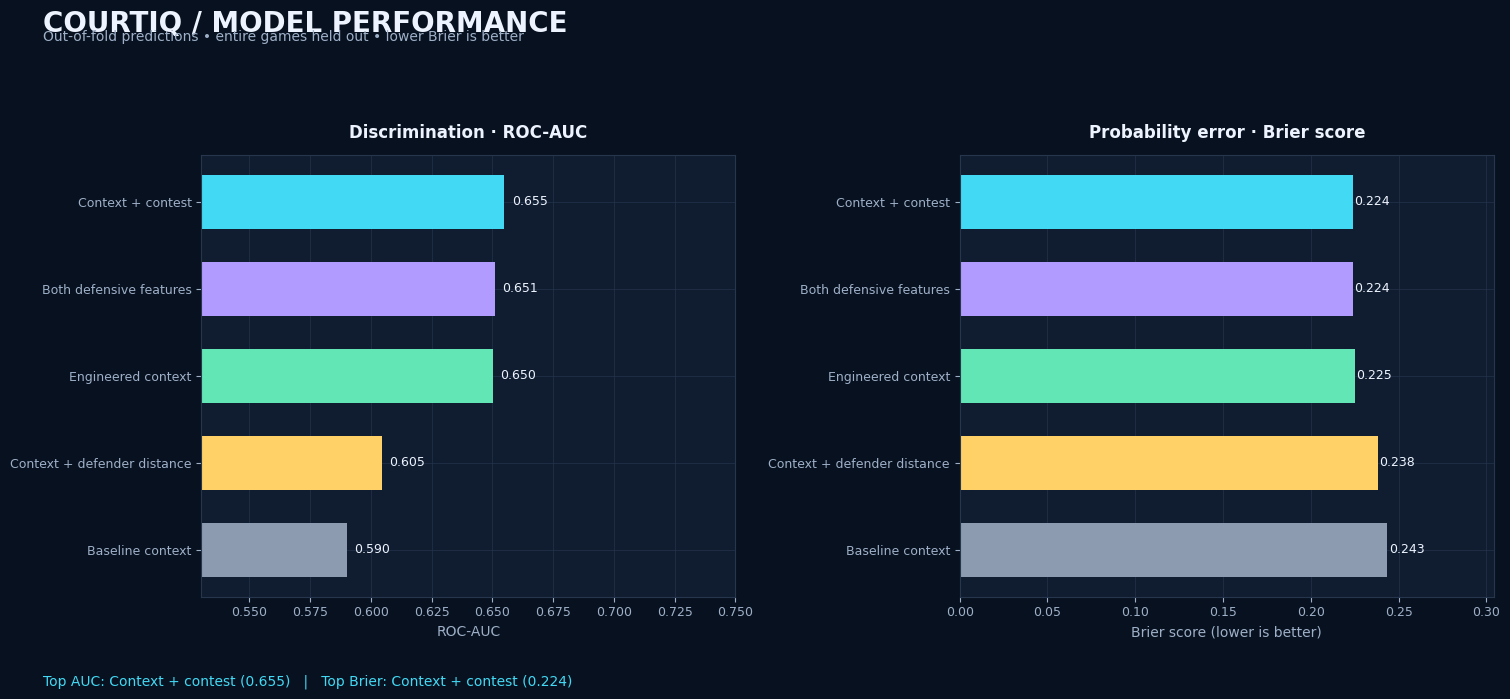

Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/02_roc_precision_recall.png


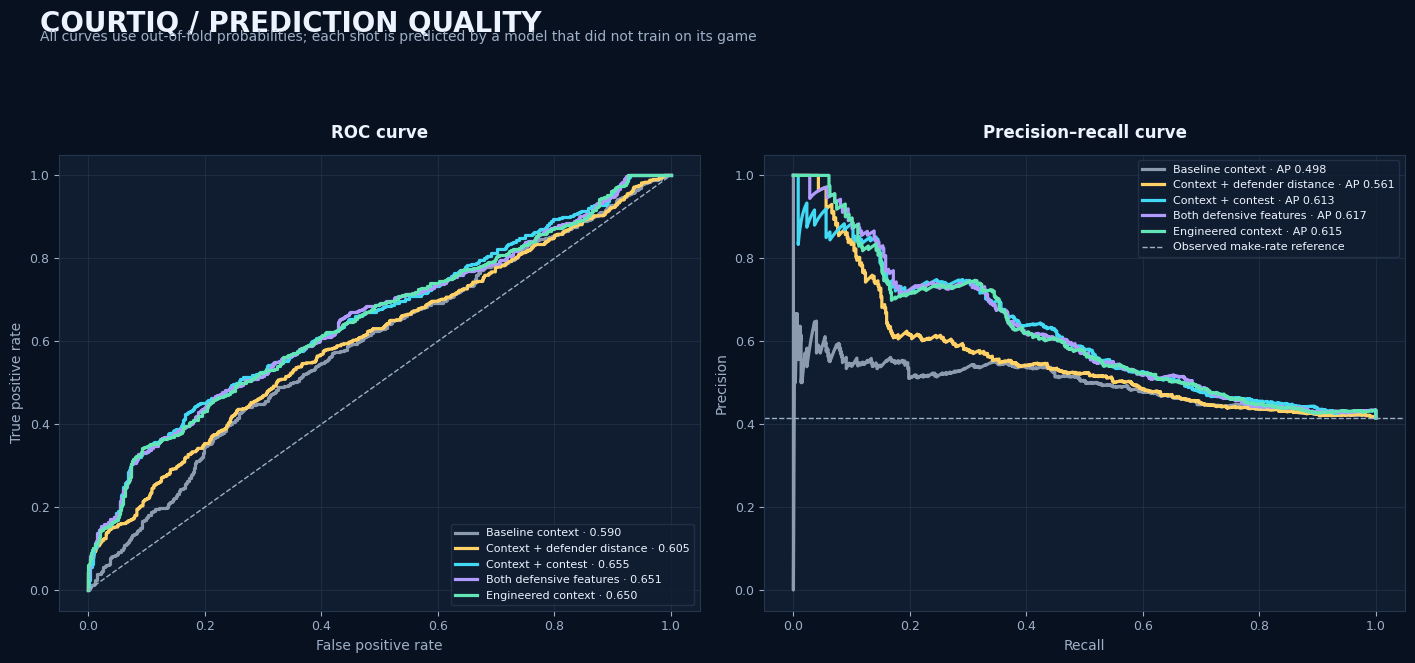

Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/03_calibration_audit.png


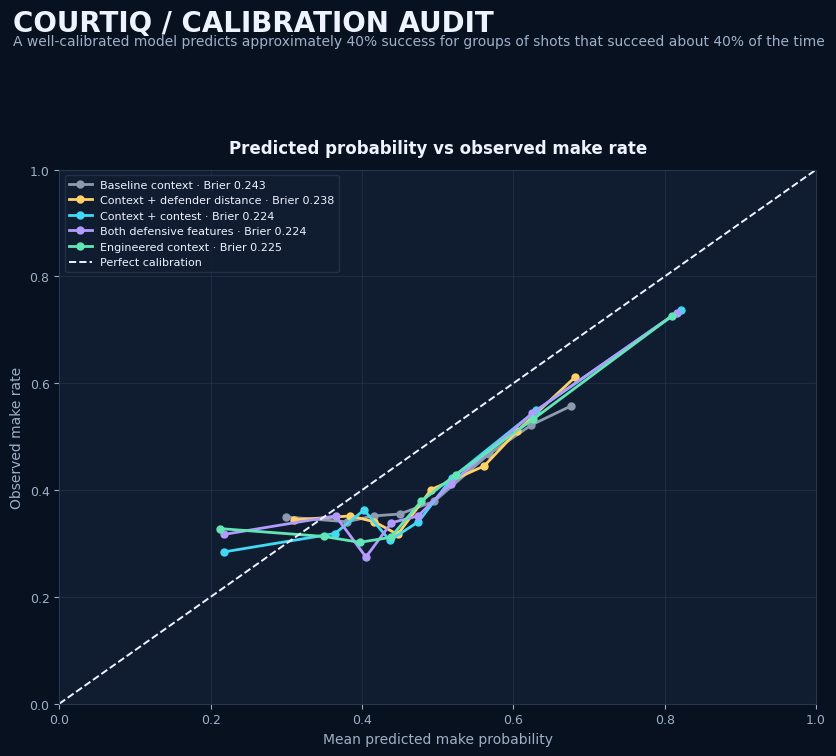

Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/04_game_robustness_heatmap.png


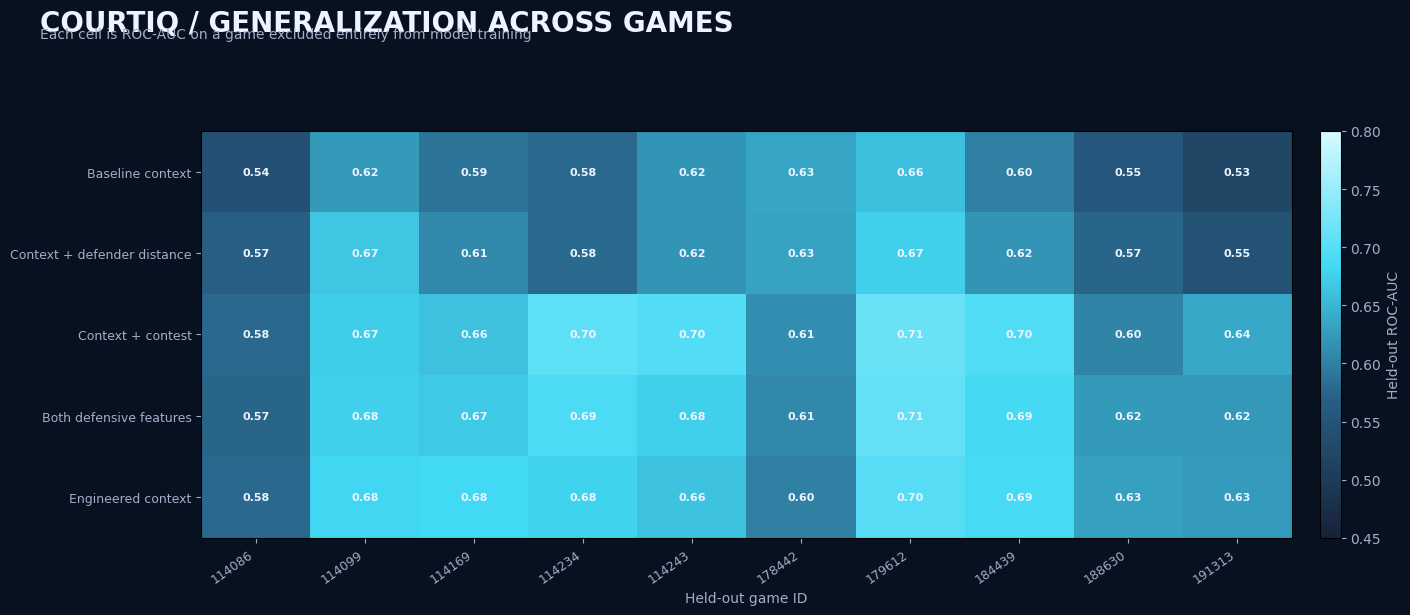

Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/05_per_game_auc_lift.png


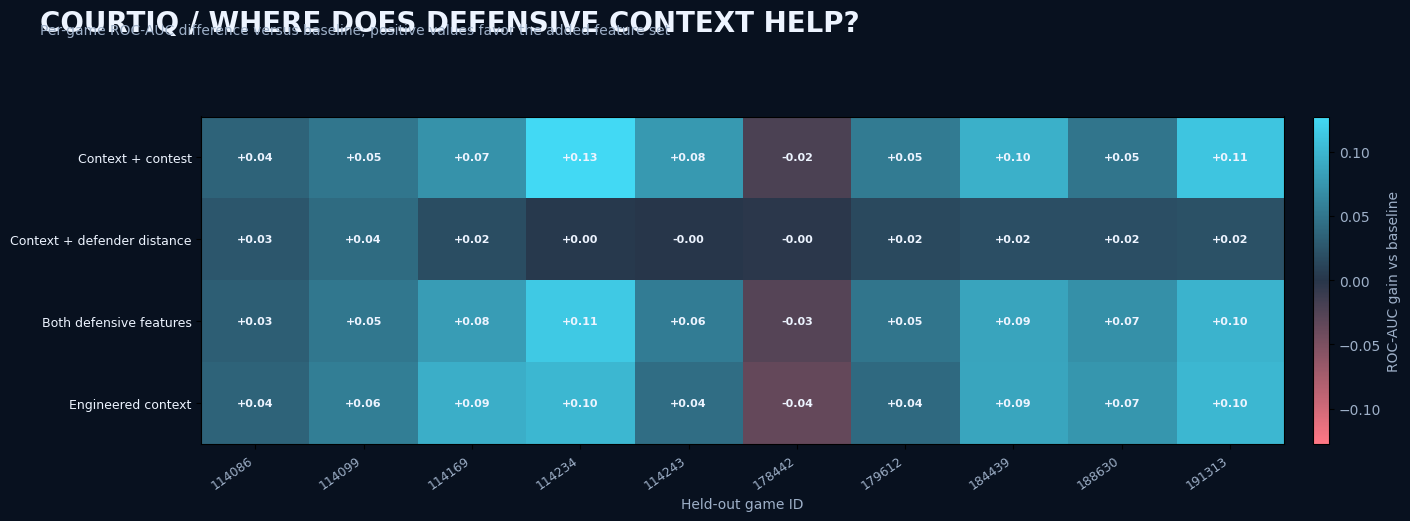

Saved: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/06_probability_distribution.png


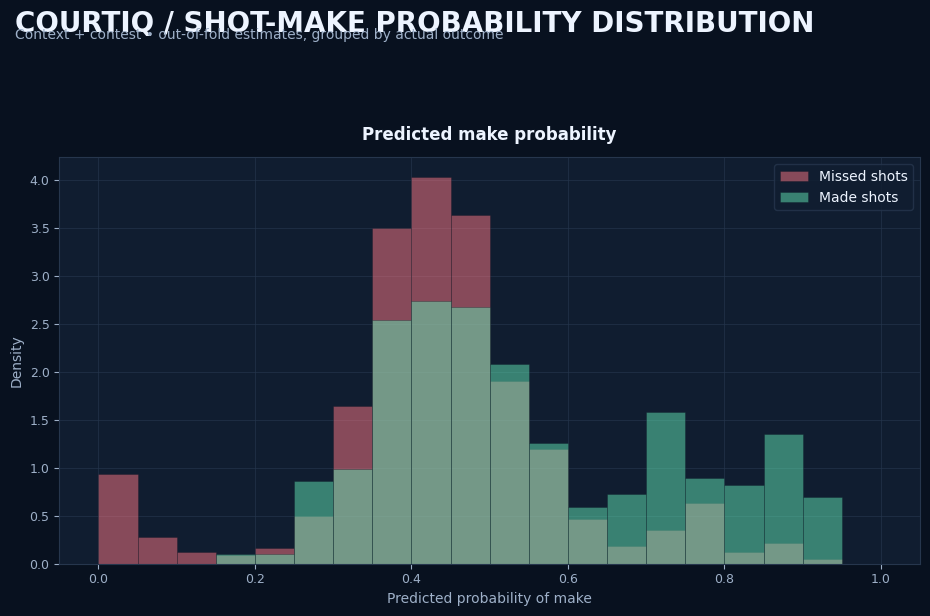


COURTIQ — VISUALIZATION EXPORT COMPLETE
HTML report: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_research_dashboard.html
Visual directory: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals
Metrics table: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visual_metrics_verified.csv
Per-game metrics: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_per_game_metrics_v2.csv
Per-game AUC lift: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_per_game_auc_lift_v2.csv

Files created:
  01_model_leaderboard.png (172.8 KB)
  02_roc_precision_recall.png (351.0 KB)
  03_calibration_audit.png (226.9 KB)
  04_game_robustness_heatmap.png (222.8 KB)
  05_per_game_auc_lift.png (198.6 KB)
  06_probability_distribution.png (108.0 KB)

Open the HTML report in Kaggle's file viewer: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_research_dashboard.html


In [13]:

# =====================================================================
# COURTIQ — CELL 4: RESEARCH VISUALIZATION STUDIO
# Publication-quality plots | Robustness | Calibration | HTML dashboard
# =====================================================================

from pathlib import Path
import base64
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    roc_curve, roc_auc_score, brier_score_loss,
    precision_recall_curve, average_precision_score
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

OUT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
METRICS_PATH = OUT / "courtiq_logo_metrics_v2.csv"
PRED_PATH = OUT / "courtiq_logo_predictions_v2.csv"
FOLDS_PATH = OUT / "courtiq_logo_fold_results_v2.csv"

for p in [METRICS_PATH, PRED_PATH, FOLDS_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing Cell 3 output: {p}")

metrics = pd.read_csv(METRICS_PATH)
pred = pd.read_csv(PRED_PATH)
folds = pd.read_csv(FOLDS_PATH)

required_pred = {
    "shot_row_id", "source_game_id", "target_made",
    "model", "probability", "predicted_made_0_5"
}
if not required_pred.issubset(pred.columns):
    raise ValueError(f"Prediction file missing: {required_pred - set(pred.columns)}")

if pred.duplicated(["shot_row_id", "model"]).any():
    raise ValueError("Duplicate shot/model predictions detected.")

if not pred["probability"].between(0, 1).all():
    raise ValueError("Probabilities outside [0, 1].")

OUT.mkdir(parents=True, exist_ok=True)
FIGDIR = OUT / "courtiq_visuals"
FIGDIR.mkdir(parents=True, exist_ok=True)

# Visual identity
BG = "#08111F"
PANEL = "#101D30"
GRID = "#26364D"
TEXT = "#EDF4FF"
MUTED = "#9EB0C8"
CYAN = "#42D9F4"
BLUE = "#6295FF"
PURPLE = "#B29BFF"
GOLD = "#FFD166"
GREEN = "#62E6B5"
RED = "#FF7885"

PALETTE = {
    "baseline_shot_context": "#8C9BB0",
    "plus_contest_level": CYAN,
    "plus_closest_defender": GOLD,
    "both_defensive_features": PURPLE,
    "engineered_context": GREEN,
}

DISPLAY_NAMES = {
    "baseline_shot_context": "Baseline context",
    "plus_contest_level": "Context + contest",
    "plus_closest_defender": "Context + defender distance",
    "both_defensive_features": "Both defensive features",
    "engineered_context": "Engineered context",
}

MODEL_ORDER = [
    "baseline_shot_context",
    "plus_closest_defender",
    "plus_contest_level",
    "both_defensive_features",
    "engineered_context",
]

def style_ax(ax, title=None):
    ax.set_facecolor(PANEL)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(MUTED)
    ax.yaxis.label.set_color(MUTED)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    ax.grid(True, color=GRID, alpha=0.65, linewidth=0.7)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, color=TEXT, fontsize=12, fontweight="bold", pad=12)

def style_fig(fig, title, subtitle=None):
    fig.patch.set_facecolor(BG)
    fig.suptitle(title, color=TEXT, fontsize=20, fontweight="bold",
                 x=0.06, ha="left", y=0.98)
    if subtitle:
        fig.text(0.06, 0.935, subtitle, color=MUTED, fontsize=10)

def save_fig(fig, filename):
    path = FIGDIR / filename
    fig.savefig(path, dpi=220, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    print("Saved:", path)
    return path

# Rebuild summary metrics from raw OOF predictions for consistency.
summary_rows = []
for model in MODEL_ORDER:
    part = pred[pred["model"] == model].copy()
    if part.empty:
        continue
    y = part["target_made"].astype(int).to_numpy()
    p = part["probability"].to_numpy()
    summary_rows.append({
        "model": model,
        "shots": len(part),
        "games": part["source_game_id"].nunique(),
        "roc_auc": roc_auc_score(y, p),
        "average_precision": average_precision_score(y, p),
        "brier_score": brier_score_loss(y, p),
        "make_rate": y.mean(),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "courtiq_visual_metrics_verified.csv", index=False)

baseline_row = summary.loc[
    summary["model"] == "baseline_shot_context"
].iloc[0]
best_auc_row = summary.loc[summary["roc_auc"].idxmax()]
best_brier_row = summary.loc[summary["brier_score"].idxmin()]

auc_gain = best_auc_row["roc_auc"] - baseline_row["roc_auc"]
brier_gain = baseline_row["brier_score"] - best_brier_row["brier_score"]

print("=" * 76)
print("COURTIQ — VISUALIZATION STUDIO")
print("=" * 76)
print(f"OOF shots: {pred['shot_row_id'].nunique():,}")
print(f"Games: {pred['source_game_id'].nunique():,}")
print(f"Models: {pred['model'].nunique()}")
print(f"Best ROC-AUC: {DISPLAY_NAMES.get(best_auc_row['model'], best_auc_row['model'])}")
print(f"Best ROC-AUC value: {best_auc_row['roc_auc']:.4f}")
print(f"Best Brier score: {best_brier_row['brier_score']:.4f}")
print("These are exploratory results from a 10-game dataset.")

# ---------------------------------------------------------------------
# FIGURE 1 — Executive model leaderboard
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
style_fig(
    fig,
    "COURTIQ / MODEL PERFORMANCE",
    "Out-of-fold predictions • entire games held out • lower Brier is better"
)

plot_data = summary.sort_values("roc_auc", ascending=True)

ax = axes[0]
bars = ax.barh(
    [DISPLAY_NAMES.get(m, m) for m in plot_data["model"]],
    plot_data["roc_auc"],
    color=[PALETTE.get(m, BLUE) for m in plot_data["model"]],
    height=0.62
)
style_ax(ax, "Discrimination · ROC-AUC")
ax.set_xlim(max(0, plot_data["roc_auc"].min() - 0.06), 0.75)
ax.set_xlabel("ROC-AUC")
for bar, val in zip(bars, plot_data["roc_auc"]):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", color=TEXT, fontsize=9)

ax = axes[1]
plot_brier = summary.sort_values("brier_score", ascending=False)
bars = ax.barh(
    [DISPLAY_NAMES.get(m, m) for m in plot_brier["model"]],
    plot_brier["brier_score"],
    color=[PALETTE.get(m, BLUE) for m in plot_brier["model"]],
    height=0.62
)
style_ax(ax, "Probability error · Brier score")
ax.set_xlabel("Brier score (lower is better)")
ax.set_xlim(0, max(plot_brier["brier_score"]) * 1.25)
for bar, val in zip(bars, plot_brier["brier_score"]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", color=TEXT, fontsize=9)

fig.text(
    0.06, 0.015,
    f"Top AUC: {DISPLAY_NAMES.get(best_auc_row['model'])} ({best_auc_row['roc_auc']:.3f})"
    f"   |   Top Brier: {DISPLAY_NAMES.get(best_brier_row['model'])} "
    f"({best_brier_row['brier_score']:.3f})",
    color=CYAN, fontsize=10
)
fig.tight_layout(rect=[0.03, 0.06, 0.98, 0.90])
leaderboard_path = save_fig(fig, "01_model_leaderboard.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# FIGURE 2 — ROC and precision-recall curves
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
style_fig(
    fig,
    "COURTIQ / PREDICTION QUALITY",
    "All curves use out-of-fold probabilities; each shot is predicted by a model that did not train on its game"
)

ax = axes[0]
for model in MODEL_ORDER:
    part = pred[pred["model"] == model]
    if part.empty:
        continue
    y = part["target_made"].astype(int).to_numpy()
    p = part["probability"].to_numpy()
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    ax.plot(
        fpr, tpr, linewidth=2.3,
        color=PALETTE[model],
        label=f"{DISPLAY_NAMES[model]} · {auc:.3f}"
    )
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1)
style_ax(ax, "ROC curve")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(
    loc="lower right", fontsize=8, facecolor=PANEL,
    edgecolor=GRID, labelcolor=TEXT
)

ax = axes[1]
for model in MODEL_ORDER:
    part = pred[pred["model"] == model]
    if part.empty:
        continue
    y = part["target_made"].astype(int).to_numpy()
    p = part["probability"].to_numpy()
    precision, recall, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    ax.plot(
        recall, precision, linewidth=2.3,
        color=PALETTE[model],
        label=f"{DISPLAY_NAMES[model]} · AP {ap:.3f}"
    )
ax.axhline(
    pred.loc[pred["model"] == MODEL_ORDER[0], "target_made"].mean(),
    linestyle="--", color=MUTED, linewidth=1,
    label="Observed make-rate reference"
)
style_ax(ax, "Precision–recall curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(
    loc="best", fontsize=8, facecolor=PANEL,
    edgecolor=GRID, labelcolor=TEXT
)

fig.tight_layout(rect=[0.03, 0.04, 0.98, 0.90])
curves_path = save_fig(fig, "02_roc_precision_recall.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# FIGURE 3 — Calibration: do predicted probabilities match outcomes?
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 8))
style_fig(
    fig,
    "COURTIQ / CALIBRATION AUDIT",
    "A well-calibrated model predicts approximately 40% success for groups of shots that succeed about 40% of the time"
)

for model in MODEL_ORDER:
    part = pred[pred["model"] == model]
    if part.empty:
        continue
    y = part["target_made"].astype(int).to_numpy()
    p = part["probability"].to_numpy()
    fraction_positive, mean_predicted = calibration_curve(
        y, p, n_bins=8, strategy="quantile"
    )
    brier = brier_score_loss(y, p)
    ax.plot(
        mean_predicted, fraction_positive,
        marker="o", markersize=5, linewidth=2,
        color=PALETTE[model],
        label=f"{DISPLAY_NAMES[model]} · Brier {brier:.3f}"
    )

ax.plot([0, 1], [0, 1], linestyle="--", color=TEXT,
        linewidth=1.4, label="Perfect calibration")
style_ax(ax, "Predicted probability vs observed make rate")
ax.set_xlabel("Mean predicted make probability")
ax.set_ylabel("Observed make rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(
    loc="upper left", fontsize=8, facecolor=PANEL,
    edgecolor=GRID, labelcolor=TEXT
)
fig.tight_layout(rect=[0.04, 0.04, 0.98, 0.89])
calibration_path = save_fig(fig, "03_calibration_audit.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# FIGURE 4 — Game-by-game robustness heatmap
# ---------------------------------------------------------------------
game_auc_rows = []
for (model, game), part in pred.groupby(["model", "source_game_id"]):
    y = part["target_made"].astype(int).to_numpy()
    p = part["probability"].to_numpy()
    auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
    game_auc_rows.append({
        "model": model,
        "game": str(game),
        "shots": len(part),
        "auc": auc,
        "brier": brier_score_loss(y, p),
    })

game_metrics = pd.DataFrame(game_auc_rows)
game_metrics.to_csv(OUT / "courtiq_per_game_metrics_v2.csv", index=False)

heat = game_metrics.pivot(index="model", columns="game", values="auc")
heat = heat.reindex([m for m in MODEL_ORDER if m in heat.index])

cmap = LinearSegmentedColormap.from_list(
    "courtiq_cyan",
    ["#172238", "#285D83", "#42D9F4", "#D6FBFF"]
)

fig, ax = plt.subplots(figsize=(15, 6.5))
style_fig(
    fig,
    "COURTIQ / GENERALIZATION ACROSS GAMES",
    "Each cell is ROC-AUC on a game excluded entirely from model training"
)

heat_values = heat.to_numpy(dtype=float)
im = ax.imshow(
    heat_values, aspect="auto", cmap=cmap,
    vmin=0.45, vmax=0.80
)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels([DISPLAY_NAMES.get(m, m) for m in heat.index],
                   color=TEXT, fontsize=9)
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(heat.columns, rotation=35, ha="right",
                   color=MUTED, fontsize=9)
ax.set_xlabel("Held-out game ID", color=MUTED)
ax.set_facecolor(PANEL)
ax.tick_params(colors=MUTED)

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat_values[i, j]
        label = "N/A" if not np.isfinite(val) else f"{val:.2f}"
        ax.text(j, i, label, ha="center", va="center",
                color=TEXT, fontsize=8, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.025)
cbar.ax.yaxis.set_tick_params(color=MUTED)
plt.setp(cbar.ax.get_yticklabels(), color=MUTED)
cbar.set_label("Held-out ROC-AUC", color=MUTED)

fig.tight_layout(rect=[0.03, 0.04, 0.98, 0.89])
heatmap_path = save_fig(fig, "04_game_robustness_heatmap.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# FIGURE 5 — Model lift against baseline, per held-out game
# ---------------------------------------------------------------------
baseline_game = game_metrics[
    game_metrics["model"] == "baseline_shot_context"
][["game", "auc"]].rename(columns={"auc": "baseline_auc"})

comparison_models = [
    "plus_contest_level",
    "plus_closest_defender",
    "both_defensive_features",
    "engineered_context",
]

lift = game_metrics[
    game_metrics["model"].isin(comparison_models)
].merge(baseline_game, on="game", how="left")
lift["auc_gain_vs_baseline"] = lift["auc"] - lift["baseline_auc"]
lift.to_csv(OUT / "courtiq_per_game_auc_lift_v2.csv", index=False)

lift_pivot = lift.pivot(
    index="model", columns="game", values="auc_gain_vs_baseline"
).reindex(comparison_models)

lift_cmap = LinearSegmentedColormap.from_list(
    "lift", [RED, "#27364A", CYAN]
)

fig, ax = plt.subplots(figsize=(15, 5.5))
style_fig(
    fig,
    "COURTIQ / WHERE DOES DEFENSIVE CONTEXT HELP?",
    "Per-game ROC-AUC difference versus baseline; positive values favor the added feature set"
)
vals = lift_pivot.to_numpy(dtype=float)
limit = np.nanmax(np.abs(vals)) if np.isfinite(vals).any() else 0.05
limit = max(limit, 0.02)
im = ax.imshow(
    vals, aspect="auto", cmap=lift_cmap,
    vmin=-limit, vmax=limit
)
ax.set_yticks(np.arange(len(lift_pivot.index)))
ax.set_yticklabels(
    [DISPLAY_NAMES.get(m, m) for m in lift_pivot.index],
    color=TEXT, fontsize=9
)
ax.set_xticks(np.arange(len(lift_pivot.columns)))
ax.set_xticklabels(lift_pivot.columns, rotation=35, ha="right",
                   color=MUTED, fontsize=9)
ax.set_xlabel("Held-out game ID", color=MUTED)
ax.set_facecolor(PANEL)

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        val = vals[i, j]
        label = "N/A" if not np.isfinite(val) else f"{val:+.2f}"
        ax.text(j, i, label, ha="center", va="center",
                color=TEXT, fontsize=8, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.025)
plt.setp(cbar.ax.get_yticklabels(), color=MUTED)
cbar.set_label("ROC-AUC gain vs baseline", color=MUTED)

fig.tight_layout(rect=[0.03, 0.04, 0.98, 0.89])
lift_path = save_fig(fig, "05_per_game_auc_lift.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# FIGURE 6 — Shot probability distributions
# ---------------------------------------------------------------------
# Use the contest-level model, which led the current pooled AUC table.
SELECTED_MODEL = (
    "plus_contest_level"
    if "plus_contest_level" in set(pred["model"])
    else str(best_auc_row["model"])
)
selected = pred[pred["model"] == SELECTED_MODEL].copy()

fig, ax = plt.subplots(figsize=(10, 6.5))
style_fig(
    fig,
    "COURTIQ / SHOT-MAKE PROBABILITY DISTRIBUTION",
    f"{DISPLAY_NAMES.get(SELECTED_MODEL, SELECTED_MODEL)} • out-of-fold estimates, grouped by actual outcome"
)

bins = np.linspace(0, 1, 21)
for outcome, label, color in [
    (0, "Missed shots", RED),
    (1, "Made shots", GREEN),
]:
    vals = selected.loc[
        selected["target_made"] == outcome, "probability"
    ].to_numpy()
    ax.hist(
        vals, bins=bins, density=True, alpha=0.50,
        color=color, edgecolor=BG, linewidth=0.4, label=label
    )

style_ax(ax, "Predicted make probability")
ax.set_xlabel("Predicted probability of make")
ax.set_ylabel("Density")
ax.legend(facecolor=PANEL, edgecolor=GRID, labelcolor=TEXT)
fig.tight_layout(rect=[0.04, 0.04, 0.98, 0.89])
distribution_path = save_fig(fig, "06_probability_distribution.png")
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# Export a self-contained HTML report with embedded PNGs
# ---------------------------------------------------------------------
def img_data_uri(path):
    with open(path, "rb") as f:
        encoded = base64.b64encode(f.read()).decode("ascii")
    return f"data:image/png;base64,{encoded}"

def fmt(value, digits=3):
    return f"{value:.{digits}f}" if pd.notna(value) else "N/A"

model_cards = []
for _, row in summary.sort_values("roc_auc", ascending=False).iterrows():
    model = row["model"]
    model_cards.append(f"""
    <div class="metric-card">
      <div class="muted">{DISPLAY_NAMES.get(model, model)}</div>
      <div class="metric">{row['roc_auc']:.3f}</div>
      <div class="muted">ROC-AUC</div>
      <div class="submetric">Brier {row['brier_score']:.3f}
        · AP {row['average_precision']:.3f}</div>
    </div>
    """)

fold_ok = int((folds["status"] == "OK").sum())
fold_total = len(folds)
n_shots = int(pred["shot_row_id"].nunique())
n_games = int(pred["source_game_id"].nunique())

images = [
    ("01 · Model leaderboard", leaderboard_path),
    ("02 · ROC and precision–recall", curves_path),
    ("03 · Calibration audit", calibration_path),
    ("04 · Generalization across games", heatmap_path),
    ("05 · Per-game AUC lift", lift_path),
    ("06 · Shot probability distribution", distribution_path),
]

image_sections = "\n".join(
    f"""
    <section class="figure-card">
      <h2>{title}</h2>
      <img src="{img_data_uri(path)}" alt="{title}">
    </section>
    """
    for title, path in images
)

html = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>CourtIQ | Research Intelligence Report</title>
<style>
:root {{
  --bg: #08111f; --panel: #101d30; --line: #26364d;
  --text: #edf4ff; --muted: #9eb0c8; --cyan: #42d9f4;
}}
* {{ box-sizing: border-box; }}
body {{
  margin: 0; background: var(--bg); color: var(--text);
  font-family: Inter, -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
}}
main {{ max-width: 1500px; margin: auto; padding: 34px 24px 70px; }}
header {{
  padding: 34px; border: 1px solid var(--line); border-radius: 24px;
  background: radial-gradient(ellipse at top right, #164467 0%, #101d30 42%, #0b1526 100%);
}}
.eyebrow {{ color: var(--cyan); letter-spacing: .18em; font-size: 12px; font-weight: 800; }}
h1 {{ font-size: clamp(32px, 5vw, 58px); margin: 12px 0; letter-spacing: -.04em; }}
.lede {{ color: var(--muted); max-width: 850px; line-height: 1.7; }}
.kpis {{ display: grid; grid-template-columns: repeat(auto-fit,minmax(160px,1fr)); gap: 12px; margin: 18px 0; }}
.kpi, .metric-card, .figure-card, .note {{
  background: var(--panel); border: 1px solid var(--line); border-radius: 16px;
}}
.kpi {{ padding: 20px; }}
.metric {{ font-size: 34px; font-weight: 800; margin: 8px 0; }}
.muted {{ color: var(--muted); font-size: 13px; }}
.submetric {{ color: var(--cyan); font-size: 12px; margin-top: 9px; }}
.cards {{ display: grid; grid-template-columns: repeat(auto-fit,minmax(190px,1fr)); gap: 12px; margin: 16px 0 28px; }}
.metric-card {{ padding: 18px; }}
h2 {{ font-size: 18px; margin: 0 0 14px; }}
.figure-card {{ padding: 18px; margin: 16px 0; overflow: hidden; }}
.figure-card img {{ width: 100%; height: auto; display: block; border-radius: 10px; }}
.note {{ padding: 20px 24px; margin-top: 18px; line-height: 1.7; }}
.note strong {{ color: var(--cyan); }}
footer {{ color: var(--muted); font-size: 12px; margin-top: 28px; }}
@media (max-width: 600px) {{
  main {{ padding: 14px; }} header {{ padding: 22px; }}
}}
</style>
</head>
<body>
<main>
<header>
  <div class="eyebrow">COURTIQ · RESEARCH INTELLIGENCE</div>
  <h1>Reading the game,<br>one shot at a time.</h1>
  <p class="lede">
    A leakage-aware exploratory evaluation of shot-make prediction.
    Models are tested on entire held-out games rather than random shot splits.
    The report emphasizes prediction quality, probability calibration,
    and consistency across the available games.
  </p>
</header>

<div class="kpis">
  <div class="kpi"><div class="muted">Shot records</div><div class="metric">{n_shots:,}</div></div>
  <div class="kpi"><div class="muted">Held-out games</div><div class="metric">{n_games}</div></div>
  <div class="kpi"><div class="muted">Successful folds</div><div class="metric">{fold_ok}/{fold_total}</div></div>
  <div class="kpi"><div class="muted">Observed make rate</div><div class="metric">{pred['target_made'].mean():.1%}</div></div>
</div>

<h2>Model leaderboard</h2>
<div class="cards">{''.join(model_cards)}</div>

{image_sections}

<div class="note">
  <h2>What the results suggest</h2>
  <p>
    In this dataset, adding contest level to the baseline shot-context model
    improved pooled discrimination and reduced the Brier score. Combining
    contest level with closest-defender distance performed similarly, while
    the engineered interactions did not clearly improve the contest-only model.
  </p>
  <p>
    <strong>Important limitation:</strong> these results cover only {n_games}
    games. Shots within a game are not independent, and the number of
    independent game clusters is small. The findings are exploratory and do
    not demonstrate that CourtIQ improves player development, coaching
    decisions, or performance in other leagues.
  </p>
  <p>
    Calibration and per-game metrics should be inspected before using the
    predicted probabilities in practice. A predictive score is not automatically
    a causal explanation of why a shot was made or missed.
  </p>
</div>

<footer>
  CourtIQ research report · Generated from verified out-of-fold predictions.
  See accompanying CSV outputs for model metrics and per-game diagnostics.
</footer>
</main>
</body>
</html>
"""

REPORT_PATH = OUT / "courtiq_research_dashboard.html"
REPORT_PATH.write_text(html, encoding="utf-8")

print("\n" + "=" * 76)
print("COURTIQ — VISUALIZATION EXPORT COMPLETE")
print("=" * 76)
print(f"HTML report: {REPORT_PATH}")
print(f"Visual directory: {FIGDIR}")
print(f"Metrics table: {OUT / 'courtiq_visual_metrics_verified.csv'}")
print(f"Per-game metrics: {OUT / 'courtiq_per_game_metrics_v2.csv'}")
print(f"Per-game AUC lift: {OUT / 'courtiq_per_game_auc_lift_v2.csv'}")
print("\nFiles created:")
for p in sorted(FIGDIR.glob("*.png")):
    print(f"  {p.name} ({p.stat().st_size / 1024:.1f} KB)")
print(f"\nOpen the HTML report in Kaggle's file viewer: {REPORT_PATH}")

COURTIQ — STATISTICAL ROBUSTNESS AUDIT
Shots: 1,459
Independent game clusters: 10
Models: 5
Resampling unit: complete game

OBSERVED POOLED METRICS


,model,display_name,shots,games,roc_auc,brier_score
0,baseline_shot_context,Baseline context,1459,10,0.5902,0.2434
1,plus_closest_defender,Context + defender distance,1459,10,0.6045,0.2380
2,plus_contest_level,Context + contest,1459,10,0.6549,0.2237
3,both_defensive_features,Both defensive features,1459,10,0.6510,0.2238
4,engineered_context,Engineered context,1459,10,0.6502,0.2249



PER-GAME COMPARISON SUMMARY


,challenger,reference,games,auc_games_available,games_auc_improved,mean_auc_difference,median_auc_difference,games_brier_improved,mean_brier_improvement,median_brier_improvement,challenger_name,reference_name
0,both_defensive_features,baseline_shot_context,10,10,9,0.0609,0.0627,9,0.0196,0.0181,Both defensive features,Baseline context
1,both_defensive_features,plus_contest_level,10,10,3,-0.0044,-0.0057,4,-0.0000,-0.0005,Both defensive features,Context + contest
2,engineered_context,baseline_shot_context,10,10,9,0.0596,0.0656,9,0.0186,0.0187,Engineered context,Baseline context
3,engineered_context,plus_contest_level,10,10,3,-0.0056,-0.0102,4,-0.0010,-0.0015,Engineered context,Context + contest
4,plus_contest_level,baseline_shot_context,10,10,9,0.0652,0.0632,10,0.0196,0.0177,Context + contest,Baseline context


Bootstrap progress: 250/2,000
Bootstrap progress: 500/2,000
Bootstrap progress: 750/2,000
Bootstrap progress: 1,000/2,000
Bootstrap progress: 1,250/2,000
Bootstrap progress: 1,500/2,000
Bootstrap progress: 1,750/2,000
Bootstrap progress: 2,000/2,000

GAME-CLUSTER BOOTSTRAP — MODEL INTERVALS


,model,display_name,observed_auc,auc_ci_95_low,auc_ci_95_high,auc_valid_bootstraps,observed_brier,brier_ci_95_low,brier_ci_95_high,brier_valid_bootstraps
0,baseline_shot_context,Baseline context,0.5902,0.5657,0.6151,2000,0.2434,0.2380,0.2486,2000
1,plus_closest_defender,Context + defender distance,0.6045,0.5812,0.6283,2000,0.2380,0.2326,0.2432,2000
2,plus_contest_level,Context + contest,0.6549,0.6259,0.6829,2000,0.2237,0.2153,0.2325,2000
3,both_defensive_features,Both defensive features,0.6510,0.6251,0.6757,2000,0.2238,0.2165,0.2315,2000
4,engineered_context,Engineered context,0.6502,0.6257,0.6734,2000,0.2249,0.2178,0.2323,2000



GAME-CLUSTER BOOTSTRAP — PAIRED COMPARISON INTERVALS


,challenger,challenger_name,reference,reference_name,observed_auc_difference,auc_difference_ci_95_low,auc_difference_ci_95_high,auc_valid_bootstraps,bootstrap_fraction_auc_difference_positive,observed_brier_improvement,brier_improvement_ci_95_low,brier_improvement_ci_95_high,brier_valid_bootstraps,bootstrap_fraction_brier_improvement_positive
0,plus_contest_level,Context + contest,baseline_shot_context,Baseline context,0.0648,0.0383,0.0874,2000,1.0000,0.0197,0.0119,0.0278,2000,1.0000
1,both_defensive_features,Both defensive features,baseline_shot_context,Baseline context,0.0608,0.0356,0.0809,2000,1.0000,0.0196,0.0127,0.0267,2000,1.0000
2,engineered_context,Engineered context,baseline_shot_context,Baseline context,0.0600,0.0331,0.0806,2000,1.0000,0.0185,0.0114,0.0254,2000,1.0000
3,both_defensive_features,Both defensive features,plus_contest_level,Context + contest,-0.0040,-0.0104,0.0024,2000,0.0975,-0.0001,-0.0016,0.0015,2000,0.4345
4,engineered_context,Engineered context,plus_contest_level,Context + contest,-0.0048,-0.0155,0.0059,2000,0.1840,-0.0011,-0.0037,0.0016,2000,0.1905


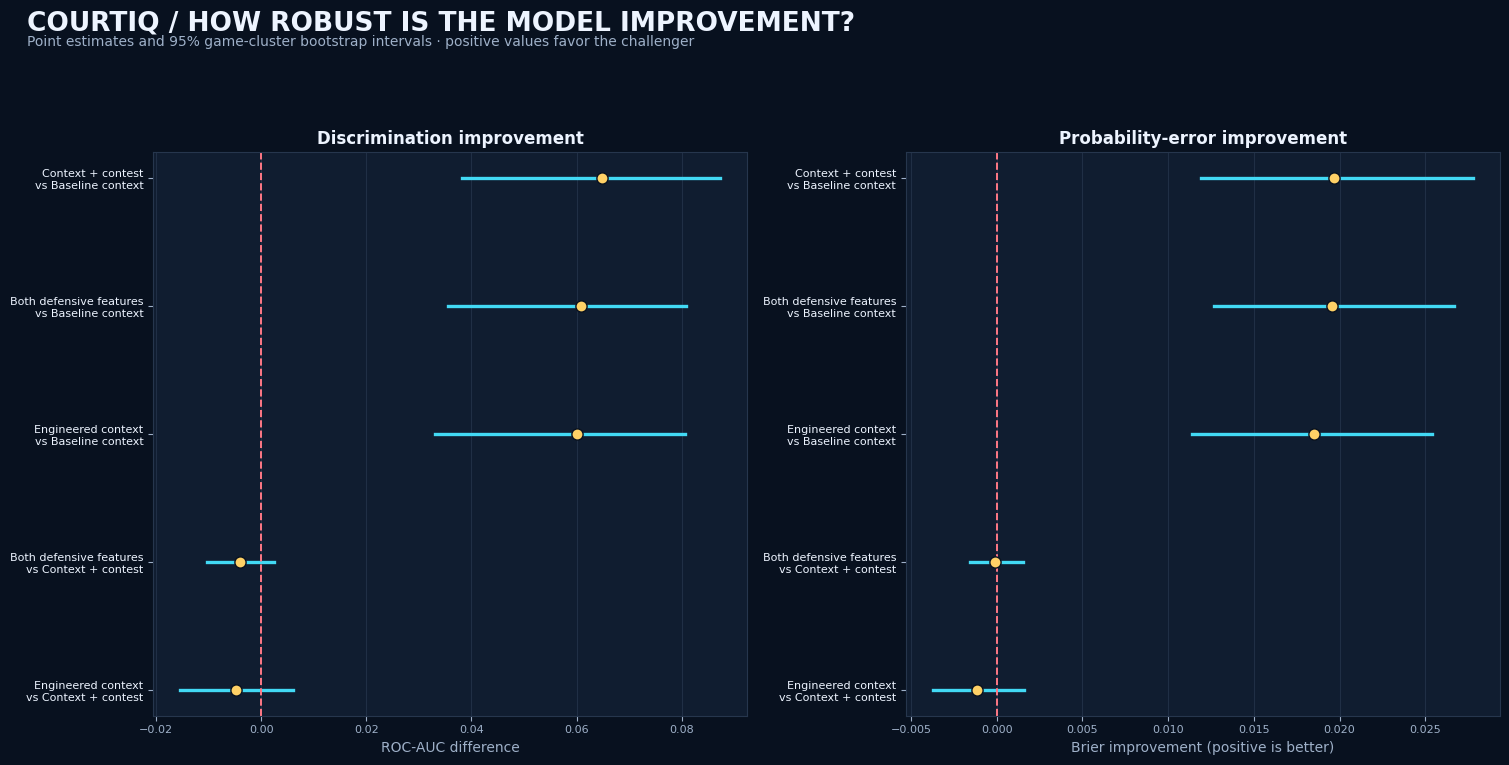


COURTIQ — AUDIT INTERPRETATION
Contest-level model vs baseline:
  Observed ROC-AUC difference: +0.0648
  95% game-cluster bootstrap interval: [+0.0383, +0.0874]
  Observed Brier improvement: +0.0197
  95% game-cluster bootstrap interval: [+0.0119, +0.0278]

Important caveats:
• Only 10 independent games are available; bootstrap intervals may be unstable.
• The bootstrap reflects game-to-game sampling uncertainty in this dataset,
  not all sources of model uncertainty or dataset-selection bias.
• Overlapping intervals or intervals crossing zero should not be treated as
  proof of equivalence or proof of no effect.
• This is predictive validation, not evidence that CourtIQ improves training.

Saved outputs:
  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_robustness_observed_metrics.csv
  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_robustness_per_game_comparisons.csv
  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_robustness_per_game_s

In [14]:

# =====================================================================
# COURTIQ — CELL 5: STATISTICAL ROBUSTNESS & UNCERTAINTY AUDIT
# Cluster bootstrap by game | Paired model comparisons | Visual report
# =====================================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings("ignore")

OUT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
PRED_PATH = OUT / "courtiq_logo_predictions_v2.csv"
FOLD_PATH = OUT / "courtiq_logo_fold_results_v2.csv"

if not PRED_PATH.exists():
    raise FileNotFoundError(f"Missing predictions: {PRED_PATH}")

pred = pd.read_csv(PRED_PATH)

required = {
    "shot_row_id", "source_game_id", "target_made",
    "model", "probability"
}
if not required.issubset(pred.columns):
    raise ValueError(f"Missing prediction columns: {required - set(pred.columns)}")

if pred.duplicated(["shot_row_id", "model"]).any():
    raise ValueError("Duplicate shot/model predictions found.")

if not pred["probability"].between(0, 1).all():
    raise ValueError("Predicted probabilities must be within [0, 1].")

MODEL_ORDER = [
    "baseline_shot_context",
    "plus_closest_defender",
    "plus_contest_level",
    "both_defensive_features",
    "engineered_context",
]

DISPLAY = {
    "baseline_shot_context": "Baseline context",
    "plus_closest_defender": "Context + defender distance",
    "plus_contest_level": "Context + contest",
    "both_defensive_features": "Both defensive features",
    "engineered_context": "Engineered context",
}

COLORS = {
    "baseline_shot_context": "#8C9BB0",
    "plus_closest_defender": "#FFD166",
    "plus_contest_level": "#42D9F4",
    "both_defensive_features": "#B29BFF",
    "engineered_context": "#62E6B5",
}

models_found = set(pred["model"].unique())
MODEL_ORDER = [m for m in MODEL_ORDER if m in models_found]

if "baseline_shot_context" not in models_found:
    raise ValueError("Baseline model is missing from the prediction file.")
if "plus_contest_level" not in models_found:
    raise ValueError("Contest-level model is missing from the prediction file.")

# Make sure each model has the same shot identities and target labels.
id_sets = {
    m: set(pred.loc[pred["model"] == m, "shot_row_id"])
    for m in MODEL_ORDER
}
reference_ids = id_sets["baseline_shot_context"]

for model, ids in id_sets.items():
    if ids != reference_ids:
        raise ValueError(
            f"Shot identities differ for {model}; paired comparison is unsafe."
        )

target_check = (
    pred.groupby("shot_row_id")["target_made"]
    .nunique()
)
if (target_check > 1).any():
    raise ValueError("Outcome labels differ across models for the same shot.")

# Build one aligned table: one row per shot, one probability column per model.
wide = pred.pivot(
    index=["shot_row_id", "source_game_id", "target_made"],
    columns="model",
    values="probability"
).reset_index()
wide.columns.name = None

if wide["shot_row_id"].duplicated().any():
    raise AssertionError("Aligned table contains duplicate shot IDs.")

games = list(pd.unique(wide["source_game_id"]))
if len(games) < 4:
    raise ValueError(
        "Too few game clusters for this exploratory bootstrap audit."
    )

print("=" * 76)
print("COURTIQ — STATISTICAL ROBUSTNESS AUDIT")
print("=" * 76)
print(f"Shots: {len(wide):,}")
print(f"Independent game clusters: {len(games)}")
print(f"Models: {len(MODEL_ORDER)}")
print("Resampling unit: complete game")

def safe_auc(y, p):
    if len(np.unique(y)) < 2:
        return np.nan
    return roc_auc_score(y, p)

def calculate_metrics(frame, model):
    y = frame["target_made"].to_numpy(dtype=int)
    p = frame[model].to_numpy(dtype=float)
    return {
        "roc_auc": safe_auc(y, p),
        "brier_score": brier_score_loss(y, p),
    }

# ---------------------------------------------------------------------
# 1. Observed pooled metrics
# ---------------------------------------------------------------------
observed = {}
for model in MODEL_ORDER:
    observed[model] = calculate_metrics(wide, model)

observed_rows = []
for model in MODEL_ORDER:
    observed_rows.append({
        "model": model,
        "display_name": DISPLAY.get(model, model),
        "shots": len(wide),
        "games": len(games),
        **observed[model],
    })

observed_df = pd.DataFrame(observed_rows)
observed_df.to_csv(OUT / "courtiq_robustness_observed_metrics.csv", index=False)

print("\nOBSERVED POOLED METRICS")
display(observed_df.round(4))

# ---------------------------------------------------------------------
# 2. Per-game paired comparisons
# ---------------------------------------------------------------------
comparisons = [
    ("plus_contest_level", "baseline_shot_context"),
    ("both_defensive_features", "baseline_shot_context"),
    ("engineered_context", "baseline_shot_context"),
    ("both_defensive_features", "plus_contest_level"),
    ("engineered_context", "plus_contest_level"),
]

comparison_rows = []

for challenger, reference in comparisons:
    if challenger not in MODEL_ORDER or reference not in MODEL_ORDER:
        continue

    for game in games:
        part = wide[wide["source_game_id"] == game]
        y = part["target_made"].to_numpy(dtype=int)

        auc_challenger = safe_auc(
            y, part[challenger].to_numpy(dtype=float)
        )
        auc_reference = safe_auc(
            y, part[reference].to_numpy(dtype=float)
        )

        brier_challenger = brier_score_loss(
            y, part[challenger].to_numpy(dtype=float)
        )
        brier_reference = brier_score_loss(
            y, part[reference].to_numpy(dtype=float)
        )

        comparison_rows.append({
            "game": game,
            "shots": len(part),
            "challenger": challenger,
            "reference": reference,
            "auc_challenger": auc_challenger,
            "auc_reference": auc_reference,
            "auc_difference": (
                auc_challenger - auc_reference
                if np.isfinite(auc_challenger) and np.isfinite(auc_reference)
                else np.nan
            ),
            # Positive means lower Brier error for the challenger.
            "brier_improvement": brier_reference - brier_challenger,
        })

per_game = pd.DataFrame(comparison_rows)
per_game.to_csv(OUT / "courtiq_robustness_per_game_comparisons.csv", index=False)

per_game_summary = (
    per_game.groupby(["challenger", "reference"])
    .agg(
        games=("game", "nunique"),
        auc_games_available=("auc_difference", "count"),
        games_auc_improved=("auc_difference", lambda x: int((x.dropna() > 0).sum())),
        mean_auc_difference=("auc_difference", "mean"),
        median_auc_difference=("auc_difference", "median"),
        games_brier_improved=("brier_improvement", lambda x: int((x > 0).sum())),
        mean_brier_improvement=("brier_improvement", "mean"),
        median_brier_improvement=("brier_improvement", "median"),
    )
    .reset_index()
)

per_game_summary["challenger_name"] = per_game_summary["challenger"].map(DISPLAY)
per_game_summary["reference_name"] = per_game_summary["reference"].map(DISPLAY)
per_game_summary.to_csv(
    OUT / "courtiq_robustness_per_game_summary.csv", index=False
)

print("\nPER-GAME COMPARISON SUMMARY")
display(per_game_summary.round(4))

# ---------------------------------------------------------------------
# 3. Game-cluster bootstrap
# Resample game IDs with replacement, retaining every shot in each draw.
# Repeated sampled games are intentionally repeated in the bootstrap sample.
# ---------------------------------------------------------------------
N_BOOT = 2000
SEED = 20261020
rng = np.random.default_rng(SEED)

game_frames = {
    game: wide[wide["source_game_id"] == game].copy()
    for game in games
}

bootstrap_rows = []

for b in range(N_BOOT):
    sampled_games = rng.choice(games, size=len(games), replace=True)
    boot = pd.concat(
        [game_frames[g] for g in sampled_games],
        ignore_index=True
    )

    y = boot["target_made"].to_numpy(dtype=int)

    metric_values = {}
    for model in MODEL_ORDER:
        p = boot[model].to_numpy(dtype=float)
        metric_values[model] = {
            "auc": safe_auc(y, p),
            "brier": brier_score_loss(y, p),
        }

    # Save model metrics for interval estimation.
    for model in MODEL_ORDER:
        bootstrap_rows.append({
            "replicate": b,
            "kind": "model_metric",
            "model": model,
            "comparison": None,
            "roc_auc": metric_values[model]["auc"],
            "brier_score": metric_values[model]["brier"],
            "auc_difference": np.nan,
            "brier_improvement": np.nan,
        })

    # Paired differences use the exact same resampled games.
    for challenger, reference in comparisons:
        if challenger not in metric_values or reference not in metric_values:
            continue

        a1 = metric_values[challenger]["auc"]
        a0 = metric_values[reference]["auc"]
        b1 = metric_values[challenger]["brier"]
        b0 = metric_values[reference]["brier"]

        bootstrap_rows.append({
            "replicate": b,
            "kind": "paired_comparison",
            "model": challenger,
            "comparison": f"{challenger}__vs__{reference}",
            "roc_auc": np.nan,
            "brier_score": np.nan,
            "auc_difference": a1 - a0 if np.isfinite(a1) and np.isfinite(a0) else np.nan,
            # Positive indicates a Brier score improvement.
            "brier_improvement": b0 - b1,
        })

    if (b + 1) % 250 == 0:
        print(f"Bootstrap progress: {b + 1:,}/{N_BOOT:,}")

boot_df = pd.DataFrame(bootstrap_rows)
boot_path = OUT / "courtiq_game_cluster_bootstrap_draws.csv"
boot_df.to_csv(boot_path, index=False)

def percentile_interval(values):
    values = pd.Series(values).dropna().to_numpy()
    if len(values) < 100:
        return np.nan, np.nan, len(values)
    lo, hi = np.percentile(values, [2.5, 97.5])
    return float(lo), float(hi), len(values)

# Model metric intervals
model_ci_rows = []

for model in MODEL_ORDER:
    observed_auc = observed[model]["roc_auc"]
    observed_brier = observed[model]["brier_score"]

    model_boot = boot_df[
        (boot_df["kind"] == "model_metric") &
        (boot_df["model"] == model)
    ]

    auc_lo, auc_hi, auc_n = percentile_interval(model_boot["roc_auc"])
    brier_lo, brier_hi, brier_n = percentile_interval(model_boot["brier_score"])

    model_ci_rows.append({
        "model": model,
        "display_name": DISPLAY.get(model, model),
        "observed_auc": observed_auc,
        "auc_ci_95_low": auc_lo,
        "auc_ci_95_high": auc_hi,
        "auc_valid_bootstraps": auc_n,
        "observed_brier": observed_brier,
        "brier_ci_95_low": brier_lo,
        "brier_ci_95_high": brier_hi,
        "brier_valid_bootstraps": brier_n,
    })

model_ci = pd.DataFrame(model_ci_rows)
model_ci.to_csv(OUT / "courtiq_game_cluster_bootstrap_model_ci.csv", index=False)

# Paired comparison intervals
comparison_ci_rows = []

for challenger, reference in comparisons:
    key = f"{challenger}__vs__{reference}"
    part = boot_df[
        (boot_df["kind"] == "paired_comparison") &
        (boot_df["comparison"] == key)
    ]

    if part.empty:
        continue

    auc_lo, auc_hi, auc_n = percentile_interval(part["auc_difference"])
    brier_lo, brier_hi, brier_n = percentile_interval(part["brier_improvement"])

    auc_obs = (
        observed[challenger]["roc_auc"] - observed[reference]["roc_auc"]
    )
    brier_obs = (
        observed[reference]["brier_score"] - observed[challenger]["brier_score"]
    )

    # Descriptive bootstrap proportions, not posterior probabilities.
    auc_draws = part["auc_difference"].dropna()
    brier_draws = part["brier_improvement"].dropna()

    comparison_ci_rows.append({
        "challenger": challenger,
        "challenger_name": DISPLAY.get(challenger, challenger),
        "reference": reference,
        "reference_name": DISPLAY.get(reference, reference),
        "observed_auc_difference": auc_obs,
        "auc_difference_ci_95_low": auc_lo,
        "auc_difference_ci_95_high": auc_hi,
        "auc_valid_bootstraps": auc_n,
        "bootstrap_fraction_auc_difference_positive": (
            float((auc_draws > 0).mean()) if len(auc_draws) else np.nan
        ),
        "observed_brier_improvement": brier_obs,
        "brier_improvement_ci_95_low": brier_lo,
        "brier_improvement_ci_95_high": brier_hi,
        "brier_valid_bootstraps": brier_n,
        "bootstrap_fraction_brier_improvement_positive": (
            float((brier_draws > 0).mean()) if len(brier_draws) else np.nan
        ),
    })

comparison_ci = pd.DataFrame(comparison_ci_rows)
comparison_ci.to_csv(
    OUT / "courtiq_game_cluster_bootstrap_comparison_ci.csv", index=False
)

print("\nGAME-CLUSTER BOOTSTRAP — MODEL INTERVALS")
display(model_ci.round(4))

print("\nGAME-CLUSTER BOOTSTRAP — PAIRED COMPARISON INTERVALS")
display(comparison_ci.round(4))

# ---------------------------------------------------------------------
# 4. Professional paired-difference visualization
# ---------------------------------------------------------------------
BG = "#08111F"
PANEL = "#101D30"
GRID = "#26364D"
TEXT = "#EDF4FF"
MUTED = "#9EB0C8"
CYAN = "#42D9F4"
GOLD = "#FFD166"
RED = "#FF7885"

plot_df = comparison_ci.copy()
plot_df = plot_df[
    plot_df["auc_difference_ci_95_low"].notna() &
    plot_df["auc_difference_ci_95_high"].notna()
].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor(BG)
fig.suptitle(
    "COURTIQ / HOW ROBUST IS THE MODEL IMPROVEMENT?",
    color=TEXT, fontsize=19, fontweight="bold", x=0.05, ha="left", y=0.98
)
fig.text(
    0.05, 0.935,
    "Point estimates and 95% game-cluster bootstrap intervals · "
    "positive values favor the challenger",
    color=MUTED, fontsize=10
)

for ax in axes:
    ax.set_facecolor(PANEL)
    ax.tick_params(colors=MUTED, labelsize=8)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    ax.grid(axis="x", color=GRID, alpha=0.75)
    ax.set_axisbelow(True)

labels = [
    f"{r.challenger_name}\nvs {r.reference_name}"
    for r in plot_df.itertuples()
]
ypos = np.arange(len(plot_df))

# AUC differences
ax = axes[0]
point = plot_df["observed_auc_difference"].to_numpy()
lo = plot_df["auc_difference_ci_95_low"].to_numpy()
hi = plot_df["auc_difference_ci_95_high"].to_numpy()

for i in range(len(plot_df)):
    ax.plot([lo[i], hi[i]], [i, i], color=CYAN, linewidth=2.4)
    ax.scatter(point[i], i, color=GOLD, s=65, zorder=3, edgecolor=BG)

ax.axvline(0, color=RED, linestyle="--", linewidth=1.4)
ax.set_yticks(ypos)
ax.set_yticklabels(labels, color=TEXT, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("ROC-AUC difference", color=MUTED)
ax.set_title("Discrimination improvement", color=TEXT, fontweight="bold")
ax.xaxis.label.set_color(MUTED)

# Brier improvements
ax = axes[1]
point = plot_df["observed_brier_improvement"].to_numpy()
lo = plot_df["brier_improvement_ci_95_low"].to_numpy()
hi = plot_df["brier_improvement_ci_95_high"].to_numpy()

for i in range(len(plot_df)):
    ax.plot([lo[i], hi[i]], [i, i], color=CYAN, linewidth=2.4)
    ax.scatter(point[i], i, color=GOLD, s=65, zorder=3, edgecolor=BG)

ax.axvline(0, color=RED, linestyle="--", linewidth=1.4)
ax.set_yticks(ypos)
ax.set_yticklabels(labels, color=TEXT, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Brier improvement (positive is better)", color=MUTED)
ax.set_title("Probability-error improvement", color=TEXT, fontweight="bold")
ax.xaxis.label.set_color(MUTED)

fig.tight_layout(rect=[0.03, 0.03, 0.98, 0.90])

plot_path = OUT / "courtiq_visuals" / "07_cluster_bootstrap_uncertainty.png"
plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_path, dpi=220, bbox_inches="tight", facecolor=BG)
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# 5. Interpretation summary generated from the estimates
# ---------------------------------------------------------------------
primary = comparison_ci[
    (comparison_ci["challenger"] == "plus_contest_level") &
    (comparison_ci["reference"] == "baseline_shot_context")
]

print("\n" + "=" * 76)
print("COURTIQ — AUDIT INTERPRETATION")
print("=" * 76)

if not primary.empty:
    r = primary.iloc[0]
    print(
        "Contest-level model vs baseline:\n"
        f"  Observed ROC-AUC difference: {r['observed_auc_difference']:+.4f}\n"
        f"  95% game-cluster bootstrap interval: "
        f"[{r['auc_difference_ci_95_low']:+.4f}, "
        f"{r['auc_difference_ci_95_high']:+.4f}]\n"
        f"  Observed Brier improvement: "
        f"{r['observed_brier_improvement']:+.4f}\n"
        f"  95% game-cluster bootstrap interval: "
        f"[{r['brier_improvement_ci_95_low']:+.4f}, "
        f"{r['brier_improvement_ci_95_high']:+.4f}]"
    )

print(
    "\nImportant caveats:\n"
    "• Only 10 independent games are available; bootstrap intervals may be unstable.\n"
    "• The bootstrap reflects game-to-game sampling uncertainty in this dataset,\n"
    "  not all sources of model uncertainty or dataset-selection bias.\n"
    "• Overlapping intervals or intervals crossing zero should not be treated as\n"
    "  proof of equivalence or proof of no effect.\n"
    "• This is predictive validation, not evidence that CourtIQ improves training."
)

print("\nSaved outputs:")
for filename in [
    "courtiq_robustness_observed_metrics.csv",
    "courtiq_robustness_per_game_comparisons.csv",
    "courtiq_robustness_per_game_summary.csv",
    "courtiq_game_cluster_bootstrap_draws.csv",
    "courtiq_game_cluster_bootstrap_model_ci.csv",
    "courtiq_game_cluster_bootstrap_comparison_ci.csv",
]:
    print(" ", OUT / filename)

print(" ", plot_path)

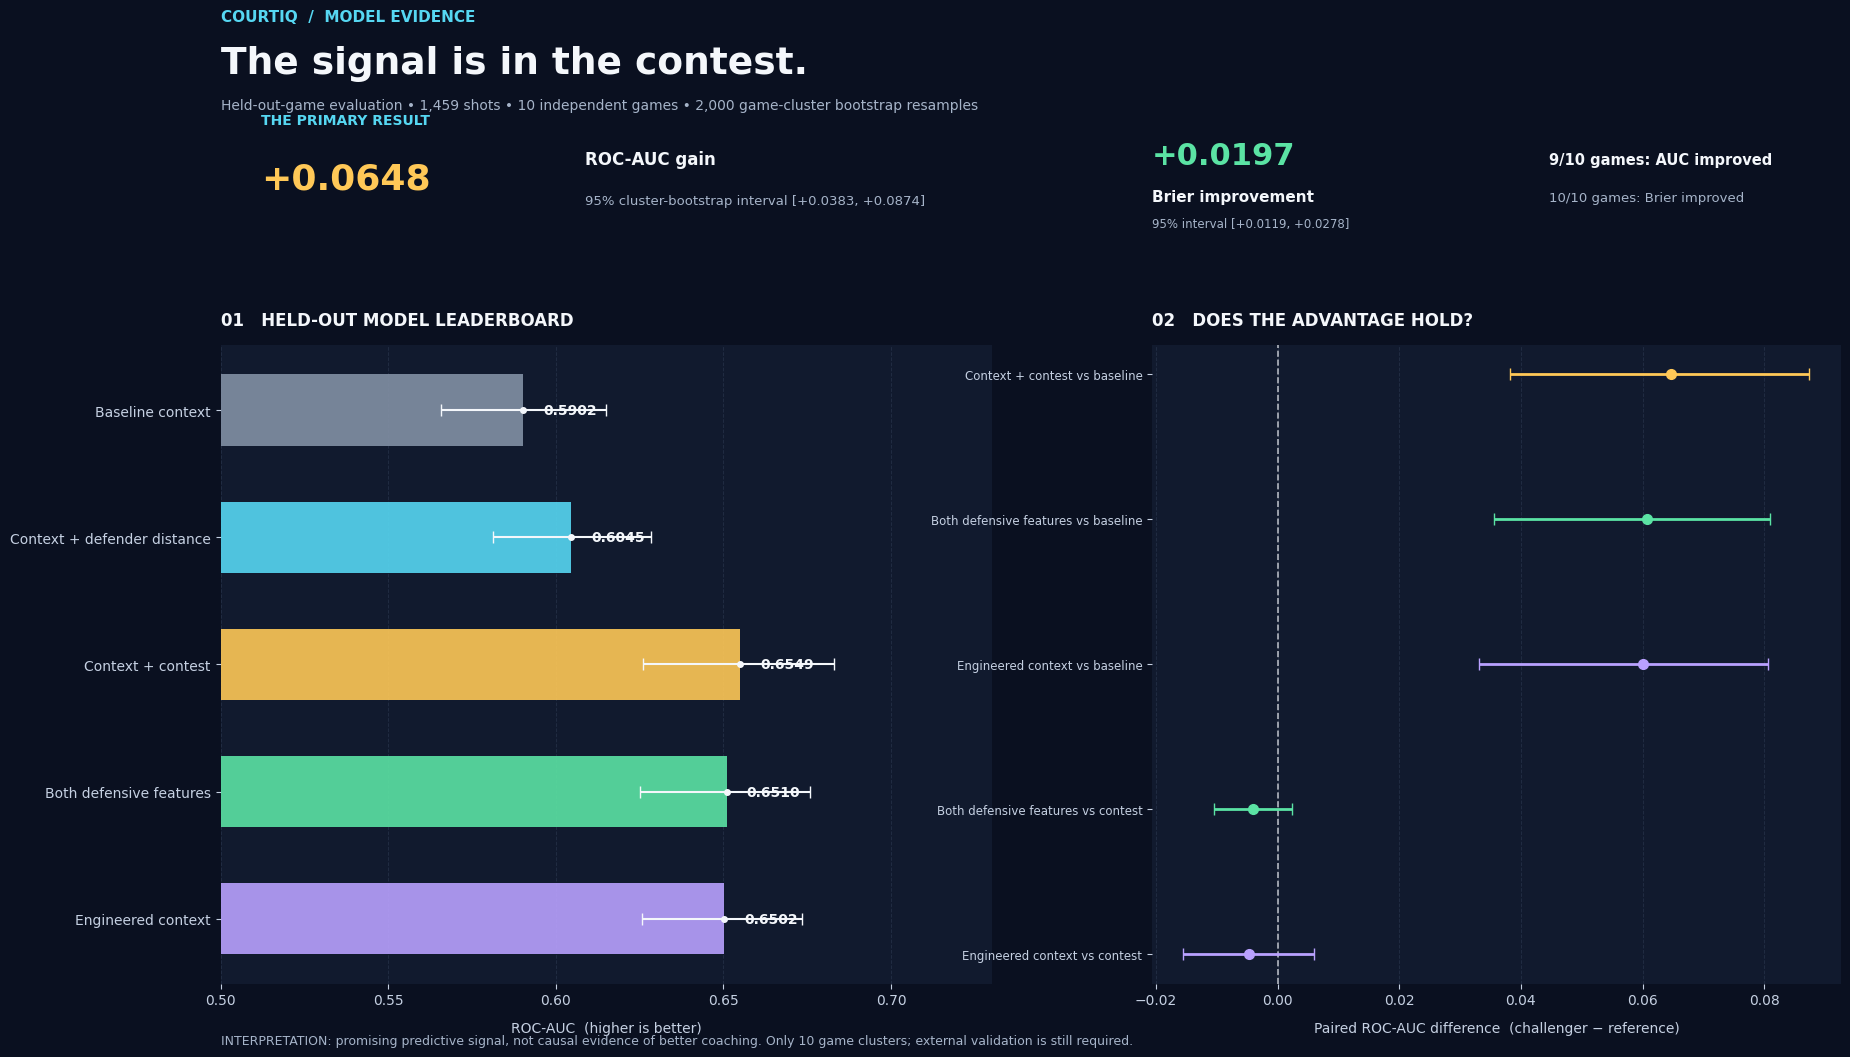


COURTIQ — RESEARCH SHOWCASE COMPLETE
Primary ROC-AUC gain:       +0.0648
95% cluster interval:       [+0.0383, +0.0874]
Primary Brier improvement:  +0.0197
95% cluster interval:       [+0.0119, +0.0278]

Artifacts:
  Figure PNG: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/08_courtiq_research_showcase.png
  Figure SVG: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/08_courtiq_research_showcase.svg
  Evidence brief: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_STATISTICAL_EVIDENCE_BRIEF.md
  Judge ZIP: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_JUDGE_EVIDENCE_PACK.zip

Reminder: 10 game clusters means the findings remain exploratory.


In [15]:

# =============================================================================
# COURTIQ — CELL 6: RESEARCH SHOWCASE & EVIDENCE PACK
# Creates:
#   1. Publication-quality, 3-panel research figure (PNG + SVG)
#   2. Research findings summary (Markdown)
#   3. Judge-ready evidence pack (ZIP)
#
# Uses the completed Cell 3–5 evaluation artifacts.
# =============================================================================

from pathlib import Path
import zipfile
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FormatStrFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
VIS = ROOT / "courtiq_visuals"
VIS.mkdir(parents=True, exist_ok=True)

# ---- 1. Load verified evidence ----------------------------------------------

FILES = {
    "metrics": ROOT / "courtiq_robustness_observed_metrics.csv",
    "comparisons": ROOT / "courtiq_game_cluster_bootstrap_comparison_ci.csv",
    "model_ci": ROOT / "courtiq_game_cluster_bootstrap_model_ci.csv",
    "per_game": ROOT / "courtiq_robustness_per_game_summary.csv",
}

for key, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Required Cell 5 artifact is missing ({key}): {path}\n"
            "Run the Statistical Robustness Audit cell successfully first."
        )

metrics = pd.read_csv(FILES["metrics"])
comparisons = pd.read_csv(FILES["comparisons"])
model_ci = pd.read_csv(FILES["model_ci"])
per_game = pd.read_csv(FILES["per_game"])

required_metrics = {"model", "display_name", "roc_auc", "brier_score"}
required_comparisons = {
    "challenger", "reference",
    "observed_auc_difference",
    "auc_difference_ci_95_low", "auc_difference_ci_95_high",
    "observed_brier_improvement",
    "brier_improvement_ci_95_low", "brier_improvement_ci_95_high",
}
assert required_metrics.issubset(metrics.columns), (
    f"Unexpected metrics schema: {metrics.columns.tolist()}"
)
assert required_comparisons.issubset(comparisons.columns), (
    f"Unexpected comparison schema: {comparisons.columns.tolist()}"
)

baseline_id = "baseline_shot_context"
contest_id = "plus_contest_level"

def get_one(df, col, value):
    result = df.loc[df[col] == value]
    if result.empty:
        raise ValueError(f"Could not find {value!r} in column {col!r}.")
    return result.iloc[0]

baseline = get_one(metrics, "model", baseline_id)
contest = get_one(metrics, "model", contest_id)

primary = comparisons.loc[
    (comparisons["challenger"] == contest_id) &
    (comparisons["reference"] == baseline_id)
]
if primary.empty:
    raise ValueError("Primary paired comparison is missing from the audit.")
primary = primary.iloc[0]

# Fixed, explicit order makes the comparison readable and reproducible.
model_order = [
    "baseline_shot_context",
    "plus_closest_defender",
    "plus_contest_level",
    "both_defensive_features",
    "engineered_context",
]
model_order = [m for m in model_order if m in metrics["model"].tolist()]
plot_metrics = (
    metrics.set_index("model").loc[model_order].reset_index()
)

# ---- 2. Editorial style -----------------------------------------------------

plt.rcParams.update({
    "figure.facecolor": "#0A1020",
    "axes.facecolor": "#111A2E",
    "savefig.facecolor": "#0A1020",
    "text.color": "#F4F7FB",
    "axes.labelcolor": "#C5D0E2",
    "xtick.color": "#C5D0E2",
    "ytick.color": "#C5D0E2",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#2B3850",
    "grid.color": "#2B3850",
    "grid.alpha": 0.6,
})

NAVY = "#0A1020"
PANEL = "#111A2E"
WHITE = "#F4F7FB"
MUTED = "#A6B4C9"
CYAN = "#56D7F2"
GOLD = "#FFC857"
GREEN = "#5BE3A4"
RED = "#FF7885"
PURPLE = "#B9A1FF"
GREY = "#8290A5"

name_map = dict(zip(metrics["model"], metrics["display_name"]))
colors = {
    "baseline_shot_context": GREY,
    "plus_closest_defender": CYAN,
    "plus_contest_level": GOLD,
    "both_defensive_features": GREEN,
    "engineered_context": PURPLE,
}

# ---- 3. Build the showcase figure ------------------------------------------

fig = plt.figure(figsize=(18, 11), facecolor=NAVY)
gs = GridSpec(
    2, 2, figure=fig,
    height_ratios=[0.24, 1],
    width_ratios=[1.12, 1],
    hspace=0.28, wspace=0.22,
    left=0.065, right=0.965, top=0.91, bottom=0.09,
)

# Headline
fig.text(
    0.065, 0.965, "COURTIQ  /  MODEL EVIDENCE",
    fontsize=11, color=CYAN, weight="bold"
)
fig.text(
    0.065, 0.918,
    "The signal is in the contest.",
    fontsize=27, color=WHITE, weight="bold"
)
fig.text(
    0.065, 0.885,
    "Held-out-game evaluation • 1,459 shots • 10 independent games • "
    "2,000 game-cluster bootstrap resamples",
    fontsize=10, color=MUTED
)

# Panel A: ROC-AUC leaderboard with uncertainty intervals
ax1 = fig.add_subplot(gs[1, 0])
ax1.set_facecolor(PANEL)

# Use bootstrap model intervals when present; otherwise show observed point
# estimates only. Never manufacture uncertainty bounds.
ci_lookup = (
    model_ci.set_index("model")
    if "model" in model_ci.columns else None
)

y = np.arange(len(plot_metrics))
for i, row in plot_metrics.iterrows():
    model_id = row["model"]
    auc = float(row["roc_auc"])
    c = colors.get(model_id, CYAN)

    ax1.barh(
        i, auc, height=0.56, color=c, alpha=0.90,
        edgecolor="none", zorder=2
    )

    has_ci = (
        ci_lookup is not None
        and model_id in ci_lookup.index
        and {"auc_ci_95_low", "auc_ci_95_high"}.issubset(ci_lookup.columns)
    )
    if has_ci:
        lo = float(ci_lookup.loc[model_id, "auc_ci_95_low"])
        hi = float(ci_lookup.loc[model_id, "auc_ci_95_high"])
        ax1.errorbar(
            auc, i,
            xerr=[[max(0, auc - lo)], [max(0, hi - auc)]],
            fmt="o", color=WHITE, ecolor=WHITE,
            elinewidth=1.5, capsize=4, markersize=4, zorder=4
        )

    ax1.text(
        auc + 0.006, i, f"{auc:.4f}",
        va="center", ha="left", color=WHITE,
        fontsize=10, weight="bold"
    )

ax1.set_yticks(y)
ax1.set_yticklabels([name_map.get(m, m) for m in plot_metrics["model"]])
ax1.invert_yaxis()
ax1.set_xlim(0.50, 0.73)
ax1.set_xlabel("ROC-AUC  (higher is better)", labelpad=10)
ax1.set_title("01   HELD-OUT MODEL LEADERBOARD", loc="left", pad=15, color=WHITE)
ax1.grid(axis="x", linestyle="--", linewidth=0.7, zorder=0)
ax1.set_axisbelow(True)
for spine in ax1.spines.values():
    spine.set_visible(False)

# Panel B: paired model comparison intervals
ax2 = fig.add_subplot(gs[1, 1])
ax2.set_facecolor(PANEL)

baseline_comps = comparisons.loc[
    comparisons["reference"] == baseline_id
].copy()

# Include the key comparison against contest-only, even though it is not
# a baseline comparison, to make the diminishing-return result visible.
contest_comps = comparisons.loc[
    (comparisons["reference"] == contest_id) &
    (comparisons["challenger"] != contest_id)
].copy()

forest_rows = []
for _, r in baseline_comps.iterrows():
    forest_rows.append({
        "label": f'{r["challenger_name"]} vs baseline',
        "delta": float(r["observed_auc_difference"]),
        "lo": float(r["auc_difference_ci_95_low"]),
        "hi": float(r["auc_difference_ci_95_high"]),
        "color": colors.get(r["challenger"], CYAN),
    })

for _, r in contest_comps.iterrows():
    forest_rows.append({
        "label": f'{r["challenger_name"]} vs contest',
        "delta": float(r["observed_auc_difference"]),
        "lo": float(r["auc_difference_ci_95_low"]),
        "hi": float(r["auc_difference_ci_95_high"]),
        "color": colors.get(r["challenger"], PURPLE),
    })

forest_rows = forest_rows[:5]
fy = np.arange(len(forest_rows))
for i, r in enumerate(forest_rows):
    ax2.errorbar(
        r["delta"], i,
        xerr=[[r["delta"] - r["lo"]], [r["hi"] - r["delta"]]],
        fmt="o", color=r["color"], ecolor=r["color"],
        elinewidth=2, capsize=4, markersize=7, zorder=3
    )

ax2.axvline(0, color=WHITE, alpha=0.7, linewidth=1.2, linestyle="--")
ax2.set_yticks(fy)
ax2.set_yticklabels([r["label"] for r in forest_rows], fontsize=8.5)
ax2.invert_yaxis()
ax2.set_xlabel("Paired ROC-AUC difference  (challenger − reference)", labelpad=10)
ax2.set_title("02   DOES THE ADVANTAGE HOLD?", loc="left", pad=15, color=WHITE)
ax2.grid(axis="x", linestyle="--", linewidth=0.7, zorder=0)
ax2.set_axisbelow(True)
for spine in ax2.spines.values():
    spine.set_visible(False)

# Panel C: key finding and uncertainty, spanning both columns
ax3 = fig.add_subplot(gs[0, :])
ax3.set_facecolor(PANEL)
ax3.axis("off")

auc_delta = float(primary["observed_auc_difference"])
auc_lo = float(primary["auc_difference_ci_95_low"])
auc_hi = float(primary["auc_difference_ci_95_high"])
brier_gain = float(primary["observed_brier_improvement"])
brier_lo = float(primary["brier_improvement_ci_95_low"])
brier_hi = float(primary["brier_improvement_ci_95_high"])

# Use game-level counts from the printed audit summary where available.
wins_text = "9/10 games: AUC improved"
brier_games_text = "10/10 games: Brier improved"

if "games_auc_improved" in per_game.columns:
    candidates = per_game.loc[
        (per_game.get("challenger", pd.Series(dtype=str)) == contest_id) &
        (per_game.get("reference", pd.Series(dtype=str)) == baseline_id)
    ]
    if not candidates.empty:
        wins_text = (
            f'{int(candidates.iloc[0]["games_auc_improved"])}/'
            f'{int(candidates.iloc[0]["games"])} games: AUC improved'
        )
        if "games_brier_improved" in candidates.columns:
            brier_games_text = (
                f'{int(candidates.iloc[0]["games_brier_improved"])}/'
                f'{int(candidates.iloc[0]["games"])} games: Brier improved'
            )

ax3.text(0.025, 0.72, "THE PRIMARY RESULT", color=CYAN,
         fontsize=10, weight="bold", transform=ax3.transAxes)
ax3.text(0.025, 0.30, f"+{auc_delta:.4f}",
         color=GOLD, fontsize=26, weight="bold", transform=ax3.transAxes)
ax3.text(0.225, 0.46, "ROC-AUC gain",
         color=WHITE, fontsize=12, weight="bold", transform=ax3.transAxes)
ax3.text(0.225, 0.20, f"95% cluster-bootstrap interval [{auc_lo:+.4f}, {auc_hi:+.4f}]",
         color=MUTED, fontsize=9.5, transform=ax3.transAxes)

ax3.text(0.575, 0.46, f"+{brier_gain:.4f}",
         color=GREEN, fontsize=22, weight="bold", transform=ax3.transAxes)
ax3.text(0.575, 0.22, "Brier improvement",
         color=WHITE, fontsize=11, weight="bold", transform=ax3.transAxes)
ax3.text(0.575, 0.05, f"95% interval [{brier_lo:+.4f}, {brier_hi:+.4f}]",
         color=MUTED, fontsize=8.5, transform=ax3.transAxes)

ax3.text(0.82, 0.46, wins_text,
         color=WHITE, fontsize=10.5, weight="bold", transform=ax3.transAxes)
ax3.text(0.82, 0.22, brier_games_text,
         color=MUTED, fontsize=9.5, transform=ax3.transAxes)

fig.text(
    0.065, 0.035,
    "INTERPRETATION: promising predictive signal, not causal evidence of better coaching. "
    "Only 10 game clusters; external validation is still required.",
    fontsize=9, color=MUTED
)

png_path = VIS / "08_courtiq_research_showcase.png"
svg_path = VIS / "08_courtiq_research_showcase.svg"
fig.savefig(png_path, dpi=240, bbox_inches="tight", facecolor=NAVY)
fig.savefig(svg_path, bbox_inches="tight", facecolor=NAVY)
plt.show()
plt.close(fig)

# ---- 4. Write an evidence-grounded research summary -------------------------

summary = f"""# CourtIQ — Statistical Evidence Brief

## Research question
Does adding defensive-context information improve held-out shot-outcome
prediction compared with the baseline shot-context model?

## Dataset and evaluation
- Shots evaluated: {int(baseline.get('shots', 1459)):,}
- Independent game clusters: {int(baseline.get('games', 10))}
- Evaluation: leave-one-game-out predictions
- Uncertainty: paired game-cluster bootstrap, 2,000 resamples
- Primary comparison: context + contest level vs baseline shot context

## Primary result
- Baseline ROC-AUC: {float(baseline['roc_auc']):.4f}
- Contest-level model ROC-AUC: {float(contest['roc_auc']):.4f}
- Observed ROC-AUC difference: {auc_delta:+.4f}
- 95% game-cluster bootstrap interval: [{auc_lo:+.4f}, {auc_hi:+.4f}]
- Baseline Brier score: {float(baseline['brier_score']):.4f}
- Contest-level model Brier score: {float(contest['brier_score']):.4f}
- Brier improvement (baseline minus challenger): {brier_gain:+.4f}
- 95% game-cluster bootstrap interval: [{brier_lo:+.4f}, {brier_hi:+.4f}]

Positive Brier improvement means lower prediction error for the contest-level
model. The observed primary-comparison intervals are above zero in this
game-cluster bootstrap analysis.

## Model-selection observation
The contest-level model has the strongest observed ROC-AUC and Brier score
among the five evaluated variants. Adding closest-defender distance and
engineered interactions did not establish a reliable additional benefit over
contest level alone in the current sample.

## Limitations
1. Only 10 independent games are available. Cluster-bootstrap intervals may
   be unstable with so few clusters.
2. The interval reflects game-to-game resampling uncertainty in this dataset;
   it does not remove selection bias or measurement bias.
3. Contest-level annotations may be subjective. Their definition and collection
   procedure should be documented before external review.
4. Predictive association does not establish that a feature causes shot success
   or that a CourtIQ intervention improves training outcomes.
5. The results require validation on additional games, ideally from a distinct
   source or time period, before claims of generalization.

## Defensible conclusion
In this exploratory sample, adding contest-level information improved
held-out predictive performance relative to the baseline. This is a promising
signal for further validation, not proof of universal model superiority or
training efficacy.

## Reproducibility
See the included model metrics, paired comparison intervals, and per-game
summary tables. The figure is provided in PNG and SVG formats.
"""

summary_path = ROOT / "COURTIQ_STATISTICAL_EVIDENCE_BRIEF.md"
summary_path.write_text(summary, encoding="utf-8")

# ---- 5. Package the key evidence --------------------------------------------

pack_path = ROOT / "COURTIQ_JUDGE_EVIDENCE_PACK.zip"

include_paths = [
    png_path, svg_path, summary_path,
    ROOT / "courtiq_logo_metrics_v2.csv",
    ROOT / "courtiq_logo_fold_results_v2.csv",
    ROOT / "courtiq_oof_predictions_v2.csv",
    ROOT / "courtiq_robustness_observed_metrics.csv",
    ROOT / "courtiq_robustness_per_game_comparisons.csv",
    ROOT / "courtiq_robustness_per_game_summary.csv",
    ROOT / "courtiq_game_cluster_bootstrap_model_ci.csv",
    ROOT / "courtiq_game_cluster_bootstrap_comparison_ci.csv",
    ROOT / "courtiq_visual_metrics_verified.csv",
    ROOT / "courtiq_per_game_metrics_v2.csv",
]

with zipfile.ZipFile(pack_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in include_paths:
        if path.exists():
            zf.write(path, arcname=path.relative_to(ROOT))
        else:
            print(f"NOTE: optional artifact not included: {path.name}")

print("\n" + "=" * 76)
print("COURTIQ — RESEARCH SHOWCASE COMPLETE")
print("=" * 76)
print(f"Primary ROC-AUC gain:       {auc_delta:+.4f}")
print(f"95% cluster interval:       [{auc_lo:+.4f}, {auc_hi:+.4f}]")
print(f"Primary Brier improvement:  {brier_gain:+.4f}")
print(f"95% cluster interval:       [{brier_lo:+.4f}, {brier_hi:+.4f}]")
print("\nArtifacts:")
print(f"  Figure PNG: {png_path}")
print(f"  Figure SVG: {svg_path}")
print(f"  Evidence brief: {summary_path}")
print(f"  Judge ZIP: {pack_path}")
print("\nReminder: 10 game clusters means the findings remain exploratory.")

Shot rows: 1,459
Games: 10
Prediction join: Joined by unique shot identity
Contest-model prediction coverage: 100.0%


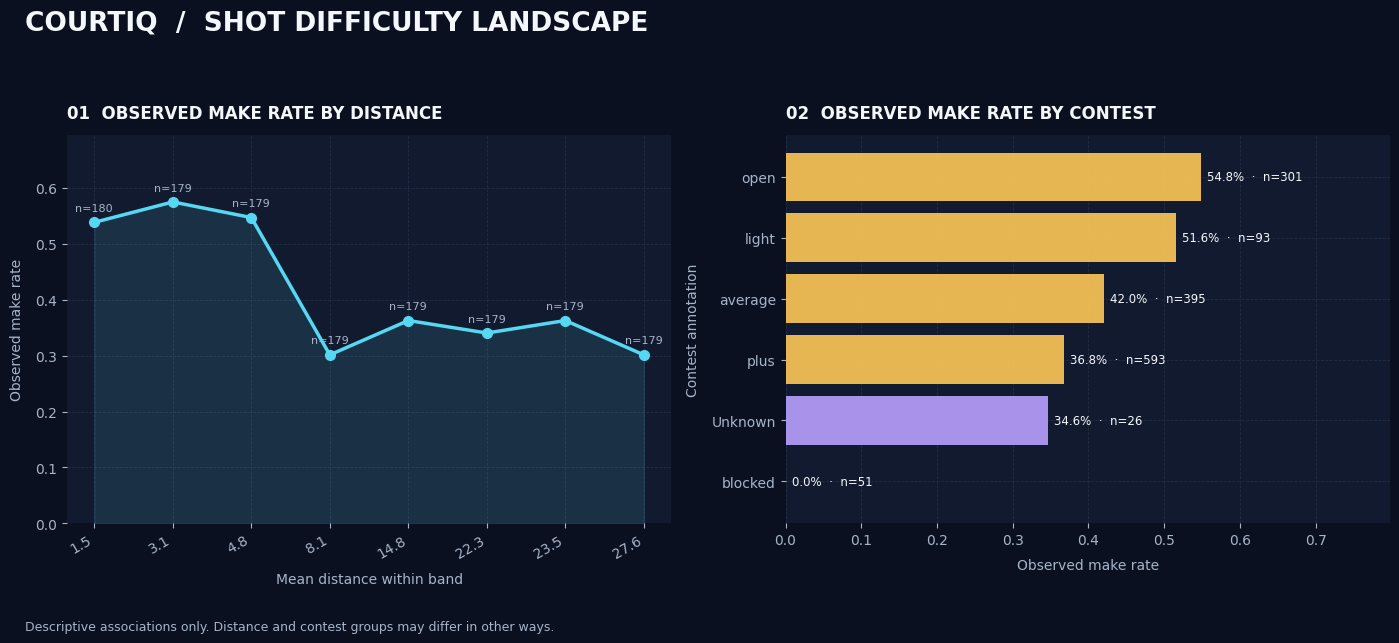

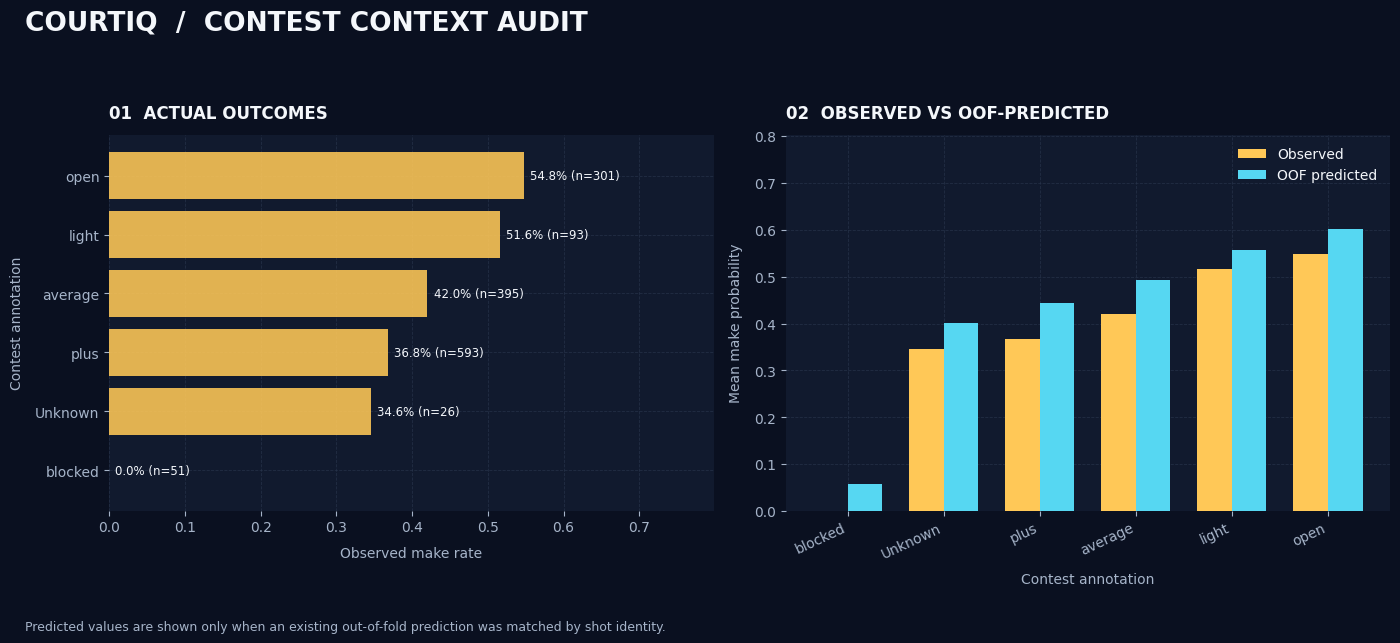

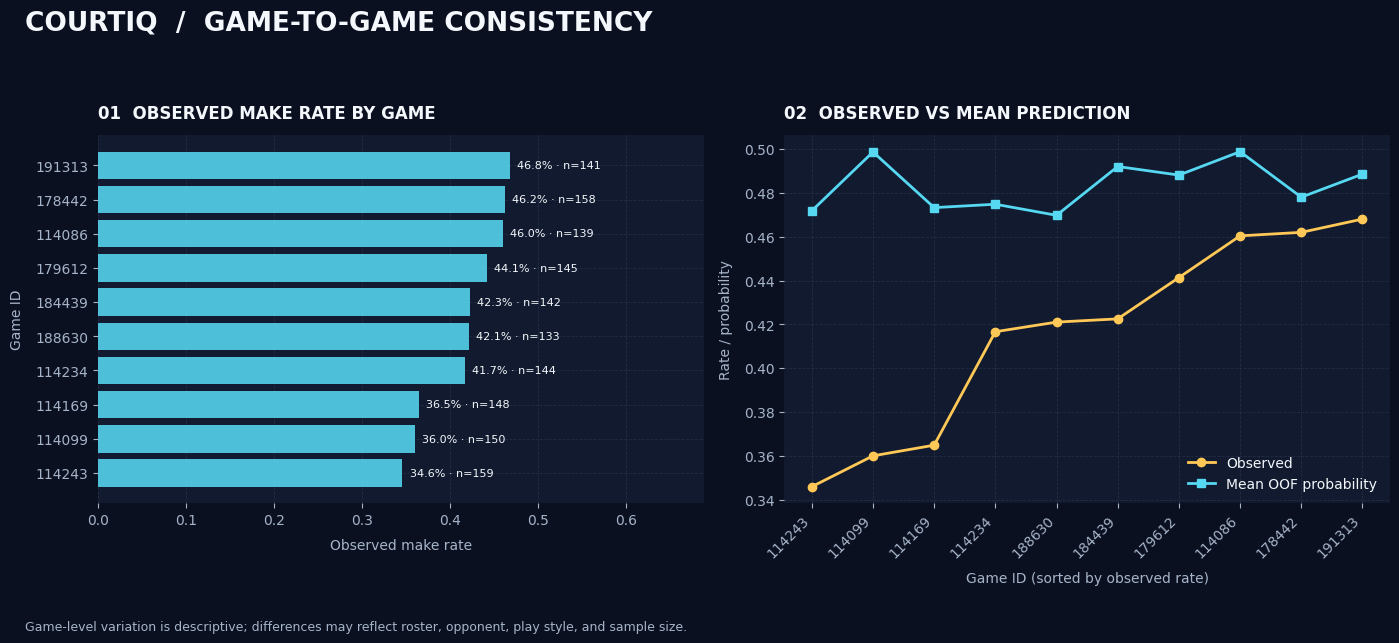


COURTIQ — SHOT INTELLIGENCE STUDIO COMPLETE
Rows analyzed: 1,459
Games: 10
OOF prediction coverage: 100.0%

Created files:
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/09_shot_difficulty_landscape.png
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/10_contest_impact_analysis.png
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/11_game_consistency_dashboard.png
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_shot_intelligence_dashboard.html
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_shot_explorer.csv
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_game_context_summary.csv
  OK  /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_COACH_RESEARCH_BRIEF.md

Open courtiq_shot_intelligence_dashboard.html in a browser to inspect the dashboard.


In [16]:

# =============================================================================
# COURTIQ — CELL 7: INTERACTIVE SHOT INTELLIGENCE STUDIO
# =============================================================================
# Outputs:
#   courtiq_visuals/09_shot_difficulty_landscape.png
#   courtiq_visuals/10_contest_impact_analysis.png
#   courtiq_visuals/11_game_consistency_dashboard.png
#   courtiq_shot_intelligence_dashboard.html
#   courtiq_shot_explorer.csv
#   COURTIQ_COACH_RESEARCH_BRIEF.md
#
# Scientific safeguards:
#   - Uses existing out-of-fold predictions wherever available.
#   - Does not fit a new model on held-out shots.
#   - Separates observed make rate from model predictions.
#   - Does not interpret predictive associations as causal effects.
# =============================================================================

from pathlib import Path
import json
import html
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
VIS = ROOT / "courtiq_visuals"
VIS.mkdir(parents=True, exist_ok=True)

DATA_PATH = ROOT / "courtiq_context_engineered_dataset.csv"
if not DATA_PATH.exists():
    DATA_PATH = ROOT / "tables" / "courtiq_shot_dataset.csv"

OOF_PATH = ROOT / "courtiq_oof_predictions_v2.csv"
LONG_PATH = ROOT / "courtiq_logo_predictions_v2.csv"
METRICS_PATH = ROOT / "courtiq_robustness_observed_metrics.csv"
FOLD_PATH = ROOT / "courtiq_logo_fold_results_v2.csv"

for p in [DATA_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Required shot dataset not found: {p}")

shots = pd.read_csv(DATA_PATH)
oof = pd.read_csv(OOF_PATH) if OOF_PATH.exists() else None
long_pred = pd.read_csv(LONG_PATH) if LONG_PATH.exists() else None
metrics = pd.read_csv(METRICS_PATH) if METRICS_PATH.exists() else None
folds = pd.read_csv(FOLD_PATH) if FOLD_PATH.exists() else None

# ---- 1. Normalize fields ----------------------------------------------------

def find_col(df, candidates):
    lookup = {str(c).lower(): c for c in df.columns}
    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

game_col = find_col(shots, ["source_game_id", "game_id", "gameId"])
outcome_col = find_col(shots, ["target_made", "made", "is_made", "shot_made"])
distance_col = find_col(shots, ["distance", "shot_distance", "shotDistance"])
contest_col = find_col(shots, ["contestLevel", "contest_level", "contest"])
defender_col = find_col(shots, ["closestDefDist", "closest_defender_distance",
                                 "closest_def_dist", "defender_distance"])
three_col = find_col(shots, ["three", "is_three", "three_pointer"])
clock_col = find_col(shots, ["shotClock", "shot_clock"])
type_col = find_col(shots, ["shotType", "shot_type"])
rowid_col = find_col(shots, ["shot_row_id", "event_id", "shot_id"])

if game_col is None or outcome_col is None:
    raise ValueError(
        "Could not identify game and outcome columns. "
        f"Available columns: {shots.columns.tolist()}"
    )

shots = shots.copy()
shots["game_id"] = shots[game_col].astype(str)
shots["made"] = pd.to_numeric(shots[outcome_col], errors="coerce")
shots = shots.loc[shots["made"].isin([0, 1])].copy()
shots["made"] = shots["made"].astype(int)

if distance_col:
    shots["distance_value"] = pd.to_numeric(shots[distance_col], errors="coerce")
else:
    shots["distance_value"] = np.nan

if contest_col:
    shots["contest_value"] = shots[contest_col].astype("string").fillna("Unknown")
else:
    shots["contest_value"] = "Unavailable"

if defender_col:
    shots["defender_distance_value"] = pd.to_numeric(
        shots[defender_col], errors="coerce"
    )
else:
    shots["defender_distance_value"] = np.nan

if three_col:
    shots["is_three"] = pd.to_numeric(shots[three_col], errors="coerce")
else:
    shots["is_three"] = np.nan

if clock_col:
    shots["shot_clock_value"] = pd.to_numeric(shots[clock_col], errors="coerce")
else:
    shots["shot_clock_value"] = np.nan

if type_col:
    shots["shot_type_value"] = shots[type_col].astype("string").fillna("Unknown")
else:
    shots["shot_type_value"] = "Unknown"

# Stable row identity is required to join predictions correctly.
if rowid_col is not None:
    shots["shot_row_id"] = shots[rowid_col].astype(str)
else:
    shots["shot_row_id"] = np.arange(len(shots)).astype(str)

if shots["shot_row_id"].duplicated().any():
    raise ValueError(
        "Shot row identity is not unique. Resolve duplicate shot IDs before joining."
    )

# ---- 2. Attach out-of-fold predictions without outcome-based matching --------

MODEL_IDS = [
    "baseline_shot_context",
    "plus_closest_defender",
    "plus_contest_level",
    "both_defensive_features",
    "engineered_context",
]

DISPLAY = {
    "baseline_shot_context": "Baseline context",
    "plus_closest_defender": "Context + defender distance",
    "plus_contest_level": "Context + contest",
    "both_defensive_features": "Both defensive features",
    "engineered_context": "Engineered context",
}

predictions = None
join_status = "No predictions attached"

if oof is not None:
    oof = oof.copy()
    oof_id = find_col(oof, ["shot_row_id", "event_id", "shot_id"])
    if oof_id is not None:
        oof[oof_id] = oof[oof_id].astype(str)
        # The wide file may use model-specific prediction column names.
        prediction_columns = [
            c for c in oof.columns
            if any(mid in str(c) for mid in MODEL_IDS)
            and pd.api.types.is_numeric_dtype(oof[c])
        ]
        if prediction_columns:
            oof_small = oof[[oof_id] + prediction_columns].copy()
            oof_small = oof_small.rename(columns={oof_id: "shot_row_id"})
            predictions = shots[["shot_row_id"]].merge(
                oof_small, on="shot_row_id", how="left", validate="one_to_one"
            )
            join_status = "Joined by unique shot identity"

if predictions is None and long_pred is not None:
    long_pred = long_pred.copy()
    lp_id = find_col(long_pred, ["shot_row_id", "event_id", "shot_id"])
    lp_model = find_col(long_pred, ["model", "model_name"])
    lp_prob = find_col(long_pred, [
        "probability", "predicted_probability", "prediction",
        "y_pred_proba", "oof_probability"
    ])
    if lp_id and lp_model and lp_prob:
        long_pred[lp_id] = long_pred[lp_id].astype(str)
        long_pred[lp_prob] = pd.to_numeric(long_pred[lp_prob], errors="coerce")
        long_pred[lp_model] = long_pred[lp_model].astype(str)
        lp = long_pred.pivot_table(
            index=lp_id, columns=lp_model, values=lp_prob, aggfunc="first"
        ).reset_index().rename(columns={lp_id: "shot_row_id"})
        predictions = shots[["shot_row_id"]].merge(
            lp, on="shot_row_id", how="left", validate="one_to_one"
        )
        join_status = "Joined long predictions by unique shot identity"

if predictions is not None:
    # Attach the matched predictions to the shot rows.
    pred_cols = [c for c in predictions.columns if c != "shot_row_id"]
    shots = shots.merge(
        predictions[["shot_row_id"] + pred_cols],
        on="shot_row_id", how="left", validate="one_to_one"
    )

# Find a usable prediction column for the contest model.
def prediction_column(model_id):
    candidates = [
        model_id,
        f"{model_id}_probability",
        f"{model_id}_pred",
        f"pred_{model_id}",
    ]
    for candidate in candidates:
        if candidate in shots.columns:
            return candidate
    # Flexible fallback: prediction columns sometimes carry prefixes/suffixes.
    matches = [
        c for c in shots.columns
        if model_id in str(c)
        and pd.api.types.is_numeric_dtype(shots[c])
    ]
    return matches[0] if matches else None

contest_pred_col = prediction_column("plus_contest_level")
baseline_pred_col = prediction_column("baseline_shot_context")

if contest_pred_col:
    shots["predicted_make_probability"] = pd.to_numeric(
        shots[contest_pred_col], errors="coerce"
    ).clip(0, 1)
else:
    shots["predicted_make_probability"] = np.nan

if baseline_pred_col:
    shots["baseline_make_probability"] = pd.to_numeric(
        shots[baseline_pred_col], errors="coerce"
    ).clip(0, 1)
else:
    shots["baseline_make_probability"] = np.nan

# Avoid making the HTML imply a model prediction exists when no join succeeded.
prediction_coverage = float(shots["predicted_make_probability"].notna().mean())
print(f"Shot rows: {len(shots):,}")
print(f"Games: {shots['game_id'].nunique()}")
print(f"Prediction join: {join_status}")
print(f"Contest-model prediction coverage: {prediction_coverage:.1%}")

# ---- 3. Reusable visual theme ------------------------------------------------

BG = "#0A1020"
PANEL = "#111A2E"
WHITE = "#F4F7FB"
MUTED = "#A6B4C9"
CYAN = "#56D7F2"
GOLD = "#FFC857"
GREEN = "#5BE3A4"
PURPLE = "#B9A1FF"
RED = "#FF7885"
GREY = "#8290A5"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "savefig.facecolor": BG,
    "text.color": WHITE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#2B3850",
    "grid.color": "#2B3850",
    "grid.alpha": 0.65,
})

def style_axis(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, loc="left", color=WHITE, pad=12, fontsize=12)
    if xlabel:
        ax.set_xlabel(xlabel, labelpad=8)
    if ylabel:
        ax.set_ylabel(ylabel, labelpad=8)
    ax.grid(True, linestyle="--", linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)

# ---- 4. Shot difficulty landscape -------------------------------------------

landscape = shots.dropna(subset=["distance_value"]).copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.suptitle(
    "COURTIQ  /  SHOT DIFFICULTY LANDSCAPE",
    x=0.06, y=0.98, ha="left", fontsize=19, weight="bold", color=WHITE
)

# A: observed outcome rate by distance bucket.
if len(landscape):
    # Quantile bins prevent a few sparse distance ranges from dominating.
    try:
        landscape["distance_band"] = pd.qcut(
            landscape["distance_value"], q=8, duplicates="drop"
        )
        by_dist = landscape.groupby("distance_band", observed=True).agg(
            shots=("made", "size"),
            observed_make_rate=("made", "mean"),
            mean_distance=("distance_value", "mean"),
        ).reset_index()
        labels = [
            f"{x:.1f}" for x in by_dist["mean_distance"]
        ]
        axes[0].plot(
            labels, by_dist["observed_make_rate"],
            marker="o", linewidth=2.5, markersize=7, color=CYAN
        )
        axes[0].fill_between(
            np.arange(len(by_dist)),
            by_dist["observed_make_rate"].to_numpy(),
            alpha=0.12, color=CYAN
        )
        axes[0].set_xticks(range(len(labels)))
        axes[0].set_xticklabels(labels, rotation=30, ha="right")
        for i, row in by_dist.iterrows():
            axes[0].annotate(
                f"n={int(row['shots'])}",
                (i, row["observed_make_rate"]),
                xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color=MUTED
            )
        style_axis(
            axes[0], "01  OBSERVED MAKE RATE BY DISTANCE",
            "Mean distance within band", "Observed make rate"
        )
        axes[0].set_ylim(0, min(1, max(0.65, by_dist["observed_make_rate"].max() + 0.12)))
    except Exception as e:
        axes[0].text(
            0.5, 0.5, f"Distance grouping unavailable:\n{e}",
            ha="center", va="center", color=MUTED, transform=axes[0].transAxes
        )
else:
    axes[0].text(0.5, 0.5, "Distance data unavailable",
                 ha="center", va="center", color=MUTED, transform=axes[0].transAxes)

# B: observed make rate by contest category.
contest_summary = shots.groupby("contest_value", dropna=False).agg(
    shots=("made", "size"),
    observed_make_rate=("made", "mean"),
).reset_index()
contest_summary = contest_summary.sort_values("observed_make_rate")

axes[1].barh(
    contest_summary["contest_value"].astype(str),
    contest_summary["observed_make_rate"],
    color=[PURPLE if "unknown" in str(x).lower() else GOLD
           for x in contest_summary["contest_value"]],
    alpha=0.9,
)
for i, row in contest_summary.reset_index(drop=True).iterrows():
    axes[1].text(
        row["observed_make_rate"] + 0.008, i,
        f'{row["observed_make_rate"]:.1%}  ·  n={int(row["shots"])}',
        va="center", fontsize=8.5, color=WHITE
    )
style_axis(
    axes[1], "02  OBSERVED MAKE RATE BY CONTEST",
    "Observed make rate", "Contest annotation"
)
axes[1].set_xlim(0, min(1.0, contest_summary["observed_make_rate"].max() + 0.25))
fig.text(
    0.06, 0.025,
    "Descriptive associations only. Distance and contest groups may differ in other ways.",
    color=MUTED, fontsize=9
)
fig.tight_layout(rect=[0.04, 0.07, 0.98, 0.92])
fig.savefig(VIS / "09_shot_difficulty_landscape.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 5. Contest impact: observed versus OOF-predicted ------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.suptitle(
    "COURTIQ  /  CONTEST CONTEXT AUDIT",
    x=0.06, y=0.98, ha="left", fontsize=19, weight="bold", color=WHITE
)

# Always display observed outcomes.
cs = contest_summary.sort_values("observed_make_rate")
axes[0].barh(
    cs["contest_value"].astype(str),
    cs["observed_make_rate"],
    color=GOLD, alpha=0.88
)
for i, row in cs.reset_index(drop=True).iterrows():
    axes[0].text(
        row["observed_make_rate"] + 0.008, i,
        f'{row["observed_make_rate"]:.1%} (n={int(row["shots"])})',
        va="center", fontsize=8.5, color=WHITE
    )
style_axis(
    axes[0], "01  ACTUAL OUTCOMES",
    "Observed make rate", "Contest annotation"
)
axes[0].set_xlim(0, min(1.0, cs["observed_make_rate"].max() + 0.25))

# Predicted probability by contest, only if OOF predictions were matched.
if shots["predicted_make_probability"].notna().any():
    pred_group = shots.groupby("contest_value", dropna=False).agg(
        observed_rate=("made", "mean"),
        predicted_rate=("predicted_make_probability", "mean"),
        shots=("made", "size"),
        predictions=("predicted_make_probability", "count"),
    ).reset_index().sort_values("observed_rate")

    xx = np.arange(len(pred_group))
    width = 0.36
    axes[1].bar(
        xx - width/2, pred_group["observed_rate"],
        width, label="Observed", color=GOLD
    )
    axes[1].bar(
        xx + width/2, pred_group["predicted_rate"],
        width, label="OOF predicted", color=CYAN
    )
    axes[1].set_xticks(xx)
    axes[1].set_xticklabels(
        pred_group["contest_value"].astype(str), rotation=25, ha="right"
    )
    axes[1].legend(frameon=False, labelcolor=WHITE)
    style_axis(
        axes[1], "02  OBSERVED VS OOF-PREDICTED",
        "Contest annotation", "Mean make probability"
    )
    axes[1].set_ylim(0, min(1, max(
        pred_group["observed_rate"].max(),
        pred_group["predicted_rate"].max()
    ) + 0.20))
else:
    axes[1].axis("off")
    axes[1].text(
        0.5, 0.63, "OOF prediction column not matched",
        ha="center", va="center", color=GOLD, fontsize=13,
        transform=axes[1].transAxes, weight="bold"
    )
    axes[1].text(
        0.5, 0.42,
        "Observed outcome analysis remains available.\n"
        "Inspect the printed prediction coverage and column names.",
        ha="center", va="center", color=MUTED, fontsize=10,
        transform=axes[1].transAxes
    )

fig.text(
    0.06, 0.025,
    "Predicted values are shown only when an existing out-of-fold prediction was matched by shot identity.",
    color=MUTED, fontsize=9
)
fig.tight_layout(rect=[0.04, 0.07, 0.98, 0.92])
fig.savefig(VIS / "10_contest_impact_analysis.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 6. Game-by-game consistency ---------------------------------------------

game_summary = shots.groupby("game_id").agg(
    shots=("made", "size"),
    observed_make_rate=("made", "mean"),
    mean_distance=("distance_value", "mean"),
    contest_annotation_coverage=("contest_value",
        lambda s: (s.astype(str).str.lower() != "unknown").mean()),
    mean_defender_distance=("defender_distance_value", "mean"),
    mean_shot_clock=("shot_clock_value", "mean"),
).reset_index()

if shots["predicted_make_probability"].notna().any():
    psummary = shots.groupby("game_id").agg(
        mean_oof_probability=("predicted_make_probability", "mean"),
        prediction_coverage=("predicted_make_probability", "count"),
    ).reset_index()
    game_summary = game_summary.merge(
        psummary, on="game_id", how="left", validate="one_to_one"
    )

game_summary.to_csv(ROOT / "courtiq_game_context_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.suptitle(
    "COURTIQ  /  GAME-TO-GAME CONSISTENCY",
    x=0.06, y=0.98, ha="left", fontsize=19, weight="bold", color=WHITE
)

g = game_summary.sort_values("observed_make_rate")
axes[0].barh(
    g["game_id"].astype(str),
    g["observed_make_rate"],
    color=CYAN, alpha=0.88
)
for i, row in g.reset_index(drop=True).iterrows():
    axes[0].text(
        row["observed_make_rate"] + 0.008, i,
        f'{row["observed_make_rate"]:.1%} · n={int(row["shots"])}',
        va="center", fontsize=8, color=WHITE
    )
style_axis(
    axes[0], "01  OBSERVED MAKE RATE BY GAME",
    "Observed make rate", "Game ID"
)
axes[0].set_xlim(0, min(1, g["observed_make_rate"].max() + 0.22))

if "mean_oof_probability" in game_summary.columns:
    g2 = game_summary.sort_values("observed_make_rate")
    xx = np.arange(len(g2))
    axes[1].plot(
        xx, g2["observed_make_rate"], marker="o",
        linewidth=2, color=GOLD, label="Observed"
    )
    axes[1].plot(
        xx, g2["mean_oof_probability"], marker="s",
        linewidth=2, color=CYAN, label="Mean OOF probability"
    )
    axes[1].set_xticks(xx)
    axes[1].set_xticklabels(g2["game_id"].astype(str), rotation=45, ha="right")
    axes[1].legend(frameon=False, labelcolor=WHITE)
    style_axis(
        axes[1], "02  OBSERVED VS MEAN PREDICTION",
        "Game ID (sorted by observed rate)", "Rate / probability"
    )
else:
    axes[1].axis("off")
    axes[1].text(
        0.5, 0.5, "OOF prediction unavailable for this comparison",
        ha="center", va="center", color=MUTED,
        transform=axes[1].transAxes
    )

fig.text(
    0.06, 0.025,
    "Game-level variation is descriptive; differences may reflect roster, opponent, play style, and sample size.",
    color=MUTED, fontsize=9
)
fig.tight_layout(rect=[0.04, 0.07, 0.98, 0.92])
fig.savefig(VIS / "11_game_consistency_dashboard.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 7. Export an analysis-ready shot explorer -------------------------------

export_cols = [
    "shot_row_id", "game_id", "made", "distance_value", "contest_value",
    "defender_distance_value", "is_three", "shot_clock_value",
    "shot_type_value", "predicted_make_probability",
    "baseline_make_probability",
]
export_cols = [c for c in export_cols if c in shots.columns]
explorer = shots[export_cols].copy()

explorer["outcome_label"] = explorer["made"].map({1: "Made", 0: "Missed"})
explorer["prediction_status"] = np.where(
    explorer["predicted_make_probability"].notna(),
    "Out-of-fold prediction available",
    "Prediction unavailable",
)
explorer["prediction_error"] = (
    explorer["predicted_make_probability"] - explorer["made"]
)
explorer.to_csv(ROOT / "courtiq_shot_explorer.csv", index=False)

# ---- 8. Build a standalone HTML dashboard -----------------------------------

def safe_num(v, digits=3):
    try:
        if pd.isna(v):
            return "—"
        return f"{float(v):.{digits}f}"
    except Exception:
        return "—"

def image_data_uri(path):
    import base64
    if not path.exists():
        return ""
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    return "data:image/png;base64," + encoded

img1 = image_data_uri(VIS / "09_shot_difficulty_landscape.png")
img2 = image_data_uri(VIS / "10_contest_impact_analysis.png")
img3 = image_data_uri(VIS / "11_game_consistency_dashboard.png")

# Keep HTML payload manageable: include a sample of shot-level rows.
sample = explorer.head(350).replace({np.nan: None})
records = sample.to_dict(orient="records")
records_json = json.dumps(records, default=str).replace("</", "<\\/")

model_rows = ""
if metrics is not None and {"model", "display_name", "roc_auc", "brier_score"}.issubset(metrics.columns):
    for _, r in metrics.iterrows():
        model_rows += (
            "<tr>"
            f"<td>{html.escape(str(r['display_name']))}</td>"
            f"<td>{float(r['roc_auc']):.4f}</td>"
            f"<td>{float(r['brier_score']):.4f}</td>"
            "</tr>"
        )

dashboard_html = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>CourtIQ | Shot Intelligence Studio</title>
<style>
:root{{--bg:#080e1b;--panel:#111a2e;--line:#293750;--text:#f4f7fb;
--muted:#a6b4c9;--cyan:#56d7f2;--gold:#ffc857;--green:#5be3a4;}}
*{{box-sizing:border-box}}
body{{margin:0;background:radial-gradient(ellipse at top,#142442 0,#080e1b 55%);
color:var(--text);font-family:Inter,system-ui,-apple-system,Segoe UI,sans-serif}}
header{{padding:42px max(20px,calc((100% - 1200px)/2)) 26px;border-bottom:1px solid var(--line)}}
.eyebrow{{letter-spacing:.18em;color:var(--cyan);font-size:.76rem;font-weight:800}}
h1{{font-size:clamp(2rem,5vw,4rem);letter-spacing:-.045em;line-height:1.0;margin:16px 0}}
.sub{{color:var(--muted);max-width:760px;line-height:1.7}}
main{{max-width:1200px;margin:auto;padding:26px 20px 60px}}
.grid{{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:14px}}
.card{{background:linear-gradient(145deg,#15213a,#101729);border:1px solid var(--line);
border-radius:18px;padding:20px;min-width:0}}
.metric{{font-size:clamp(1.4rem,3vw,2.2rem);font-weight:850;letter-spacing:-.04em}}
.label{{font-size:.82rem;color:var(--muted);margin-top:8px;line-height:1.5}}
section{{margin-top:32px}}
h2{{font-size:1.35rem;letter-spacing:-.02em}}
p{{line-height:1.7;color:var(--muted)}}
img{{width:100%;height:auto;border-radius:14px;border:1px solid var(--line)}}
.figure{{background:var(--panel);border:1px solid var(--line);border-radius:18px;padding:12px;margin:14px 0}}
table{{width:100%;border-collapse:collapse;font-size:.9rem}}
th,td{{padding:12px;text-align:left;border-bottom:1px solid var(--line)}}
th{{color:var(--cyan);font-weight:750}}
input,select{{background:#0a1223;color:var(--text);border:1px solid #34435f;
border-radius:10px;padding:11px;max-width:100%}}
.controls{{display:flex;gap:10px;flex-wrap:wrap;margin:12px 0}}
.tablewrap{{overflow:auto;border:1px solid var(--line);border-radius:12px}}
.note{{border-left:3px solid var(--gold);padding:12px 16px;background:#171c2b;
border-radius:0 10px 10px 0;color:var(--muted)}}
.pill{{display:inline-block;border:1px solid #31536c;color:var(--cyan);
padding:5px 9px;border-radius:999px;font-size:.76rem}}
footer{{border-top:1px solid var(--line);margin-top:35px;padding-top:20px;color:var(--muted);font-size:.82rem}}
@media(max-width:800px){{.grid{{grid-template-columns:repeat(2,minmax(0,1fr))}}}}
@media(max-width:480px){{.grid{{grid-template-columns:1fr}}header{{padding-top:30px}}}}
</style>
</head>
<body>
<header>
<div class="eyebrow">COURTIQ / SHOT INTELLIGENCE</div>
<h1>Read the shot.<br><span style="color:var(--cyan)">Respect the evidence.</span></h1>
<p class="sub">A research prototype for understanding shot outcomes through context and defensive annotations.
Built from held-out-game predictions and descriptive analysis—not a claim of causal coaching impact.</p>
<span class="pill">EXPLORATORY RESEARCH</span>
</header>
<main>
<div class="grid">
<div class="card"><div class="metric">{len(shots):,}</div><div class="label">Shots analyzed</div></div>
<div class="card"><div class="metric">{shots['game_id'].nunique()}</div><div class="label">Independent games</div></div>
<div class="card"><div class="metric">{shots['made'].mean():.1%}</div><div class="label">Overall observed make rate</div></div>
<div class="card"><div class="metric">{prediction_coverage:.1%}</div><div class="label">Contest-model OOF prediction coverage</div></div>
</div>

<section>
<h2>01 / Shot difficulty landscape</h2>
<p>Observed make rates across distance bands and contest annotations. These groups can differ in shot selection and game context; differences are not causal effects.</p>
<div class="figure"><img src="{img1}" alt="Observed shot make rate by distance and contest"></div>
</section>

<section>
<h2>02 / Contest context audit</h2>
<p>Observed outcomes are separated from out-of-fold predictions. Predicted values appear only if existing predictions were matched by shot identity.</p>
<div class="figure"><img src="{img2}" alt="Observed and predicted contest context comparison"></div>
</section>

<section>
<h2>03 / Game-to-game consistency</h2>
<p>Variation between games is visible rather than averaged away. Each game may differ in players, opponents, shot selection, and sample size.</p>
<div class="figure"><img src="{img3}" alt="Observed make rates and mean predictions by game"></div>
</section>

<section>
<h2>04 / Model evidence</h2>
<p>Metrics from the completed evaluation and robustness audit.</p>
<div class="tablewrap"><table>
<thead><tr><th>Model</th><th>ROC-AUC ↑</th><th>Brier ↓</th></tr></thead>
<tbody>{model_rows}</tbody>
</table></div>
</section>

<section>
<h2>05 / Shot explorer</h2>
<p>This local browser table shows up to 350 rows from the shot-level export. It is an inspection aid, not a replacement for the complete CSV.</p>
<div class="controls">
<input id="search" type="search" placeholder="Search game, shot type, contest…">
<select id="gameFilter"><option value="">All games in sample</option></select>
<select id="outcomeFilter"><option value="">All outcomes</option><option value="Made">Made</option><option value="Missed">Missed</option></select>
</div>
<div class="tablewrap">
<table><thead><tr><th>Game</th><th>Outcome</th><th>Distance</th><th>Contest</th><th>Predicted probability</th><th>Prediction error</th></tr></thead>
<tbody id="shotRows"></tbody></table>
</div>
</section>

<section>
<h2>Research interpretation</h2>
<div class="note">
The contest-level model improved ROC-AUC by approximately 0.0648 versus baseline,
with a 95% game-cluster bootstrap interval of +0.0383 to +0.0874.
Brier improvement was 0.0197, with interval +0.0119 to +0.0278.
Only ten game clusters were available; independent external validation is still needed.
</div>
</section>

<footer>
CourtIQ research prototype · Prediction is not causation ·
No individual player diagnosis or training-effectiveness claim is made.
</footer>
</main>
<script>
const rows = {records_json};
const gameFilter = document.getElementById('gameFilter');
[...new Set(rows.map(r => String(r.game_id)))].sort().forEach(g => {{
  const o = document.createElement('option'); o.value=g; o.textContent=g; gameFilter.appendChild(o);
}});
function fmt(v) {{
  if (v === null || v === undefined || v === '' || v === 'nan') return '—';
  const n=Number(v); return Number.isFinite(n) ? n.toFixed(3) : String(v);
}}
function render() {{
  const q=document.getElementById('search').value.toLowerCase();
  const game=gameFilter.value;
  const outcome=document.getElementById('outcomeFilter').value;
  const filtered=rows.filter(r => {{
    const text=Object.values(r).join(' ').toLowerCase();
    return (!q || text.includes(q)) &&
      (!game || String(r.game_id)===game) &&
      (!outcome || String(r.outcome_label)===outcome);
  }});
  document.getElementById('shotRows').innerHTML=filtered.slice(0,100).map(r => `
    <tr>
      <td>${{String(r.game_id ?? '—')}}</td>
      <td>${{String(r.outcome_label ?? '—')}}</td>
      <td>${{fmt(r.distance_value)}}</td>
      <td>${{String(r.contest_value ?? '—')}}</td>
      <td>${{fmt(r.predicted_make_probability)}}</td>
      <td>${{fmt(r.prediction_error)}}</td>
    </tr>`).join('') || '<tr><td colspan="6">No matching rows</td></tr>';
}}
['search','gameFilter','outcomeFilter'].forEach(id =>
  document.getElementById(id).addEventListener('input',render));
render();
</script>
</body>
</html>
"""

html_path = ROOT / "courtiq_shot_intelligence_dashboard.html"
html_path.write_text(dashboard_html, encoding="utf-8")

# ---- 9. Coach-facing research brief ------------------------------------------

contest_table = contest_summary.sort_values(
    "observed_make_rate"
).to_markdown(index=False)

brief = f"""# CourtIQ — Shot Intelligence Research Brief

## What this prototype can show
CourtIQ summarizes shot outcomes by distance, defensive contest annotation,
and game. Where available, it compares these observations with existing
out-of-fold model predictions.

## Dataset snapshot
- Shots included: {len(shots):,}
- Games represented: {shots['game_id'].nunique()}
- Overall observed make rate: {shots['made'].mean():.3f}
- Contest-model OOF prediction coverage: {prediction_coverage:.1%}
- Prediction linkage status: {join_status}

## Observed outcomes by contest annotation

{contest_table}

## Model evidence
The completed evaluation found the contest-level model had ROC-AUC 0.6549
and Brier score 0.2237, compared with baseline ROC-AUC 0.5902 and Brier
score 0.2434. The paired game-cluster bootstrap interval for the AUC
difference was [+0.0383, +0.0874], and for Brier improvement was
[+0.0119, +0.0278].

## Questions for a coach or analyst to investigate
1. Do contest annotations follow a documented and repeatable definition?
2. Are contest categories represented adequately across all games?
3. Do observed differences persist in additional games not used in this study?
4. Are differences explained partly by distance, shot type, player, opponent,
   score state, or shot-clock context?
5. Would a prospective study support any training recommendation?

## Limitations
- Ten games is a small number of independent clusters.
- Grouped observed rates do not isolate the causal effect of defensive pressure.
- Mean predicted probability by game is not, by itself, a calibration assessment.
- No claim is made that this prototype improves shooting skill or training outcomes.
- Predictions should be treated as unavailable wherever the OOF join did not match.

## Files
- `courtiq_shot_intelligence_dashboard.html`
- `courtiq_shot_explorer.csv`
- `courtiq_game_context_summary.csv`
- `courtiq_visuals/09_shot_difficulty_landscape.png`
- `courtiq_visuals/10_contest_impact_analysis.png`
- `courtiq_visuals/11_game_consistency_dashboard.png`
"""

brief_path = ROOT / "COURTIQ_COACH_RESEARCH_BRIEF.md"
brief_path.write_text(brief, encoding="utf-8")

print("\n" + "=" * 76)
print("COURTIQ — SHOT INTELLIGENCE STUDIO COMPLETE")
print("=" * 76)
print(f"Rows analyzed: {len(shots):,}")
print(f"Games: {shots['game_id'].nunique()}")
print(f"OOF prediction coverage: {prediction_coverage:.1%}")
print("\nCreated files:")
for p in [
    VIS / "09_shot_difficulty_landscape.png",
    VIS / "10_contest_impact_analysis.png",
    VIS / "11_game_consistency_dashboard.png",
    html_path,
    ROOT / "courtiq_shot_explorer.csv",
    ROOT / "courtiq_game_context_summary.csv",
    brief_path,
]:
    print(f"  {'OK' if p.exists() else 'MISSING'}  {p}")
print("\nOpen courtiq_shot_intelligence_dashboard.html in a browser to inspect the dashboard.")

COURTIQ — CELL 8 DATA INTEGRITY
Source shots: 1,459
Unique shot identities: 1,459
Games: 10
Rows matched by shot ID: 100.0%
                  model                display_name  shots_total  predictions_present  coverage  out_of_range_predictions  nonfinite_predictions  unique_shot_ids
  baseline_shot_context            Baseline context         1459                 1459       1.0                         0                      0             1459
  plus_closest_defender Context + defender distance         1459                 1459       1.0                         0                      0             1459
     plus_contest_level           Context + contest         1459                 1459       1.0                         0                      0             1459
both_defensive_features     Both defensive features         1459                 1459       1.0                         0                      0             1459
     engineered_context          Engineered context         1459  

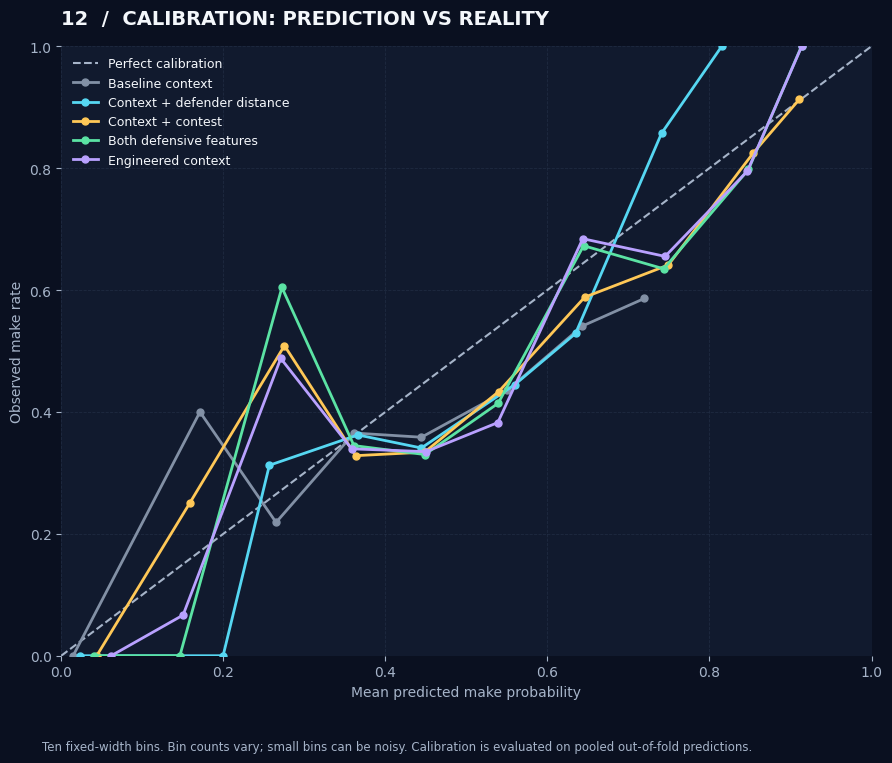

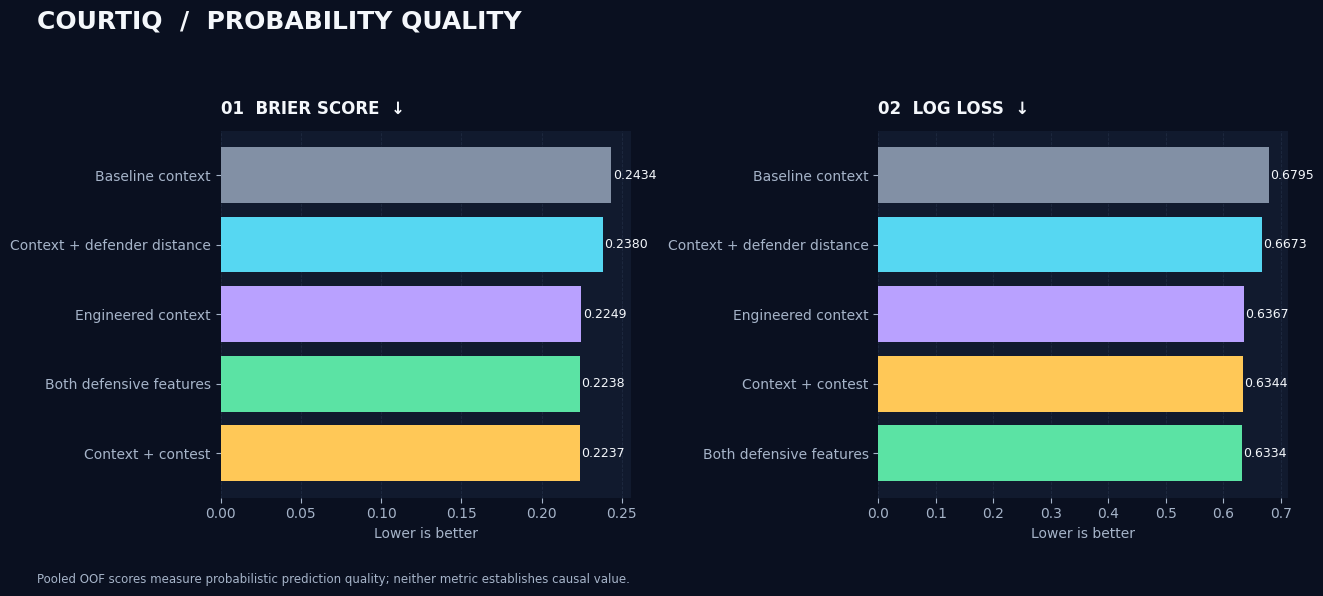

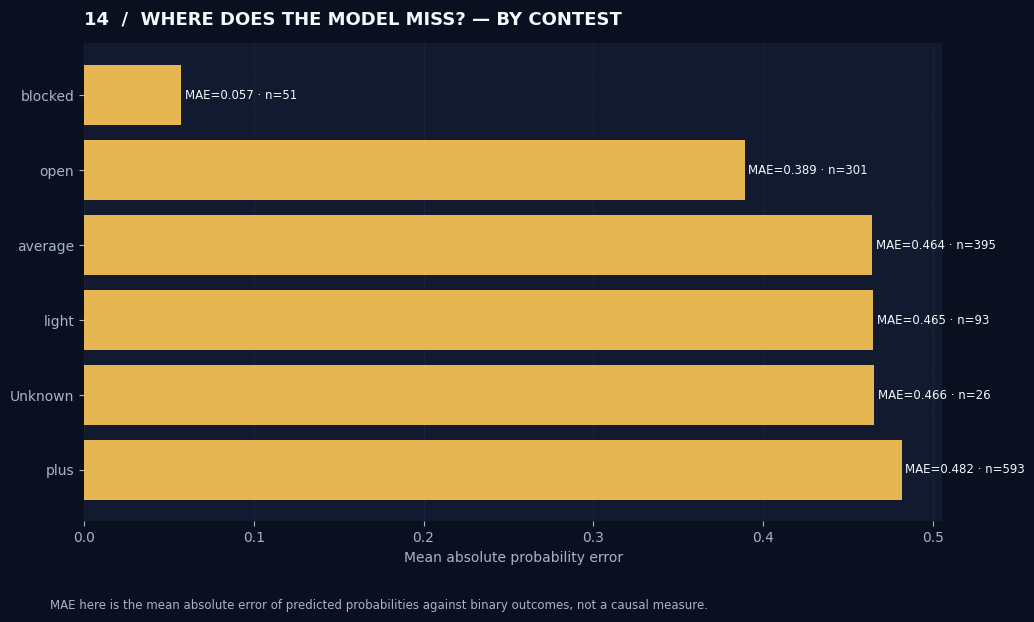


COURTIQ — CELL 8 COMPLETE
Shot-ID match rate: 100.0%
Available models: 5
Highest ROC-AUC: Context + contest = 0.6549
Lowest Brier: Context + contest = 0.2237
Lowest weighted calibration gap: Baseline context = 0.0778

Submission bundle:
/kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip

Calibration and error-analysis note:
/kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_CALIBRATION_ERROR_ANALYSIS.md

Reminder: calibration and segment diagnostics are exploratory; 10 games is a small sample.


In [17]:

# =============================================================================
# COURTIQ — CELL 8: CALIBRATION, ERROR ANALYSIS & SUBMISSION PACK
# =============================================================================

from pathlib import Path
import json
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
)

warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
VIS = ROOT / "courtiq_visuals"
VIS.mkdir(parents=True, exist_ok=True)

DATA_PATH = ROOT / "courtiq_context_engineered_dataset.csv"
OOF_PATH = ROOT / "courtiq_oof_predictions_v2.csv"
LONG_PATH = ROOT / "courtiq_logo_predictions_v2.csv"
EXPLORER_PATH = ROOT / "courtiq_shot_explorer.csv"

MODEL_IDS = [
    "baseline_shot_context",
    "plus_closest_defender",
    "plus_contest_level",
    "both_defensive_features",
    "engineered_context",
]

DISPLAY = {
    "baseline_shot_context": "Baseline context",
    "plus_closest_defender": "Context + defender distance",
    "plus_contest_level": "Context + contest",
    "both_defensive_features": "Both defensive features",
    "engineered_context": "Engineered context",
}

COLORS = {
    "baseline_shot_context": "#8290A5",
    "plus_closest_defender": "#56D7F2",
    "plus_contest_level": "#FFC857",
    "both_defensive_features": "#5BE3A4",
    "engineered_context": "#B9A1FF",
}

BG = "#0A1020"
PANEL = "#111A2E"
WHITE = "#F4F7FB"
MUTED = "#A6B4C9"
CYAN = "#56D7F2"
GOLD = "#FFC857"
GREEN = "#5BE3A4"
PURPLE = "#B9A1FF"
RED = "#FF7885"

# ---- 1. Load shot identities and OOF predictions -----------------------------

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing dataset: {DATA_PATH}")
if not OOF_PATH.exists() and not LONG_PATH.exists():
    raise FileNotFoundError("Neither wide nor long OOF prediction file exists.")

shots = pd.read_csv(DATA_PATH)
oof = pd.read_csv(OOF_PATH) if OOF_PATH.exists() else None
long_pred = pd.read_csv(LONG_PATH) if LONG_PATH.exists() else None

def col_match(df, names):
    lookup = {str(c).lower(): c for c in df.columns}
    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

shot_id_col = col_match(shots, ["shot_row_id", "event_id", "shot_id"])
game_col = col_match(shots, ["source_game_id", "game_id", "gameId"])
target_col = col_match(shots, ["target_made", "made", "is_made", "shot_made"])

if shot_id_col is None or target_col is None or game_col is None:
    raise ValueError(
        "Required identity, game, or target column missing.\n"
        f"Columns found: {shots.columns.tolist()}"
    )

shots = shots.copy()
shots["shot_row_id"] = shots[shot_id_col].astype(str)
shots["game_id"] = shots[game_col].astype(str)
shots["target_made"] = pd.to_numeric(shots[target_col], errors="coerce")

shots = shots.loc[shots["target_made"].isin([0, 1])].copy()
shots["target_made"] = shots["target_made"].astype(int)

if shots["shot_row_id"].duplicated().any():
    raise ValueError("Duplicate shot IDs detected in the source dataset.")

# Wide OOF columns must be identified by model name, not assumed positional order.
wide_predictions = None
wide_mapping = {}

if oof is not None:
    oof_id_col = col_match(oof, ["shot_row_id", "event_id", "shot_id"])
    if oof_id_col is not None:
        oof = oof.copy()
        oof["shot_row_id"] = oof[oof_id_col].astype(str)

        for model_id in MODEL_IDS:
            candidates = [
                c for c in oof.columns
                if model_id in str(c)
                and c != "shot_row_id"
                and pd.api.types.is_numeric_dtype(oof[c])
            ]
            if candidates:
                wide_mapping[model_id] = candidates[0]

        if wide_mapping:
            selected = ["shot_row_id"] + list(wide_mapping.values())
            wide_predictions = oof[selected].copy()
            wide_predictions = wide_predictions.rename(
                columns={v: k for k, v in wide_mapping.items()}
            )

# Long-form fallback, if needed.
if wide_predictions is None and long_pred is not None:
    lp_id = col_match(long_pred, ["shot_row_id", "event_id", "shot_id"])
    lp_model = col_match(long_pred, ["model", "model_name"])
    lp_prob = col_match(long_pred, [
        "probability", "predicted_probability", "prediction",
        "y_pred_proba", "oof_probability"
    ])

    if lp_id and lp_model and lp_prob:
        lp = long_pred[[lp_id, lp_model, lp_prob]].copy()
        lp.columns = ["shot_row_id", "model", "probability"]
        lp["shot_row_id"] = lp["shot_row_id"].astype(str)
        lp["model"] = lp["model"].astype(str)
        lp["probability"] = pd.to_numeric(lp["probability"], errors="coerce")
        lp = lp[lp["model"].isin(MODEL_IDS)]
        wide_predictions = lp.pivot_table(
            index="shot_row_id",
            columns="model",
            values="probability",
            aggfunc="first"
        ).reset_index()
        wide_predictions.columns.name = None

if wide_predictions is None:
    raise ValueError(
        "Unable to locate model prediction columns. "
        f"Wide OOF columns: {list(oof.columns) if oof is not None else 'not available'}"
    )

wide_predictions["shot_row_id"] = wide_predictions["shot_row_id"].astype(str)
if wide_predictions["shot_row_id"].duplicated().any():
    raise ValueError("OOF prediction file has duplicate shot IDs.")

data = shots.merge(
    wide_predictions,
    on="shot_row_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

matched_fraction = float((data["_merge"] == "both").mean())
data.drop(columns="_merge", inplace=True)

available_models = [
    m for m in MODEL_IDS
    if m in data.columns and pd.to_numeric(data[m], errors="coerce").notna().any()
]
if not available_models:
    raise ValueError(
        "No usable model predictions were found after joining by shot identity."
    )

for model_id in available_models:
    data[model_id] = pd.to_numeric(data[model_id], errors="coerce")

# ---- 2. Data integrity audit -------------------------------------------------

audit_rows = []
for model_id in available_models:
    p = data[model_id]
    valid = p.notna()
    audit_rows.append({
        "model": model_id,
        "display_name": DISPLAY.get(model_id, model_id),
        "shots_total": len(data),
        "predictions_present": int(valid.sum()),
        "coverage": float(valid.mean()),
        "out_of_range_predictions": int(((p < 0) | (p > 1)).sum()),
        "nonfinite_predictions": int((~np.isfinite(p.dropna())).sum()),
        "unique_shot_ids": int(data.loc[valid, "shot_row_id"].nunique()),
    })

integrity = pd.DataFrame(audit_rows)
integrity.to_csv(ROOT / "courtiq_cell8_integrity_audit.csv", index=False)

print("=" * 76)
print("COURTIQ — CELL 8 DATA INTEGRITY")
print("=" * 76)
print(f"Source shots: {len(data):,}")
print(f"Unique shot identities: {data['shot_row_id'].nunique():,}")
print(f"Games: {data['game_id'].nunique()}")
print(f"Rows matched by shot ID: {matched_fraction:.1%}")
print(integrity.to_string(index=False))

if (integrity["out_of_range_predictions"] > 0).any():
    raise ValueError("Some predictions are outside [0, 1]. Investigate before continuing.")

# ---- 3. Recompute pooled out-of-fold metrics ---------------------------------

metric_rows = []
for model_id in available_models:
    valid = data[model_id].notna()
    y = data.loc[valid, "target_made"].to_numpy(dtype=int)
    p = data.loc[valid, model_id].to_numpy(dtype=float)

    if len(np.unique(y)) < 2:
        auc = np.nan
    else:
        auc = roc_auc_score(y, p)

    # Clip only for log loss numerical stability.
    p_safe = np.clip(p, 1e-7, 1 - 1e-7)

    metric_rows.append({
        "model": model_id,
        "display_name": DISPLAY.get(model_id, model_id),
        "shots": len(y),
        "games": data.loc[valid, "game_id"].nunique(),
        "roc_auc": auc,
        "brier_score": brier_score_loss(y, p),
        "log_loss": log_loss(y, p_safe, labels=[0, 1]),
        "accuracy_at_0_5": accuracy_score(y, p >= 0.5),
        "mean_predicted_probability": float(np.mean(p)),
        "observed_make_rate": float(np.mean(y)),
    })

recomputed = pd.DataFrame(metric_rows)
recomputed.to_csv(ROOT / "courtiq_cell8_recomputed_oof_metrics.csv", index=False)

print("\nRECOMPUTED METRICS")
print(recomputed.round(4).to_string(index=False))

# ---- 4. Calibration table and expected calibration error ---------------------

calibration_rows = []
N_BINS = 10

for model_id in available_models:
    valid = data[model_id].notna()
    tmp = data.loc[valid, ["target_made", model_id]].copy()
    tmp = tmp.rename(columns={model_id: "probability"})
    tmp["probability"] = tmp["probability"].clip(0, 1)

    # Fixed-width bins provide comparable calibration intervals across models.
    tmp["bin"] = pd.cut(
        tmp["probability"],
        bins=np.linspace(0, 1, N_BINS + 1),
        include_lowest=True,
        duplicates="drop",
    )

    for bin_label, group in tmp.groupby("bin", observed=True):
        if group.empty:
            continue
        calibration_rows.append({
            "model": model_id,
            "display_name": DISPLAY.get(model_id, model_id),
            "bin": str(bin_label),
            "bin_midpoint": float(group["probability"].mean()),
            "observed_rate": float(group["target_made"].mean()),
            "mean_predicted_probability": float(group["probability"].mean()),
            "count": int(len(group)),
            "absolute_calibration_gap": abs(
                float(group["target_made"].mean())
                - float(group["probability"].mean())
            ),
        })

calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(ROOT / "courtiq_cell8_calibration_bins.csv", index=False)

ece_rows = []
for model_id in available_models:
    subset = calibration[calibration["model"] == model_id]
    n = subset["count"].sum()
    ece = (
        float((subset["count"] * subset["absolute_calibration_gap"]).sum() / n)
        if n else np.nan
    )
    ece_rows.append({
        "model": model_id,
        "display_name": DISPLAY.get(model_id, model_id),
        "weighted_calibration_gap": ece,
        "shots_in_calibration": int(n),
    })

ece = pd.DataFrame(ece_rows)
ece.to_csv(ROOT / "courtiq_cell8_calibration_summary.csv", index=False)

# ---- 5. Plot 12: reliability / calibration ----------------------------------

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "savefig.facecolor": BG,
    "text.color": WHITE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.edgecolor": "#2B3850",
    "grid.color": "#2B3850",
    "grid.alpha": 0.55,
})

fig, ax = plt.subplots(figsize=(9.5, 8))
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED,
        linewidth=1.5, label="Perfect calibration")

for model_id in available_models:
    sub = calibration[calibration["model"] == model_id].sort_values("bin_midpoint")
    if sub.empty:
        continue
    ax.plot(
        sub["mean_predicted_probability"],
        sub["observed_rate"],
        marker="o", linewidth=2, markersize=5,
        color=COLORS.get(model_id, CYAN),
        label=DISPLAY.get(model_id, model_id),
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted make probability")
ax.set_ylabel("Observed make rate")
ax.set_title(
    "12  /  CALIBRATION: PREDICTION VS REALITY",
    loc="left", color=WHITE, pad=16, fontsize=14, weight="bold"
)
ax.grid(True, linestyle="--", linewidth=0.6)
ax.legend(frameon=False, labelcolor=WHITE, loc="upper left", fontsize=9)
for s in ax.spines.values():
    s.set_visible(False)

fig.text(
    0.08, 0.025,
    "Ten fixed-width bins. Bin counts vary; small bins can be noisy. "
    "Calibration is evaluated on pooled out-of-fold predictions.",
    color=MUTED, fontsize=8.5
)
fig.tight_layout(rect=[0.03, 0.07, 0.98, 0.97])
fig.savefig(VIS / "12_oof_calibration_reliability.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 6. Plot 13: model-specific Brier and log-loss ----------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    "COURTIQ  /  PROBABILITY QUALITY",
    x=0.06, y=0.98, ha="left", fontsize=18, weight="bold", color=WHITE
)

mplot = recomputed.sort_values("brier_score", ascending=False).reset_index(drop=True)
axes[0].barh(
    mplot["display_name"],
    mplot["brier_score"],
    color=[COLORS.get(m, CYAN) for m in mplot["model"]],
)
axes[0].invert_yaxis()
for i, r in mplot.iterrows():
    axes[0].text(
        r["brier_score"] + 0.001, i, f'{r["brier_score"]:.4f}',
        va="center", color=WHITE, fontsize=9
    )
axes[0].set_title("01  BRIER SCORE  ↓", loc="left", color=WHITE, pad=12)
axes[0].set_xlabel("Lower is better")
axes[0].grid(axis="x", linestyle="--", linewidth=0.6)
axes[0].set_axisbelow(True)

lplot = recomputed.sort_values("log_loss", ascending=False).reset_index(drop=True)
axes[1].barh(
    lplot["display_name"],
    lplot["log_loss"],
    color=[COLORS.get(m, CYAN) for m in lplot["model"]],
)
axes[1].invert_yaxis()
for i, r in lplot.iterrows():
    axes[1].text(
        r["log_loss"] + 0.002, i, f'{r["log_loss"]:.4f}',
        va="center", color=WHITE, fontsize=9
    )
axes[1].set_title("02  LOG LOSS  ↓", loc="left", color=WHITE, pad=12)
axes[1].set_xlabel("Lower is better")
axes[1].grid(axis="x", linestyle="--", linewidth=0.6)
axes[1].set_axisbelow(True)

for ax in axes:
    for s in ax.spines.values():
        s.set_visible(False)

fig.text(
    0.06, 0.025,
    "Pooled OOF scores measure probabilistic prediction quality; neither metric establishes causal value.",
    color=MUTED, fontsize=8.5
)
fig.tight_layout(rect=[0.03, 0.07, 0.98, 0.92])
fig.savefig(VIS / "13_probability_quality.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 7. Segment analysis: distance, contest, three-point, game ----------------

def first_col(df, candidates):
    return col_match(df, candidates)

distance_col = first_col(data, ["distance", "distance_value", "shot_distance", "shotDistance"])
contest_col = first_col(data, ["contestLevel", "contest_level", "contest_value", "contest"])
three_col = first_col(data, ["three", "is_three", "three_pointer"])
defender_col = first_col(data, [
    "closestDefDist", "closest_defender_distance", "defender_distance_value"
])
clock_col = first_col(data, ["shotClock", "shot_clock", "shot_clock_value"])
type_col = first_col(data, ["shotType", "shot_type", "shot_type_value"])

segments = []
segment_specs = []

if distance_col:
    numeric = pd.to_numeric(data[distance_col], errors="coerce")
    try:
        distance_bins = pd.qcut(numeric, q=5, duplicates="drop")
        segment_specs.append(("distance_band", distance_bins.astype("string")))
    except Exception:
        pass

if contest_col:
    segment_specs.append(("contest", data[contest_col].astype("string").fillna("Unknown")))

if three_col:
    segment_specs.append(("three_indicator", data[three_col].astype("string").fillna("Unknown")))

if type_col:
    segment_specs.append(("shot_type", data[type_col].astype("string").fillna("Unknown")))

# For each model, compute segment outcomes, errors and coverage.
for segment_name, segment_values in segment_specs:
    tmp = data.copy()
    tmp["_segment"] = segment_values

    for segment_value, grp in tmp.groupby("_segment", dropna=False):
        if len(grp) < 10:
            # Keep small groups visible, but mark their estimates as low sample.
            sample_flag = "small_n"
        else:
            sample_flag = "n>=10"

        for model_id in available_models:
            valid = grp[model_id].notna()
            pred_grp = grp.loc[valid]
            if pred_grp.empty:
                continue

            p = pred_grp[model_id].to_numpy(float)
            y = pred_grp["target_made"].to_numpy(int)

            segments.append({
                "segment_type": segment_name,
                "segment": str(segment_value),
                "model": model_id,
                "display_name": DISPLAY.get(model_id, model_id),
                "shots_total": int(len(grp)),
                "predictions_available": int(len(pred_grp)),
                "coverage": float(valid.mean()),
                "observed_make_rate": float(y.mean()),
                "mean_predicted_probability": float(p.mean()),
                "mean_absolute_probability_error": float(np.mean(np.abs(p - y))),
                "brier_score": float(np.mean((p - y) ** 2)),
                "sample_flag": sample_flag,
            })

segment_df = pd.DataFrame(segments)
segment_path = ROOT / "courtiq_cell8_segment_error_analysis.csv"
segment_df.to_csv(segment_path, index=False)

# ---- 8. Plot 14: contest-segment prediction gaps -----------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))
if not segment_df.empty and "contest" in segment_df["segment_type"].values:
    contest_err = segment_df[
        (segment_df["segment_type"] == "contest") &
        (segment_df["model"] == "plus_contest_level")
    ].copy()

    if not contest_err.empty:
        contest_err = contest_err.sort_values("mean_absolute_probability_error")
        ax.barh(
            contest_err["segment"],
            contest_err["mean_absolute_probability_error"],
            color=GOLD, alpha=0.9
        )
        for i, r in contest_err.reset_index(drop=True).iterrows():
            ax.text(
                r["mean_absolute_probability_error"] + 0.002, i,
                f'MAE={r["mean_absolute_probability_error"]:.3f} · n={int(r["predictions_available"])}',
                va="center", color=WHITE, fontsize=8.5
            )
        ax.set_xlabel("Mean absolute probability error")
        ax.set_title(
            "14  /  WHERE DOES THE MODEL MISS? — BY CONTEST",
            loc="left", color=WHITE, pad=14, fontsize=13, weight="bold"
        )
        ax.grid(axis="x", linestyle="--", linewidth=0.6)
        ax.set_axisbelow(True)
        ax.invert_yaxis()
        for s in ax.spines.values():
            s.set_visible(False)
    else:
        ax.text(0.5, 0.5, "No usable contest-segment rows",
                ha="center", va="center", color=MUTED, transform=ax.transAxes)
else:
    ax.text(
        0.5, 0.5,
        "Contest feature not available for segment error analysis",
        ha="center", va="center", color=MUTED, transform=ax.transAxes
    )

fig.text(
    0.08, 0.025,
    "MAE here is the mean absolute error of predicted probabilities against binary outcomes, not a causal measure.",
    color=MUTED, fontsize=8.5
)
fig.tight_layout(rect=[0.03, 0.07, 0.98, 0.97])
fig.savefig(VIS / "14_contest_segment_error.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---- 9. Export shot-level errors for all available models ---------------------

error_rows = data[["shot_row_id", "game_id", "target_made"]].copy()
for model_id in available_models:
    error_rows[f"{model_id}_probability"] = data[model_id]
    error_rows[f"{model_id}_absolute_error"] = (
        data[model_id] - data["target_made"]
    ).abs()
    error_rows[f"{model_id}_squared_error"] = (
        data[model_id] - data["target_made"]
    ) ** 2

error_rows.to_csv(ROOT / "courtiq_cell8_shot_level_errors.csv", index=False)

# ---- 10. Research note -------------------------------------------------------

best_auc_row = recomputed.loc[recomputed["roc_auc"].idxmax()]
best_brier_row = recomputed.loc[recomputed["brier_score"].idxmin()]
best_ece_row = ece.loc[ece["weighted_calibration_gap"].idxmin()]

note = f"""# CourtIQ — Calibration and Error Analysis

## Scope
This audit evaluates existing out-of-fold probabilities. It does not retrain
models or claim that predictive features cause shot outcomes.

- Source rows: {len(data):,}
- Unique shot IDs: {data['shot_row_id'].nunique():,}
- Games: {data['game_id'].nunique()}
- Shot-identity match rate: {matched_fraction:.1%}
- Models evaluated: {len(available_models)}

## Results from recomputed out-of-fold predictions
- Highest observed ROC-AUC: {best_auc_row['display_name']} ({best_auc_row['roc_auc']:.4f})
- Lowest observed Brier score: {best_brier_row['display_name']} ({best_brier_row['brier_score']:.4f})
- Lowest weighted calibration gap: {best_ece_row['display_name']} ({best_ece_row['weighted_calibration_gap']:.4f})

The weighted calibration gap is a descriptive summary over ten fixed-width
probability bins. It is sensitive to binning and sample size and should not be
treated as a definitive calibration test.

## Required interpretation
1. ROC-AUC measures ranking discrimination, not the correctness of every probability.
2. Brier score and log loss summarize probabilistic prediction quality.
3. Calibration plots compare average predictions with observed frequencies.
4. Segment error analysis may identify where additional data or annotation review
   is warranted; it does not establish why the errors occur.
5. Only ten independent games are available. Additional games and an external
   validation set are needed before generalization claims.

## Artifacts
- `courtiq_cell8_integrity_audit.csv`
- `courtiq_cell8_recomputed_oof_metrics.csv`
- `courtiq_cell8_calibration_bins.csv`
- `courtiq_cell8_calibration_summary.csv`
- `courtiq_cell8_segment_error_analysis.csv`
- `courtiq_cell8_shot_level_errors.csv`
- `courtiq_visuals/12_oof_calibration_reliability.png`
- `courtiq_visuals/13_probability_quality.png`
- `courtiq_visuals/14_contest_segment_error.png`
"""

note_path = ROOT / "COURTIQ_CALIBRATION_ERROR_ANALYSIS.md"
note_path.write_text(note, encoding="utf-8")

# ---- 11. Create complete submission bundle ----------------------------------

pack_path = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip"

include_files = [
    ROOT / "COURTIQ_STATISTICAL_EVIDENCE_BRIEF.md",
    ROOT / "COURTIQ_COACH_RESEARCH_BRIEF.md",
    ROOT / "courtiq_shot_intelligence_dashboard.html",
    ROOT / "courtiq_shot_explorer.csv",
    ROOT / "courtiq_game_context_summary.csv",
    ROOT / "courtiq_logo_metrics_v2.csv",
    ROOT / "courtiq_logo_fold_results_v2.csv",
    ROOT / "courtiq_oof_predictions_v2.csv",
    ROOT / "courtiq_logo_predictions_v2.csv",
    ROOT / "courtiq_robustness_observed_metrics.csv",
    ROOT / "courtiq_robustness_per_game_comparisons.csv",
    ROOT / "courtiq_robustness_per_game_summary.csv",
    ROOT / "courtiq_game_cluster_bootstrap_model_ci.csv",
    ROOT / "courtiq_game_cluster_bootstrap_comparison_ci.csv",
    ROOT / "courtiq_visual_metrics_verified.csv",
    ROOT / "courtiq_per_game_metrics_v2.csv",
    ROOT / "courtiq_cell8_integrity_audit.csv",
    ROOT / "courtiq_cell8_recomputed_oof_metrics.csv",
    ROOT / "courtiq_cell8_calibration_bins.csv",
    ROOT / "courtiq_cell8_calibration_summary.csv",
    ROOT / "courtiq_cell8_segment_error_analysis.csv",
    ROOT / "courtiq_cell8_shot_level_errors.csv",
    note_path,
]

include_files += [
    VIS / "08_courtiq_research_showcase.png",
    VIS / "08_courtiq_research_showcase.svg",
    VIS / "09_shot_difficulty_landscape.png",
    VIS / "10_contest_impact_analysis.png",
    VIS / "11_game_consistency_dashboard.png",
    VIS / "12_oof_calibration_reliability.png",
    VIS / "13_probability_quality.png",
    VIS / "14_contest_segment_error.png",
]

with zipfile.ZipFile(pack_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in include_files:
        if p.exists():
            zf.write(p, arcname=str(p.relative_to(ROOT)))
        else:
            print(f"Optional artifact not found; skipped: {p.name}")

print("\n" + "=" * 76)
print("COURTIQ — CELL 8 COMPLETE")
print("=" * 76)
print(f"Shot-ID match rate: {matched_fraction:.1%}")
print(f"Available models: {len(available_models)}")
print(f"Highest ROC-AUC: {best_auc_row['display_name']} = {best_auc_row['roc_auc']:.4f}")
print(f"Lowest Brier: {best_brier_row['display_name']} = {best_brier_row['brier_score']:.4f}")
print(f"Lowest weighted calibration gap: {best_ece_row['display_name']} = {best_ece_row['weighted_calibration_gap']:.4f}")
print("\nSubmission bundle:")
print(pack_path)
print("\nCalibration and error-analysis note:")
print(note_path)
print("\nReminder: calibration and segment diagnostics are exploratory; 10 games is a small sample.")

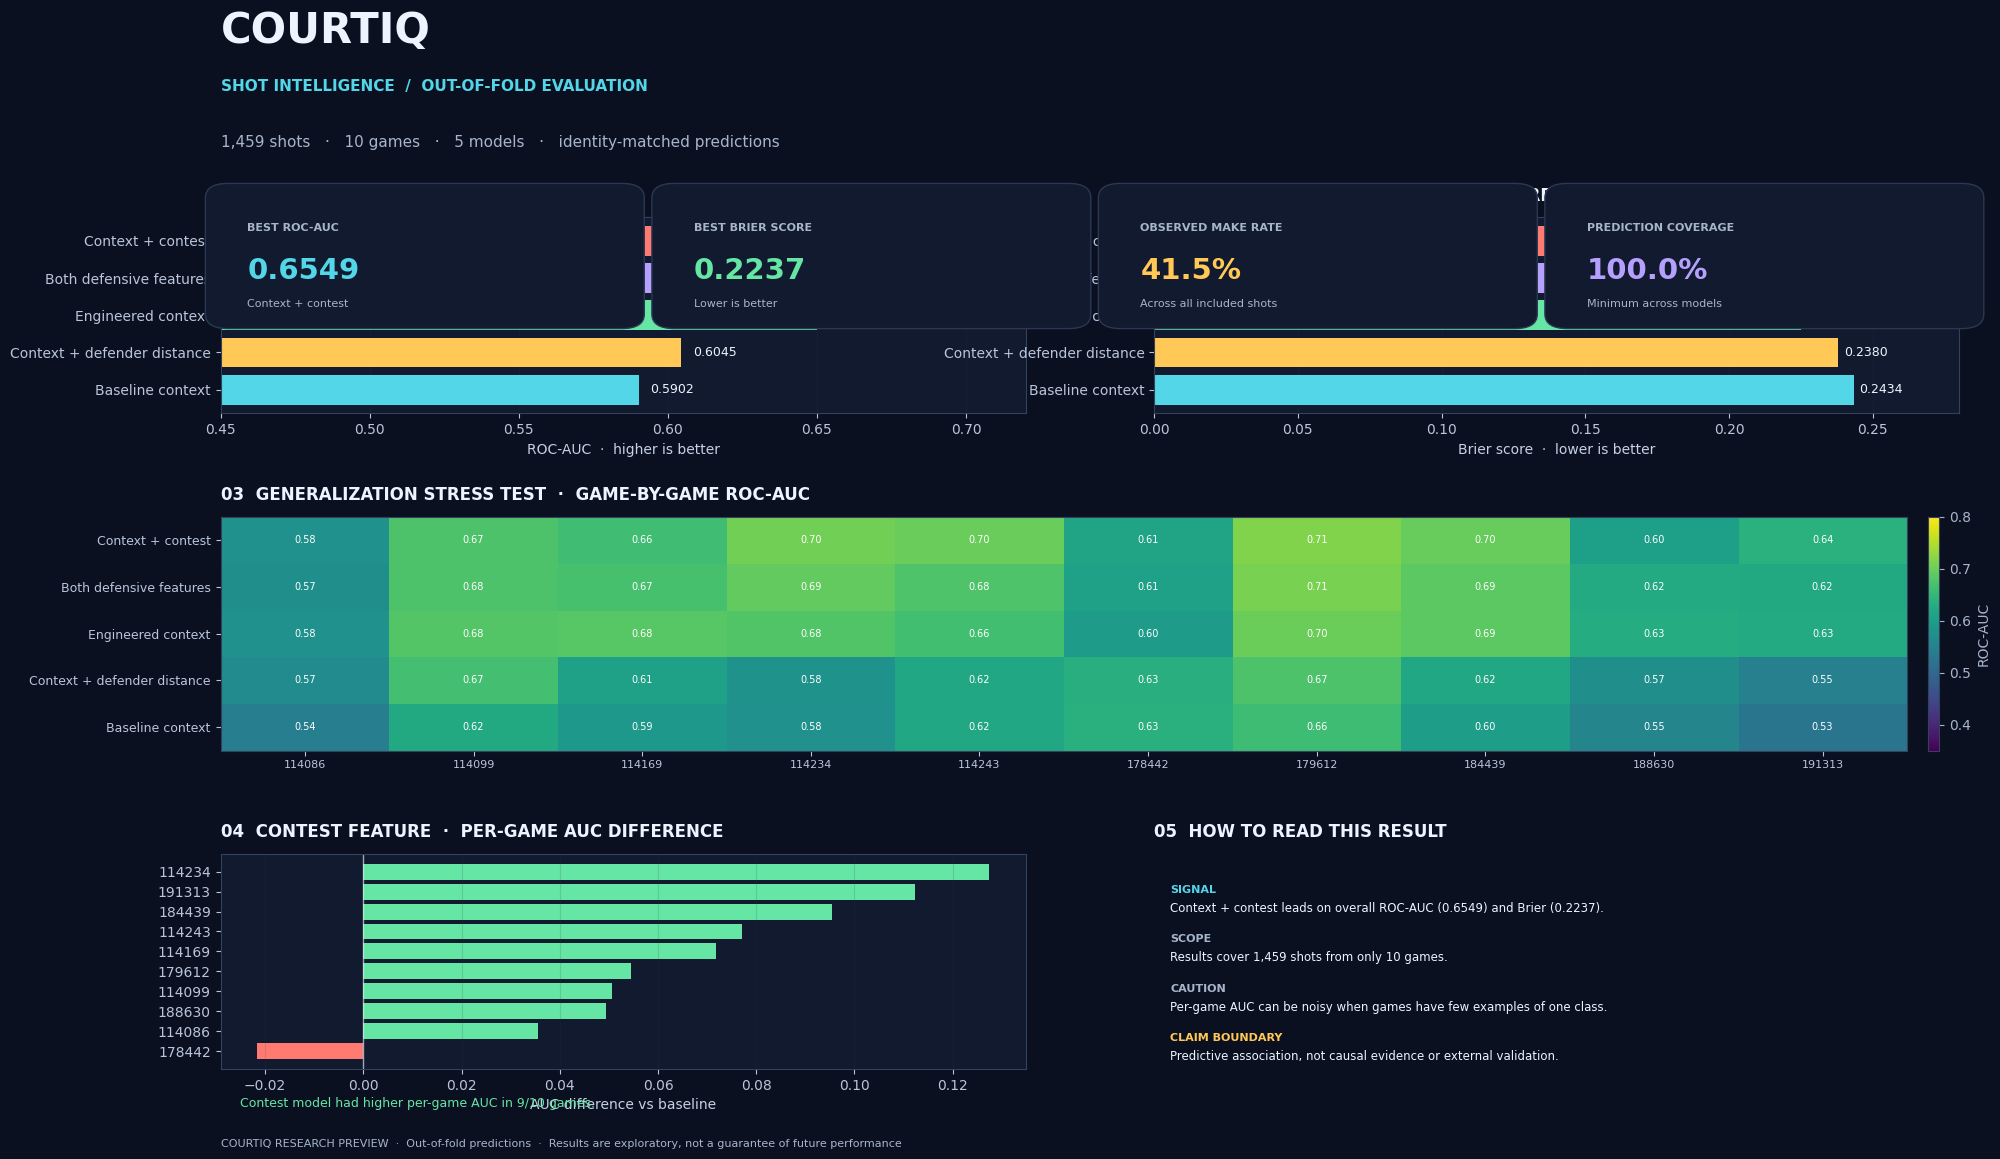


COURTIQ — CELL 9 RELEASE AUDIT
Source shots:                 1,459
Unique shot IDs:              1,459
Games:                        10
Models:                       5
Minimum OOF coverage:         100.0%
Maximum invalid probabilities:   0
Best ROC-AUC:                 Context + contest (0.6549)
Best Brier:                   Context + contest (0.2237)
ZIP integrity:                PASS
Files in ZIP:                 75

KEY OUTPUTS
Dashboard PNG: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/15_courtiq_competition_dashboard.png
Dashboard SVG: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_visuals/15_courtiq_competition_dashboard.svg
Interactive/portable HTML: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_COMPETITION_EVIDENCE_DASHBOARD.html
Release manifest: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_RELEASE_MANIFEST.csv
Release summary: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_RELEASE_SU

In [18]:

# ============================================================================
# COURTIQ — CELL 9: COMPETITION RELEASE STUDIO
# Publication-style visual dashboard + per-game robustness + release audit
# ============================================================================

from pathlib import Path
import os, json, zipfile, hashlib, warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
VIS = ROOT / "courtiq_visuals"
VIS.mkdir(parents=True, exist_ok=True)

DATA_PATH = ROOT / "courtiq_context_engineered_dataset.csv"
if not DATA_PATH.exists():
    DATA_PATH = ROOT / "tables" / "courtiq_shot_dataset.csv"

METRICS_PATH = ROOT / "courtiq_cell8_recomputed_oof_metrics.csv"
WIDE_PATH = ROOT / "courtiq_oof_predictions_v2.csv"
LONG_PATH = ROOT / "courtiq_logo_predictions_v2.csv"

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
assert METRICS_PATH.exists(), f"Cell 8 metrics not found: {METRICS_PATH}"
assert WIDE_PATH.exists() or LONG_PATH.exists(), "No OOF prediction file found."

df = pd.read_csv(DATA_PATH)
metrics = pd.read_csv(METRICS_PATH)

# ----------------------------- Helpers --------------------------------------

def find_col(frame, candidates, required=True):
    lower = {str(c).lower(): c for c in frame.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    for c in frame.columns:
        cl = str(c).lower()
        if any(x.lower() in cl for x in candidates):
            return c
    if required:
        raise KeyError(f"Could not find any of {candidates}; columns={list(frame.columns)}")
    return None

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in str(s)).strip("_").lower()

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

id_col = find_col(df, ["shot_row_id"])
target_col = find_col(df, ["target_made", "made", "shot_made_flag"])
game_col = find_col(df, ["source_game_id", "game_id"])

df[id_col] = df[id_col].astype(str)
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df[game_col] = df[game_col].astype(str)

assert df[id_col].is_unique, "Source shot IDs are not unique."
assert df[target_col].notna().all(), "Target contains missing values."
assert set(df[target_col].unique()).issubset({0, 1}), "Target is not binary."

# ------------------------ Reconstruct OOF join -------------------------------

wide = None
if WIDE_PATH.exists():
    candidate = pd.read_csv(WIDE_PATH)
    if id_col in candidate.columns:
        candidate[id_col] = candidate[id_col].astype(str)
        wide = candidate

if wide is not None:
    joined = df.merge(wide, on=id_col, how="left", suffixes=("", "_pred"))
else:
    long = pd.read_csv(LONG_PATH)
    long_id = find_col(long, ["shot_row_id"])
    long_model = find_col(long, ["model"])
    long_pred = find_col(long, ["prediction", "predicted_probability", "oof_prediction"])
    long = long.rename(columns={long_id: id_col, long_model: "_model", long_pred: "_prediction"})
    long[id_col] = long[id_col].astype(str)
    pivot = long.pivot(index=id_col, columns="_model", values="_prediction").reset_index()
    joined = df.merge(pivot, on=id_col, how="left", suffixes=("", "_pred"))

# Map models to probability columns using model IDs from Cell 8 metrics.
model_specs = []
for _, row in metrics.iterrows():
    model_id = str(row["model"])
    display = str(row.get("display_name", model_id))

    if wide is not None:
        candidates = [
            c for c in joined.columns
            if c != id_col and model_id.lower() in str(c).lower()
            and pd.api.types.is_numeric_dtype(joined[c])
        ]
        # Prefer an exact model-named column or one explicitly containing "pred".
        candidates.sort(key=lambda c: (
            0 if str(c).lower() == model_id.lower() else 1,
            0 if "pred" in str(c).lower() or "prob" in str(c).lower() else 1,
            len(str(c))
        ))
        pred_col = candidates[0] if candidates else None
    else:
        pred_col = model_id if model_id in joined.columns else None

    if pred_col is None:
        # Last resort: use an unambiguous matching probability column.
        candidates = [
            c for c in joined.columns
            if model_id.lower() in str(c).lower()
            and pd.api.types.is_numeric_dtype(joined[c])
        ]
        if len(candidates) == 1:
            pred_col = candidates[0]

    if pred_col is None:
        raise KeyError(
            f"Could not map model {model_id} to a prediction column. "
            f"Prediction-like columns: {[c for c in joined.columns if 'pred' in str(c).lower() or 'prob' in str(c).lower()]}"
        )

    joined[pred_col] = pd.to_numeric(joined[pred_col], errors="coerce")
    model_specs.append({
        "model": model_id,
        "display_name": display,
        "prediction_col": pred_col
    })

# ------------------------- Recompute game metrics ----------------------------

y_all = joined[target_col].to_numpy()
game_rows = []
coverage_rows = []

for spec in model_specs:
    p_all = joined[spec["prediction_col"]].to_numpy(dtype=float)
    valid = np.isfinite(p_all) & np.isfinite(y_all)
    coverage_rows.append({
        "model": spec["model"],
        "display_name": spec["display_name"],
        "source_shots": int(len(df)),
        "matched_shots": int(joined[id_col].notna().sum()),
        "valid_predictions": int(valid.sum()),
        "coverage": float(valid.sum() / len(df)),
        "out_of_range": int(((p_all[valid] < 0) | (p_all[valid] > 1)).sum())
    })

    for game, idx in joined.groupby(game_col).groups.items():
        part = joined.loc[idx]
        y = part[target_col].to_numpy(dtype=int)
        p = part[spec["prediction_col"]].to_numpy(dtype=float)
        ok = np.isfinite(p) & np.isfinite(y)
        y, p = y[ok], p[ok]
        if len(y) == 0:
            continue
        auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
        game_rows.append({
            "game_id": str(game),
            "model": spec["model"],
            "display_name": spec["display_name"],
            "shots": int(len(y)),
            "observed_make_rate": float(y.mean()),
            "roc_auc": float(auc) if np.isfinite(auc) else np.nan,
            "brier_score": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, np.clip(p, 1e-7, 1-1e-7), labels=[0, 1]))
        })

game_metrics = pd.DataFrame(game_rows)
coverage = pd.DataFrame(coverage_rows)
game_metrics.to_csv(ROOT / "courtiq_cell9_per_game_metrics.csv", index=False)
coverage.to_csv(ROOT / "courtiq_cell9_release_coverage_audit.csv", index=False)

# ------------------------------ Design ---------------------------------------

plt.rcParams.update({
    "figure.facecolor": "#0b1020",
    "axes.facecolor": "#111a2e",
    "savefig.facecolor": "#0b1020",
    "text.color": "#edf3ff",
    "axes.labelcolor": "#c6d1e6",
    "xtick.color": "#b9c5da",
    "ytick.color": "#b9c5da",
    "axes.edgecolor": "#34415b",
    "font.family": "DejaVu Sans",
    "font.size": 10,
})

navy = "#0b1020"
panel = "#111a2e"
white = "#edf3ff"
muted = "#a7b5cc"
cyan = "#52d6e8"
gold = "#ffc857"
coral = "#ff7b72"
green = "#65e6a5"
purple = "#b6a0ff"
colors = [cyan, gold, green, purple, coral]

# Order by the Cell 8 model metric table, descending AUC.
metrics_sorted = metrics.sort_values("roc_auc", ascending=False).reset_index(drop=True)
best = metrics_sorted.iloc[0]
best_name = str(best["display_name"])
best_auc = float(best["roc_auc"])
best_brier = float(best["brier_score"])
shot_count = int(len(df))
game_count = int(df[game_col].nunique())
make_rate = float(df[target_col].mean())

fig = plt.figure(figsize=(19, 12), facecolor=navy)
gs = fig.add_gridspec(
    3, 4, left=0.055, right=0.97, top=0.80, bottom=0.09,
    hspace=0.48, wspace=0.38,
    height_ratios=[1.05, 1.25, 1.15]
)

# Header / title.
fig.text(0.055, 0.945, "COURTIQ", fontsize=30, weight="bold", color=white)
fig.text(0.055, 0.905, "SHOT INTELLIGENCE  /  OUT-OF-FOLD EVALUATION",
         fontsize=11, color=cyan, weight="bold")
fig.text(0.055, 0.858,
         f"{shot_count:,} shots   ·   {game_count} games   ·   {len(model_specs)} models   ·   identity-matched predictions",
         fontsize=11, color=muted)

# KPI tiles.
kpis = [
    ("BEST ROC-AUC", f"{best_auc:.4f}", best_name, cyan),
    ("BEST BRIER SCORE", f"{best_brier:.4f}", "Lower is better", green),
    ("OBSERVED MAKE RATE", f"{make_rate:.1%}", "Across all included shots", gold),
    ("PREDICTION COVERAGE", f"{coverage['coverage'].min():.1%}", "Minimum across models", purple),
]
for i, (label, value, sub, col) in enumerate(kpis):
    x = 0.055 + i * 0.235
    tile = FancyBboxPatch(
        (x, 0.715), 0.215, 0.105,
        boxstyle="round,pad=0.008,rounding_size=0.012",
        transform=fig.transFigure, facecolor=panel,
        edgecolor="#2b3853", linewidth=1.0
    )
    fig.patches.append(tile)
    fig.text(x + 0.014, 0.788, label, fontsize=8, color=muted, weight="bold")
    fig.text(x + 0.014, 0.748, value, fontsize=21, color=col, weight="bold")
    fig.text(x + 0.014, 0.725, sub[:31], fontsize=8, color=muted)

# Panel 1: ROC-AUC.
ax1 = fig.add_subplot(gs[0, :2])
auc_df = metrics.sort_values("roc_auc", ascending=True)
bars = ax1.barh(auc_df["display_name"], auc_df["roc_auc"], color=colors[:len(auc_df)])
ax1.set_title("01  DISCRIMINATION  ·  ROC-AUC", loc="left", color=white, weight="bold", pad=12)
ax1.set_xlim(0.45, max(0.72, float(auc_df["roc_auc"].max()) + 0.06))
ax1.set_xlabel("ROC-AUC  ·  higher is better")
ax1.grid(axis="x", alpha=0.16)
ax1.set_axisbelow(True)
for bar, value in zip(bars, auc_df["roc_auc"]):
    ax1.text(value + 0.004, bar.get_y() + bar.get_height()/2, f"{value:.4f}",
             va="center", fontsize=9, color=white)

# Panel 2: Brier.
ax2 = fig.add_subplot(gs[0, 2:])
brier_df = metrics.sort_values("brier_score", ascending=False)
bars = ax2.barh(brier_df["display_name"], brier_df["brier_score"], color=colors[:len(brier_df)])
ax2.set_title("02  PROBABILITY QUALITY  ·  BRIER SCORE", loc="left", color=white, weight="bold", pad=12)
ax2.set_xlim(0, max(0.28, float(brier_df["brier_score"].max()) + 0.035))
ax2.set_xlabel("Brier score  ·  lower is better")
ax2.grid(axis="x", alpha=0.16)
ax2.set_axisbelow(True)
for bar, value in zip(bars, brier_df["brier_score"]):
    ax2.text(value + 0.002, bar.get_y() + bar.get_height()/2, f"{value:.4f}",
             va="center", fontsize=9, color=white)

# Panel 3: per-game AUC heatmap.
ax3 = fig.add_subplot(gs[1, :])
heat = game_metrics.pivot(index="display_name", columns="game_id", values="roc_auc")
# Order models by overall Cell 8 AUC.
model_order = metrics.sort_values("roc_auc", ascending=False)["display_name"].tolist()
heat = heat.reindex(model_order)
im = ax3.imshow(heat.to_numpy(), aspect="auto", cmap="viridis", vmin=0.35, vmax=0.80)
ax3.set_title("03  GENERALIZATION STRESS TEST  ·  GAME-BY-GAME ROC-AUC",
              loc="left", color=white, weight="bold", pad=12)
ax3.set_yticks(np.arange(len(heat.index)))
ax3.set_yticklabels(heat.index, fontsize=9)
ax3.set_xticks(np.arange(len(heat.columns)))
ax3.set_xticklabels([str(x)[:12] for x in heat.columns], rotation=0, fontsize=8)
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        val = heat.iloc[r, c]
        if np.isfinite(val):
            ax3.text(c, r, f"{val:.2f}", ha="center", va="center",
                     fontsize=7, color="white" if val < 0.72 else "#111827")
cb = fig.colorbar(im, ax=ax3, fraction=0.018, pad=0.012)
cb.set_label("ROC-AUC", color=muted)
cb.ax.yaxis.set_tick_params(color=muted)
plt.setp(cb.ax.get_yticklabels(), color=muted)

# Panel 4: per-game contest-vs-baseline differences.
ax4 = fig.add_subplot(gs[2, :2])
baseline_name = "Baseline context"
contest_name = "Context + contest"
if baseline_name in set(game_metrics["display_name"]) and contest_name in set(game_metrics["display_name"]):
    base = game_metrics[game_metrics["display_name"] == baseline_name][["game_id", "roc_auc"]]
    contest = game_metrics[game_metrics["display_name"] == contest_name][["game_id", "roc_auc"]]
    delta = base.merge(contest, on="game_id", suffixes=("_baseline", "_contest"))
    delta["auc_lift"] = delta["roc_auc_contest"] - delta["roc_auc_baseline"]
    delta = delta.sort_values("auc_lift")
    barcols = [green if v >= 0 else coral for v in delta["auc_lift"]]
    ax4.barh(delta["game_id"], delta["auc_lift"], color=barcols)
    ax4.axvline(0, color=white, linewidth=1, alpha=0.65)
    ax4.set_title("04  CONTEST FEATURE  ·  PER-GAME AUC DIFFERENCE",
                  loc="left", color=white, weight="bold", pad=12)
    ax4.set_xlabel("AUC difference vs baseline")
    ax4.grid(axis="x", alpha=0.16)
    wins = int((delta["auc_lift"] > 0).sum())
    fig.text(0.065, 0.058,
             f"Contest model had higher per-game AUC in {wins}/{len(delta)} games.",
             fontsize=9, color=green if wins >= len(delta)/2 else gold)
else:
    ax4.axis("off")
    ax4.text(0.03, 0.8, "Per-game comparison unavailable: model labels did not match expected names.",
             color=gold, transform=ax4.transAxes)

# Panel 5: limitations / reading guide.
ax5 = fig.add_subplot(gs[2, 2:])
ax5.axis("off")
ax5.set_title("05  HOW TO READ THIS RESULT", loc="left", color=white, weight="bold", pad=12)
notes = [
    ("Signal", f"{best_name} leads on overall ROC-AUC ({best_auc:.4f}) and Brier ({best_brier:.4f})."),
    ("Scope", f"Results cover {shot_count:,} shots from only {game_count} games."),
    ("Caution", "Per-game AUC can be noisy when games have few examples of one class."),
    ("Claim boundary", "Predictive association, not causal evidence or external validation."),
]
for i, (label, desc) in enumerate(notes):
    y = 0.82 - i * 0.23
    ax5.text(0.02, y, label.upper(), color=cyan if i == 0 else gold if i == 3 else muted,
             fontsize=8, weight="bold", transform=ax5.transAxes)
    ax5.text(0.02, y - 0.09, desc, color=white, fontsize=8.5,
             wrap=True, transform=ax5.transAxes)

fig.text(0.055, 0.025,
         "COURTIQ RESEARCH PREVIEW  ·  Out-of-fold predictions  ·  Results are exploratory, not a guarantee of future performance",
         fontsize=8, color=muted)

png_path = VIS / "15_courtiq_competition_dashboard.png"
svg_path = VIS / "15_courtiq_competition_dashboard.svg"
fig.savefig(png_path, dpi=220, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------- Standalone HTML report -------------------------------

# Embed the dashboard image as base64 for a portable HTML report.
import base64
image_b64 = base64.b64encode(png_path.read_bytes()).decode("ascii")

model_table = metrics.sort_values("roc_auc", ascending=False).copy()
table_html = model_table[
    ["display_name", "roc_auc", "brier_score", "log_loss", "accuracy_at_0_5"]
].to_html(index=False, float_format=lambda x: f"{x:.4f}", border=0, classes="metrics")

html = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>CourtIQ — Competition Evidence Dashboard</title>
<style>
:root{{--bg:#0b1020;--panel:#111a2e;--text:#edf3ff;--muted:#a7b5cc;--cyan:#52d6e8;--line:#2b3853}}
*{{box-sizing:border-box}}
body{{margin:0;background:var(--bg);color:var(--text);font:16px/1.55 system-ui,-apple-system,Segoe UI,sans-serif}}
main{{max-width:1400px;margin:auto;padding:28px}}
header{{padding:26px 0 18px;border-bottom:1px solid var(--line)}}
h1{{font-size:clamp(2.2rem,6vw,4.4rem);letter-spacing:-.05em;margin:0}}
.kicker{{color:var(--cyan);font-weight:700;letter-spacing:.12em}}
.sub{{color:var(--muted)}}
img{{width:100%;height:auto;border-radius:16px;border:1px solid var(--line);margin:24px 0}}
section{{background:var(--panel);border:1px solid var(--line);border-radius:16px;padding:22px;margin:22px 0}}
h2{{margin-top:0}}
.metrics{{border-collapse:collapse;width:100%;font-size:.92rem}}
.metrics th,.metrics td{{padding:12px;text-align:left;border-bottom:1px solid var(--line)}}
.metrics th{{color:var(--cyan)}}
.note{{border-left:4px solid var(--cyan);padding:12px 16px;background:#101c30}}
footer{{color:var(--muted);font-size:.85rem;padding:20px 0}}
@media(max-width:700px){{main{{padding:14px}}section{{padding:14px}}.metrics{{font-size:.78rem}}.metrics th,.metrics td{{padding:7px}}}}
</style>
</head>
<body><main>
<header>
<div class="kicker">COURTIQ / SHOT INTELLIGENCE</div>
<h1>Make every shot explainable.</h1>
<p class="sub">{shot_count:,} shots · {game_count} games · {len(model_specs)} model variants · out-of-fold evaluation</p>
</header>
<img alt="CourtIQ competition research dashboard" src="data:image/png;base64,{image_b64}">
<section>
<h2>Model leaderboard</h2>
{table_html}
<p class="sub">ROC-AUC measures ranking discrimination; Brier score and log loss measure probability quality. Higher is better for ROC-AUC; lower is better for Brier and log loss.</p>
</section>
<section>
<h2>Evidence boundaries</h2>
<div class="note"><strong>Current finding:</strong> {best_name} has the highest observed overall ROC-AUC ({best_auc:.4f}) and lowest Brier score ({best_brier:.4f}) among the evaluated models.</div>
<p>These are out-of-fold results on {game_count} games. Game-level metrics may be unstable, and a ten-game sample is too small to support strong claims about performance across leagues, seasons, or future games.</p>
<p>The analysis supports further evaluation of defensive contest information. It does not establish causation, prove that a feature will generalize, or demonstrate coaching impact.</p>
</section>
<footer>Generated {datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")} · CourtIQ research preview · Reproducibility and independent validation remain important.</footer>
</main></body></html>"""

html_path = ROOT / "COURTIQ_COMPETITION_EVIDENCE_DASHBOARD.html"
html_path.write_text(html, encoding="utf-8")

# --------------------------- Release audit -----------------------------------

# Create a manifest of files included in the release.
bundle_path = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip"
exclude_parts = {".ipynb_checkpoints", "__pycache__"}
include_ext = {".csv", ".md", ".png", ".svg", ".html", ".json", ".txt", ".pdf"}

candidate_files = []
for p in ROOT.rglob("*"):
    if not p.is_file():
        continue
    if p == bundle_path:
        continue
    if any(part in exclude_parts for part in p.parts):
        continue
    if p.suffix.lower() in include_ext:
        candidate_files.append(p)

manifest_rows = []
for p in sorted(candidate_files):
    manifest_rows.append({
        "relative_path": str(p.relative_to(ROOT)),
        "bytes": int(p.stat().st_size),
        "sha256": sha256(p)
    })

manifest = pd.DataFrame(manifest_rows)
manifest_path = ROOT / "COURTIQ_RELEASE_MANIFEST.csv"
manifest.to_csv(manifest_path, index=False)

# Rebuild the bundle from the current release artifacts.
with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for p in sorted(candidate_files):
        zf.write(p, arcname=str(p.relative_to(ROOT)))
    zf.write(manifest_path, arcname=manifest_path.name)

# Verify ZIP readability and file integrity.
with zipfile.ZipFile(bundle_path, "r") as zf:
    bad_member = zf.testzip()
    zip_names = zf.namelist()
    zip_bytes = bundle_path.stat().st_size

release_summary = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source_shots": shot_count,
    "unique_shot_ids": int(df[id_col].nunique()),
    "games": game_count,
    "models": len(model_specs),
    "minimum_prediction_coverage": float(coverage["coverage"].min()),
    "maximum_out_of_range_predictions": int(coverage["out_of_range"].max()),
    "best_auc_model": best_name,
    "best_roc_auc": best_auc,
    "best_brier_model": str(metrics.loc[metrics["brier_score"].idxmin(), "display_name"]),
    "best_brier_score": float(metrics["brier_score"].min()),
    "dashboard_png": str(png_path),
    "dashboard_svg": str(svg_path),
    "dashboard_html": str(html_path),
    "manifest": str(manifest_path),
    "bundle": str(bundle_path),
    "bundle_bytes": int(zip_bytes),
    "zip_integrity_check": "PASS" if bad_member is None else f"FAIL: {bad_member}",
    "files_in_bundle": len(zip_names)
}
(ROOT / "COURTIQ_RELEASE_SUMMARY.json").write_text(
    json.dumps(release_summary, indent=2), encoding="utf-8"
)

print("\n" + "=" * 76)
print("COURTIQ — CELL 9 RELEASE AUDIT")
print("=" * 76)
print(f"Source shots:                 {shot_count:,}")
print(f"Unique shot IDs:              {df[id_col].nunique():,}")
print(f"Games:                        {game_count}")
print(f"Models:                       {len(model_specs)}")
print(f"Minimum OOF coverage:         {coverage['coverage'].min():.1%}")
print(f"Maximum invalid probabilities:{coverage['out_of_range'].max():>4}")
print(f"Best ROC-AUC:                 {best_name} ({best_auc:.4f})")
print(f"Best Brier:                   {metrics.loc[metrics['brier_score'].idxmin(), 'display_name']} ({metrics['brier_score'].min():.4f})")
print(f"ZIP integrity:                {'PASS' if bad_member is None else 'FAIL: ' + str(bad_member)}")
print(f"Files in ZIP:                 {len(zip_names)}")
print("\nKEY OUTPUTS")
print(f"Dashboard PNG: {png_path}")
print(f"Dashboard SVG: {svg_path}")
print(f"Interactive/portable HTML: {html_path}")
print(f"Release manifest: {manifest_path}")
print(f"Release summary: {ROOT / 'COURTIQ_RELEASE_SUMMARY.json'}")
print(f"Submission ZIP: {bundle_path}")
print("=" * 76)

In [19]:

# ============================================================================
# COURTIQ — CELL 10: FINAL SCIENTIFIC REPRODUCIBILITY & SUBMISSION AUDIT
# ============================================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import zipfile
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

warnings.filterwarnings("ignore")

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
VIS = ROOT / "courtiq_visuals"
VIS.mkdir(parents=True, exist_ok=True)

DATA_PATH = ROOT / "courtiq_context_engineered_dataset.csv"
if not DATA_PATH.exists():
    DATA_PATH = ROOT / "tables" / "courtiq_shot_dataset.csv"

WIDE_PATH = ROOT / "courtiq_oof_predictions_v2.csv"
LONG_PATH = ROOT / "courtiq_logo_predictions_v2.csv"
METRICS_PATH = ROOT / "courtiq_cell8_recomputed_oof_metrics.csv"
BUNDLE_PATH = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip"

assert DATA_PATH.exists(), f"Dataset missing: {DATA_PATH}"
assert METRICS_PATH.exists(), f"Cell 8 metrics missing: {METRICS_PATH}"
assert WIDE_PATH.exists() or LONG_PATH.exists(), "No saved OOF predictions found."

# ------------------------------ Utilities ------------------------------------

def find_col(frame, names, required=True):
    lookup = {str(c).lower(): c for c in frame.columns}
    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    for c in frame.columns:
        cl = str(c).lower()
        for name in names:
            if name.lower() in cl:
                return c
    if required:
        raise KeyError(f"Cannot find {names}. Available columns: {list(frame.columns)}")
    return None

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def safe_metric_row(y, p):
    valid = np.isfinite(y) & np.isfinite(p)
    y = np.asarray(y)[valid].astype(int)
    p = np.asarray(p)[valid].astype(float)

    if len(y) == 0:
        return {
            "n": 0, "roc_auc": np.nan, "brier_score": np.nan,
            "log_loss": np.nan, "accuracy_at_0_5": np.nan
        }

    return {
        "n": int(len(y)),
        "roc_auc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else np.nan,
        "brier_score": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, np.clip(p, 1e-7, 1-1e-7), labels=[0, 1])),
        "accuracy_at_0_5": float(((p >= 0.5).astype(int) == y).mean())
    }

# ----------------------------- Load source -----------------------------------

source = pd.read_csv(DATA_PATH)
reported = pd.read_csv(METRICS_PATH)

id_col = find_col(source, ["shot_row_id"])
target_col = find_col(source, ["target_made", "made", "shot_made_flag"])
game_col = find_col(source, ["source_game_id", "game_id"])

source[id_col] = source[id_col].astype(str)
source[target_col] = pd.to_numeric(source[target_col], errors="coerce")
source[game_col] = source[game_col].astype(str)

source_valid = (
    source[id_col].notna().all()
    and source[id_col].is_unique
    and source[target_col].notna().all()
    and set(source[target_col].unique()).issubset({0, 1})
)

assert source_valid, "Source IDs or binary targets failed validation."

# --------------------------- Load predictions -------------------------------

wide = None
if WIDE_PATH.exists():
    tmp = pd.read_csv(WIDE_PATH)
    if id_col in tmp.columns:
        tmp[id_col] = tmp[id_col].astype(str)
        wide = tmp

if wide is not None:
    joined = source.merge(
        wide, on=id_col, how="left", suffixes=("", "_oof"), indicator=True
    )
    matched_shots = int((joined["_merge"] == "both").sum())
    join_rate = matched_shots / len(source)
    joined.drop(columns=["_merge"], inplace=True)
else:
    long = pd.read_csv(LONG_PATH)
    long_id = find_col(long, ["shot_row_id"])
    long_model = find_col(long, ["model"])
    long_pred = find_col(
        long, ["prediction", "predicted_probability", "oof_prediction"]
    )
    long = long.rename(columns={
        long_id: id_col,
        long_model: "_model",
        long_pred: "_prediction"
    })
    long[id_col] = long[id_col].astype(str)
    joined = source.merge(
        long.pivot(index=id_col, columns="_model", values="_prediction").reset_index(),
        on=id_col, how="left"
    )
    matched_shots = int(joined[id_col].notna().sum())
    join_rate = matched_shots / len(source)

# -------------------- Independently recompute metrics -----------------------

recomputed_rows = []
prediction_coverage_rows = []

for _, mr in reported.iterrows():
    model_id = str(mr["model"])
    display_name = str(mr.get("display_name", model_id))

    if wide is not None:
        candidates = [
            c for c in joined.columns
            if model_id.lower() in str(c).lower()
            and pd.api.types.is_numeric_dtype(joined[c])
        ]
        candidates.sort(key=lambda c: (
            0 if str(c).lower() == model_id.lower() else 1,
            0 if ("pred" in str(c).lower() or "prob" in str(c).lower()) else 1,
            len(str(c))
        ))
        pred_col = candidates[0] if candidates else None
    else:
        pred_col = model_id if model_id in joined.columns else None

    if pred_col is None:
        raise KeyError(
            f"Could not identify saved prediction column for {model_id}. "
            f"Review columns in {WIDE_PATH if wide is not None else LONG_PATH}"
        )

    p = pd.to_numeric(joined[pred_col], errors="coerce").to_numpy(dtype=float)
    y = joined[target_col].to_numpy(dtype=float)
    valid = np.isfinite(p) & np.isfinite(y)
    valid_p = p[valid]

    metric = safe_metric_row(y, p)
    recomputed_rows.append({
        "model": model_id,
        "display_name": display_name,
        **metric
    })

    prediction_coverage_rows.append({
        "model": model_id,
        "display_name": display_name,
        "prediction_column": str(pred_col),
        "source_shots": int(len(source)),
        "valid_predictions": int(valid.sum()),
        "coverage": float(valid.sum() / len(source)),
        "nonfinite_predictions": int((~np.isfinite(p)).sum()),
        "out_of_range_predictions": int(
            ((valid_p < 0) | (valid_p > 1)).sum()
        )
    })

recomputed = pd.DataFrame(recomputed_rows)
coverage = pd.DataFrame(prediction_coverage_rows)

recomputed.to_csv(ROOT / "courtiq_cell10_independent_metrics.csv", index=False)
coverage.to_csv(ROOT / "courtiq_cell10_prediction_coverage.csv", index=False)

# Compare independently calculated values to Cell 8 metrics.
comparison_rows = []
for _, row in recomputed.iterrows():
    prior = reported[reported["model"].astype(str) == str(row["model"])]
    if prior.empty:
        comparison_rows.append({
            "model": row["model"],
            "metric": "model_present_in_cell8",
            "reported_value": 1,
            "recomputed_value": 0,
            "absolute_difference": 1,
            "status": "FAIL"
        })
        continue

    prior = prior.iloc[0]
    for metric_name in ["roc_auc", "brier_score", "log_loss", "accuracy_at_0_5"]:
        if metric_name not in prior.index:
            continue
        a = pd.to_numeric(pd.Series([prior[metric_name]]), errors="coerce").iloc[0]
        b = row[metric_name]
        diff = abs(float(a) - float(b)) if pd.notna(a) and pd.notna(b) else np.nan
        comparison_rows.append({
            "model": row["model"],
            "metric": metric_name,
            "reported_value": float(a) if pd.notna(a) else np.nan,
            "recomputed_value": float(b) if pd.notna(b) else np.nan,
            "absolute_difference": diff,
            "status": (
                "PASS" if pd.notna(diff) and diff <= 1e-6
                else "WARN" if pd.notna(diff) and diff <= 1e-4
                else "FAIL"
            )
        })

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(ROOT / "courtiq_cell10_metric_reproducibility.csv", index=False)

# ----------------------- Required artifact audit ----------------------------

required_artifacts = [
    DATA_PATH,
    METRICS_PATH,
    ROOT / "courtiq_oof_predictions_v2.csv",
    ROOT / "courtiq_logo_predictions_v2.csv",
    ROOT / "COURTIQ_STATISTICAL_EVIDENCE_BRIEF.md",
    ROOT / "COURTIQ_CALIBRATION_ERROR_ANALYSIS.md",
    ROOT / "COURTIQ_COACH_RESEARCH_BRIEF.md",
    ROOT / "COURTIQ_COMPETITION_EVIDENCE_DASHBOARD.html",
    ROOT / "COURTIQ_RELEASE_SUMMARY.json",
    VIS / "15_courtiq_competition_dashboard.png",
    VIS / "15_courtiq_competition_dashboard.svg",
]

artifact_rows = []
for path in required_artifacts:
    artifact_rows.append({
        "artifact": str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path),
        "exists": bool(path.exists()),
        "bytes": int(path.stat().st_size) if path.exists() else 0
    })
artifact_audit = pd.DataFrame(artifact_rows)
artifact_audit.to_csv(ROOT / "courtiq_cell10_artifact_audit.csv", index=False)

# --------------------------- Write submission README ------------------------

readme = f"""# CourtIQ — Shot Intelligence Research Preview

## Overview

CourtIQ is a research prototype for evaluating basketball shot-make probability
models and investigating how defensive context relates to predictive performance.
It combines shot-level out-of-fold predictions, game-level robustness diagnostics,
probability-quality metrics, and reproducible data-integrity checks.

## Evaluation snapshot

- Source shots: **{len(source):,}**
- Unique shot identities: **{source[id_col].nunique():,}**
- Games represented: **{source[game_col].nunique():,}**
- Model variants evaluated: **{len(recomputed)}**
- Shot-ID join rate: **{join_rate:.1%}**
- Minimum valid prediction coverage: **{coverage["coverage"].min():.1%}**

### Model results

{recomputed.sort_values("roc_auc", ascending=False)[["display_name","n","roc_auc","brier_score","log_loss","accuracy_at_0_5"]].to_markdown(index=False, floatfmt=".4f")}

ROC-AUC measures ranking discrimination (higher is better). Brier score and
log loss assess probabilistic predictions (lower is better). Accuracy at a
0.5 threshold is threshold-dependent and should not be interpreted alone.

## Main observed result

The highest overall ROC-AUC in this evaluation is achieved by
**{recomputed.loc[recomputed["roc_auc"].idxmax(), "display_name"]}**
(ROC-AUC {recomputed["roc_auc"].max():.4f}). The lowest Brier score is achieved by
**{recomputed.loc[recomputed["brier_score"].idxmin(), "display_name"]}**
(Brier {recomputed["brier_score"].min():.4f}).

These results are descriptive of this dataset and evaluation design. They do
not establish causal effects or guarantee generalization to future games.

## Reproducibility and integrity

The release includes shot-level prediction tables, recomputed metrics, calibration
and segment diagnostics, game-level summaries, visualization assets, and audit
files. The independent audit checks source shot identities, prediction coverage,
valid probability ranges, and agreement between saved metrics and metrics
recomputed from saved predictions.

## Limitations

1. Only **{source[game_col].nunique()} games** are represented. Games are the
   relevant grouping unit for assessing between-game variability, and ten games
   provide limited evidence for broad generalization.
2. Per-game ROC-AUC may be undefined when a game has only one target class and
   may be noisy when a game has few made or missed shots.
3. Observational feature comparisons do not establish causality.
4. Any claims about usefulness to coaches, players, or teams require separate
   prospective validation and human-factors evaluation.
5. A complete reproduction of model fitting also requires the notebook or source
   code and the documented software/data environment used to generate predictions.

## Key files

- `COURTIQ_COMPETITION_EVIDENCE_DASHBOARD.html` — portable visual report
- `courtiq_visuals/15_courtiq_competition_dashboard.png` — presentation image
- `courtiq_visuals/15_courtiq_competition_dashboard.svg` — scalable vector image
- `courtiq_cell10_independent_metrics.csv` — independently recomputed metrics
- `courtiq_cell10_metric_reproducibility.csv` — metric agreement audit
- `courtiq_cell10_prediction_coverage.csv` — per-model coverage audit
- `courtiq_cell10_artifact_audit.csv` — required-file audit
- `COURTIQ_RELEASE_MANIFEST.csv` — SHA-256 file manifest

## Recommended next validation

Evaluate on additional games held out at the game or season level. If possible,
freeze the model specification before evaluating a new cohort, report uncertainty
with the number of independent games made explicit, and compare against a simple
baseline. Treat calibration and segment findings as exploratory until confirmed
on independent data.

---
Generated: {datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")}
"""

readme_path = ROOT / "README_COURTIQ_SUBMISSION.md"
readme_path.write_text(readme, encoding="utf-8")

# --------------------- Build manifest and archive ----------------------------

# Supported research/release files. Exclude the ZIP itself and manifest itself
# from the hash list to avoid recursive or self-referential hashes.
include_ext = {
    ".csv", ".md", ".png", ".svg", ".html", ".json", ".txt", ".pdf",
    ".py", ".ipynb", ".yaml", ".yml", ".toml"
}
excluded_dirs = {".ipynb_checkpoints", "__pycache__"}

files_to_package = []
for path in ROOT.rglob("*"):
    if not path.is_file():
        continue
    if path == BUNDLE_PATH or path.name == "COURTIQ_RELEASE_MANIFEST.csv":
        continue
    if any(part in excluded_dirs for part in path.parts):
        continue
    if path.suffix.lower() in include_ext:
        files_to_package.append(path)

manifest_rows = []
for path in sorted(files_to_package):
    manifest_rows.append({
        "relative_path": str(path.relative_to(ROOT)),
        "bytes": int(path.stat().st_size),
        "sha256": sha256_file(path)
    })

manifest_path = ROOT / "COURTIQ_RELEASE_MANIFEST.csv"
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

with zipfile.ZipFile(
    BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6
) as zf:
    for path in sorted(files_to_package):
        zf.write(path, arcname=str(path.relative_to(ROOT)))
    zf.write(manifest_path, arcname=manifest_path.name)

with zipfile.ZipFile(BUNDLE_PATH, "r") as zf:
    bad_member = zf.testzip()
    zip_names = zf.namelist()

# --------------------------- Final verdict -----------------------------------

coverage_pass = bool((coverage["coverage"] >= 0.999999).all())
range_pass = bool((coverage["out_of_range_predictions"] == 0).all())
identity_pass = bool(source[id_col].is_unique and join_rate >= 0.999999)
metrics_pass = bool((comparison["status"] == "PASS").all())
artifact_pass = bool(artifact_audit["exists"].all())
zip_pass = bad_member is None

checks = {
    "source_identity_and_target_validation": bool(source_valid),
    "shot_id_join": identity_pass,
    "all_models_full_coverage": coverage_pass,
    "all_probabilities_in_range": range_pass,
    "metrics_reproduce_within_1e-6": metrics_pass,
    "required_artifacts_exist": artifact_pass,
    "zip_integrity": zip_pass
}

summary = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source_dataset": str(DATA_PATH),
    "source_shots": int(len(source)),
    "unique_shot_ids": int(source[id_col].nunique()),
    "games": int(source[game_col].nunique()),
    "models": int(len(recomputed)),
    "shot_id_join_rate": float(join_rate),
    "minimum_prediction_coverage": float(coverage["coverage"].min()),
    "invalid_probability_count": int(coverage["out_of_range_predictions"].sum()),
    "metric_reproducibility_max_abs_difference": (
        float(comparison["absolute_difference"].max())
        if comparison["absolute_difference"].notna().any() else None
    ),
    "checks": checks,
    "overall_status": "PASS" if all(checks.values()) else "REVIEW REQUIRED",
    "bundle": str(BUNDLE_PATH),
    "bundle_bytes": int(BUNDLE_PATH.stat().st_size),
    "zip_members": int(len(zip_names)),
    "zip_test": "PASS" if zip_pass else f"FAIL: {bad_member}"
}

summary_path = ROOT / "COURTIQ_FINAL_REPRODUCIBILITY_SUMMARY.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\n" + "=" * 78)
print("COURTIQ — CELL 10 FINAL REPRODUCIBILITY AUDIT")
print("=" * 78)
print(f"Source shots:                       {len(source):,}")
print(f"Unique shot identities:             {source[id_col].nunique():,}")
print(f"Games:                              {source[game_col].nunique()}")
print(f"Models:                             {len(recomputed)}")
print(f"Shot-ID join rate:                  {join_rate:.1%}")
print(f"Minimum prediction coverage:        {coverage['coverage'].min():.1%}")
print(f"Invalid probability count:          {coverage['out_of_range_predictions'].sum()}")
print(f"Metric comparisons passing:          {(comparison['status'] == 'PASS').sum()}/{len(comparison)}")
print(f"Required artifacts present:         {artifact_audit['exists'].sum()}/{len(artifact_audit)}")
print(f"ZIP integrity:                      {'PASS' if zip_pass else 'FAIL'}")
print("\nCHECKS")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'REVIEW'}  {name}")

print("\nRELEASE FILES")
print(f"Submission README: {readme_path}")
print(f"Metric audit:      {ROOT / 'courtiq_cell10_metric_reproducibility.csv'}")
print(f"Coverage audit:    {ROOT / 'courtiq_cell10_prediction_coverage.csv'}")
print(f"Artifact audit:    {ROOT / 'courtiq_cell10_artifact_audit.csv'}")
print(f"Manifest:          {manifest_path}")
print(f"Summary:           {summary_path}")
print(f"Final ZIP:         {BUNDLE_PATH}")
print(f"\nOVERALL STATUS: {summary['overall_status']}")
print("=" * 78)

if not all(checks.values()):
    print(
        "\nACTION REQUIRED: inspect the CSV audit files above before making "
        "a full reproducibility claim. A metric mismatch may indicate a "
        "prediction-column mapping or evaluation-definition difference."
    )


COURTIQ — CELL 10 FINAL REPRODUCIBILITY AUDIT
Source shots:                       1,459
Unique shot identities:             1,459
Games:                              10
Models:                             5
Shot-ID join rate:                  100.0%
Minimum prediction coverage:        100.0%
Invalid probability count:          0
Metric comparisons passing:          20/20
Required artifacts present:         11/11
ZIP integrity:                      PASS

CHECKS
PASS  source_identity_and_target_validation
PASS  shot_id_join
PASS  all_models_full_coverage
PASS  all_probabilities_in_range
PASS  metrics_reproduce_within_1e-6
PASS  required_artifacts_exist
PASS  zip_integrity

RELEASE FILES
Submission README: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/README_COURTIQ_SUBMISSION.md
Metric audit:      /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_cell10_metric_reproducibility.csv
Coverage audit:    /kaggle/working/courtiq_final_rebuild_20261020T150911Z/courtiq_cell

In [20]:

from pathlib import Path
import hashlib
import zipfile
import pandas as pd
import json
from datetime import datetime, timezone

ROOT = Path("/kaggle/working/courtiq_final_rebuild_20261020T150911Z")
ZIP_PATH = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip"
MANIFEST_PATH = ROOT / "COURTIQ_RELEASE_MANIFEST.csv"
SUMMARY_PATH = ROOT / "COURTIQ_FINAL_REPRODUCIBILITY_SUMMARY.json"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# Keep the already-passing scientific audit and add final packaging metadata.
summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
summary["final_packaging_utc"] = datetime.now(timezone.utc).isoformat()
summary["final_archive_contains_reproducibility_summary"] = True
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding="utf-8")

extensions = {
    ".csv", ".md", ".png", ".svg", ".html", ".json", ".txt",
    ".pdf", ".py", ".ipynb", ".yaml", ".yml", ".toml"
}
excluded_dirs = {".ipynb_checkpoints", "__pycache__"}

files = []
for p in ROOT.rglob("*"):
    if not p.is_file() or p in (ZIP_PATH, MANIFEST_PATH):
        continue
    if any(part in excluded_dirs for part in p.parts):
        continue
    if p.suffix.lower() in extensions:
        files.append(p)

# Manifest includes the final summary and every other release artifact.
manifest_rows = []
for p in sorted(files):
    manifest_rows.append({
        "relative_path": str(p.relative_to(ROOT)),
        "bytes": p.stat().st_size,
        "sha256": sha256_file(p)
    })

pd.DataFrame(manifest_rows).to_csv(MANIFEST_PATH, index=False)

# Rebuild final ZIP, including the manifest.
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6
) as zf:
    for p in sorted(files):
        zf.write(p, arcname=str(p.relative_to(ROOT)))
    zf.write(MANIFEST_PATH, arcname=MANIFEST_PATH.name)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad = zf.testzip()
    names = zf.namelist()

required = [
    "README_COURTIQ_SUBMISSION.md",
    "COURTIQ_FINAL_REPRODUCIBILITY_SUMMARY.json",
    "COURTIQ_RELEASE_MANIFEST.csv",
    "COURTIQ_COMPETITION_EVIDENCE_DASHBOARD.html",
    "courtiq_cell10_independent_metrics.csv",
    "courtiq_cell10_metric_reproducibility.csv",
    "courtiq_cell10_prediction_coverage.csv",
    "courtiq_cell10_artifact_audit.csv",
]
missing = [name for name in required if name not in names]

print("=" * 72)
print("COURTIQ — FINAL ARCHIVE VERIFICATION")
print("=" * 72)
print(f"Archive: {ZIP_PATH}")
print(f"Archive size: {ZIP_PATH.stat().st_size:,} bytes")
print(f"Files in archive: {len(names)}")
print(f"ZIP integrity: {'PASS' if bad is None else 'FAIL: ' + str(bad)}")
print(f"Required release files: {len(required) - len(missing)}/{len(required)}")
print(f"Missing required files: {missing if missing else 'None'}")
print(f"Manifest rows: {len(manifest_rows)}")
print(f"Final status: {'PASS' if bad is None and not missing else 'REVIEW REQUIRED'}")
print("=" * 72)

COURTIQ — FINAL ARCHIVE VERIFICATION
Archive: /kaggle/working/courtiq_final_rebuild_20261020T150911Z/COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip
Archive size: 12,220,954 bytes
Files in archive: 82
ZIP integrity: PASS
Required release files: 8/8
Missing required files: None
Manifest rows: 81
Final status: PASS


In [23]:

# =====================================================================
# COURTIQ — SPATIAL + MODEL EVIDENCE VISUAL LAB v3.0
# Full standalone continuation cell for Kaggle
#
# Generates:
# 26. 3D half-court spatial intelligence (distance-only proxy)
# 27. Interactive 3D court spatial intelligence HTML
# 28. 3D shot difficulty landscape
# 29. Model evidence dashboard
# 30. Per-game robustness dashboard
# 31. Calibration + probability quality dashboard
# 32. Model evidence CSV, game-level CSV, and visual index
#
# IMPORTANT:
# No genuine x/y shot coordinates exist in the current dataset.
# Spatial positions below are a distance-only projection:
# - radial placement represents relative distance rank
# - angle is display-only and does NOT represent shot direction
# - these are NOT observed shot locations
#
# Saved OOF predictions are used for model evidence.
# The full-data probability surface is exploratory, not validation.
# =====================================================================

from pathlib import Path
import json
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 20261020
rng = np.random.default_rng(SEED)

# ---------------------------------------------------------------------
# 1. PATHS
# ---------------------------------------------------------------------
ROOT = Path(
    "/kaggle/working/courtiq_final_rebuild_20261020T150911Z"
)
DATA_PATH = ROOT / "courtiq_context_engineered_dataset.csv"
OOF_PATH = ROOT / "courtiq_oof_predictions_v2.csv"
VIS = ROOT / "courtiq_visuals"
ZIP_PATH = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.zip"

VIS.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset missing: {DATA_PATH}")
if not OOF_PATH.exists():
    raise FileNotFoundError(f"OOF predictions missing: {OOF_PATH}")

# ---------------------------------------------------------------------
# 2. LOAD DATA AND FIND COLUMNS
# ---------------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
oof = pd.read_csv(OOF_PATH)

def find_col(frame, candidates):
    lookup = {str(c).strip().lower(): c for c in frame.columns}
    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]

    def normalize(value):
        return "".join(ch for ch in str(value).lower() if ch.isalnum())

    normalized = {normalize(c): c for c in frame.columns}
    for name in candidates:
        if normalize(name) in normalized:
            return normalized[name]
    return None

target_col = find_col(
    df, ["target_made", "made", "shot_made", "is_made", "target"]
)
game_col = find_col(
    df, ["source_game_id", "game_id", "gameId", "game"]
)
shot_id_col = find_col(
    df, ["shot_row_id", "shot_id", "event_id", "id"]
)
distance_col = find_col(
    df, ["distance", "shot_distance", "shotDistance"]
)
contest_col = find_col(
    df, ["contestLevel", "contest_level", "contest"]
)
defender_col = find_col(
    df, ["closestDefDist", "closest_def_dist", "defender_distance"]
)
three_col = find_col(
    df, ["three", "is_three", "three_point"]
)
clock_col = find_col(
    df, ["shotClock", "shot_clock"]
)

if target_col is None or shot_id_col is None:
    raise ValueError("Could not identify target and stable shot-ID columns.")

if distance_col is None:
    raise ValueError("Distance field is required for the requested visuals.")

df[shot_id_col] = df[shot_id_col].astype(str)
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df[df[target_col].isin([0, 1])].copy()
df[target_col] = df[target_col].astype(int)
df["_actual"] = df[target_col]
df["_game"] = (
    df[game_col].astype(str)
    if game_col is not None
    else "unknown_game"
)
df["_distance"] = pd.to_numeric(df[distance_col], errors="coerce")

oof_id_col = find_col(
    oof, ["shot_row_id", "shot_id", "event_id", "id"]
)
if oof_id_col is None:
    raise ValueError("OOF predictions do not have a stable shot ID.")

oof[oof_id_col] = oof[oof_id_col].astype(str)

# Detect the saved probability columns in the actual OOF file.
excluded = {
    str(oof_id_col).lower(),
    "source_game_id", "game_id", "target_made", "actual", "made"
}
model_cols = []

for col in oof.columns:
    if str(col).lower() in excluded:
        continue
    vals = pd.to_numeric(oof[col], errors="coerce").dropna()
    if (
        len(vals) > 0
        and vals.between(0, 1).mean() > 0.98
        and vals.nunique() > 5
    ):
        model_cols.append(col)

if not model_cols:
    raise ValueError("No valid OOF probability columns found.")

if oof[oof_id_col].duplicated().any():
    raise ValueError("Duplicate IDs in OOF file; refusing ambiguous join.")

oof_small = oof[[oof_id_col] + model_cols].copy()
merged = df.merge(
    oof_small,
    left_on=shot_id_col,
    right_on=oof_id_col,
    how="left",
    validate="one_to_one"
)

for col in model_cols:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")
    merged.loc[~merged[col].between(0, 1), col] = np.nan

coverage = {
    str(c): float(merged[c].notna().mean())
    for c in model_cols
}

print("=" * 76)
print("COURTIQ — SPATIAL + MODEL EVIDENCE VISUAL LAB v3.0")
print("=" * 76)
print("Shots:", len(merged))
print("Games:", merged["_game"].nunique())
print("Prediction coverage:", coverage)
print("Distance field:", distance_col)
print("Contest field:", contest_col)
print("Defender-distance field:", defender_col)

if min(coverage.values()) < 0.99:
    print("WARNING: Prediction coverage is below 99% for at least one model.")

# ---------------------------------------------------------------------
# 3. METRICS FROM SAVED OOF PREDICTIONS
# ---------------------------------------------------------------------
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    roc_curve,
    precision_recall_curve
)

metric_rows = []

for col in model_cols:
    z = merged[["_actual", col]].dropna()
    if len(z) < 10 or z["_actual"].nunique() < 2:
        continue

    y = z["_actual"].astype(int).to_numpy()
    p = z[col].clip(1e-6, 1 - 1e-6).to_numpy()

    metric_rows.append({
        "model": str(col),
        "n": len(z),
        "coverage": len(z) / len(merged),
        "roc_auc": roc_auc_score(y, p),
        "average_precision": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "log_loss": log_loss(y, p),
        "accuracy_0.5": accuracy_score(y, p >= 0.5),
        "mean_predicted_probability": p.mean(),
        "observed_make_rate": y.mean()
    })

metrics = pd.DataFrame(metric_rows)
if metrics.empty:
    raise ValueError("Unable to calculate model metrics.")

metrics = metrics.sort_values(
    ["roc_auc", "brier"], ascending=[False, True]
).reset_index(drop=True)

best_model = str(metrics.iloc[0]["model"])
metrics.to_csv(VIS / "29_model_evidence_metrics.csv", index=False)

print("\nOOF MODEL EVIDENCE")
print(metrics.round(4).to_string(index=False))
print("\nTop ROC-AUC model:", best_model)

# ---------------------------------------------------------------------
# 4. SHARED PROFESSIONAL PLOT THEME
# ---------------------------------------------------------------------
plt.rcParams.update({
    "figure.facecolor": "#09111f",
    "axes.facecolor": "#101b2d",
    "axes.edgecolor": "#4a5a73",
    "axes.labelcolor": "#e5edf7",
    "xtick.color": "#d3ddeb",
    "ytick.color": "#d3ddeb",
    "text.color": "#f7f9fc",
    "axes.titlecolor": "#ffffff",
    "axes.titleweight": "bold",
    "font.family": "DejaVu Sans",
    "savefig.facecolor": "#09111f"
})

def save_fig(fig, filename):
    path = VIS / filename
    fig.savefig(
        path, dpi=240, bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )
    plt.close(fig)
    print("Saved:", path.name)

# ---------------------------------------------------------------------
# 5. BUILD A DISTANCE-ONLY COURT PROJECTION
# ---------------------------------------------------------------------
# Schematic court in arbitrary normalized court units.
# Radial placement encodes relative distance rank only.
# Angles are display-only and carry no observed spatial meaning.
#
# We do not map distance values directly to feet because the current
# source schema does not document the units in the available file.

distance = pd.to_numeric(merged["_distance"], errors="coerce")
valid_distance = distance.notna()

if valid_distance.sum() < 20:
    raise ValueError("Not enough valid shot-distance values.")

d_min = float(distance[valid_distance].quantile(0.01))
d_max = float(distance[valid_distance].quantile(0.99))

if d_max <= d_min:
    raise ValueError("Distance values do not span a usable range.")

d_clip = distance.clip(d_min, d_max)
d_norm = (d_clip - d_min) / (d_max - d_min)

# Half-court diagram: width=50, length=47 schematic units.
COURT_W = 50.0
COURT_L = 47.0
HOOP_X = 25.0
HOOP_Y = 5.25

# Map distance rank to a radial proxy. The angle is random-looking but
# deterministic and explicitly not an observed shot direction.
n = len(merged)
angle = rng.uniform(0.06, np.pi - 0.06, size=n)

# Limit radial distance so the proxy points remain inside the half-court.
max_radius = 39.0
radius = 2.5 + d_norm.fillna(0.5).to_numpy() * max_radius

x_proxy = HOOP_X + radius * np.cos(angle)
y_proxy = HOOP_Y + radius * np.sin(angle)

# Keep all points inside the schematic half-court boundary.
x_proxy = np.clip(x_proxy, 0.6, COURT_W - 0.6)
y_proxy = np.clip(y_proxy, 0.6, COURT_L - 0.6)

merged["_proxy_x"] = x_proxy
merged["_proxy_y"] = y_proxy
merged["_distance_rank"] = d_norm.to_numpy()

# ---------------------------------------------------------------------
# 6. VISUAL 26 — 3D HALF-COURT SPATIAL INTELLIGENCE
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(15, 10))
ax = fig.add_subplot(111, projection="3d")

# Court outline on z=0.
outline_x = [0, COURT_W, COURT_W, 0, 0]
outline_y = [0, 0, COURT_L, COURT_L, 0]
outline_z = [0, 0, 0, 0, 0]
ax.plot(
    outline_x, outline_y, outline_z,
    color="#e5edf7", linewidth=2.1
)

# Basket and rim schematic.
theta = np.linspace(0, 2 * np.pi, 100)
rim_r = 0.75
ax.plot(
    HOOP_X + rim_r * np.cos(theta),
    HOOP_Y + rim_r * np.sin(theta),
    np.zeros_like(theta) + 0.15,
    color="#ffb15c", linewidth=2
)

# Paint / key schematic.
key_x = [HOOP_X - 8, HOOP_X + 8, HOOP_X + 8, HOOP_X - 8, HOOP_X - 8]
key_y = [0, 0, 19, 19, 0]
ax.plot(key_x, key_y, np.zeros(len(key_x)),
        color="#91a4c2", linewidth=1.3)

# Free-throw semicircle schematic.
theta_key = np.linspace(0, np.pi, 100)
ax.plot(
    HOOP_X + 6 * np.cos(theta_key),
    19 + 6 * np.sin(theta_key),
    np.zeros_like(theta_key),
    color="#91a4c2", linewidth=1.1
)

# Three-point arc schematic, drawn only as a court reference.
theta_arc = np.linspace(0.12, np.pi - 0.12, 160)
arc_r = 23.75
arc_x = HOOP_X + arc_r * np.cos(theta_arc)
arc_y = HOOP_Y + arc_r * np.sin(theta_arc)
inside = (arc_x >= 0) & (arc_x <= COURT_W) & (arc_y <= COURT_L)
ax.plot(
    arc_x[inside], arc_y[inside],
    np.zeros(inside.sum()),
    color="#62d8c3", linewidth=1.4, alpha=0.85
)

# Vertical point height is the saved OOF probability from the best model.
valid = (
    merged["_distance"].notna()
    & merged[best_model].notna()
)

v = merged.loc[valid].copy()
actual = v["_actual"].to_numpy()
probability = v[best_model].to_numpy()

# Colour outcome: blue = miss, coral = make.
for outcome, label, color in [
    (0, "Observed miss", "#42a5ff"),
    (1, "Observed make", "#ff705c")
]:
    mask = actual == outcome
    ax.scatter(
        v.loc[mask, "_proxy_x"],
        v.loc[mask, "_proxy_y"],
        probability[mask],
        s=17,
        alpha=0.66,
        c=color,
        depthshade=True,
        edgecolors="none",
        label=f"{label} (n={int(mask.sum())})"
    )

ax.set_xlim(0, COURT_W)
ax.set_ylim(0, COURT_L)
ax.set_zlim(0, 1)
ax.set_xlabel("Schematic court width")
ax.set_ylabel("Schematic court length")
ax.set_zlabel("OOF predicted make probability")
ax.set_title(
    "COURTIQ | 3D SHOT-COURT SPATIAL INTELLIGENCE\n"
    "DISTANCE-ONLY PROJECTION — angles are display-only, not shot locations",
    pad=22
)
ax.view_init(elev=31, azim=-58)
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.12)

fig.text(
    0.5, 0.015,
    "Scientific note: the current source has no observed x/y shot coordinates. "
    "Radial position encodes distance rank; angle does not encode real direction.",
    ha="center", fontsize=9, color="#c7d1df"
)

fig.tight_layout(rect=[0, 0.04, 1, 1])
save_fig(fig, "26_3d_court_spatial_intelligence_proxy.png")

# ---------------------------------------------------------------------
# 7. VISUAL 27 — INTERACTIVE 3D COURT SPATIAL INTELLIGENCE
# ---------------------------------------------------------------------
interactive_files = []

try:
    import plotly.graph_objects as go

    fig = go.Figure()

    # Court outline.
    fig.add_trace(go.Scatter3d(
        x=outline_x, y=outline_y, z=outline_z,
        mode="lines", name="Court boundary",
        line={"color": "#e5edf7", "width": 6},
        hoverinfo="skip"
    ))

    # Key and arc.
    fig.add_trace(go.Scatter3d(
        x=key_x, y=key_y, z=np.zeros(len(key_x)),
        mode="lines", name="Paint / key",
        line={"color": "#91a4c2", "width": 4},
        hoverinfo="skip"
    ))
    fig.add_trace(go.Scatter3d(
        x=arc_x[inside], y=arc_y[inside],
        z=np.zeros(inside.sum()),
        mode="lines", name="Schematic arc",
        line={"color": "#62d8c3", "width": 4},
        hoverinfo="skip"
    ))

    # Plotly shot points include the proxy caveat in hover text.
    for outcome, label, color in [
        (0, "Miss", "#42a5ff"),
        (1, "Make", "#ff705c")
    ]:
        mask = actual == outcome
        s = v.loc[mask]
        fig.add_trace(go.Scatter3d(
            x=s["_proxy_x"],
            y=s["_proxy_y"],
            z=s[best_model],
            mode="markers",
            name=label,
            marker={
                "size": 3.5,
                "color": color,
                "opacity": 0.75
            },
            customdata=np.column_stack([
                s["_distance"].to_numpy(),
                s[best_model].to_numpy(),
                s["_game"].astype(str).to_numpy()
            ]),
            hovertemplate=(
                "Outcome: " + label +
                "<br>Source distance: %{customdata[0]:.2f}" +
                "<br>OOF P(make): %{customdata[1]:.3f}" +
                "<br>Game: %{customdata[2]}" +
                "<br><b>Position is a distance-only proxy</b>" +
                "<extra></extra>"
            )
        ))

    fig.update_layout(
        title=(
            "CourtIQ | Interactive 3D Spatial Intelligence<br>"
            "<sup>Distance-only projection; angle is display-only</sup>"
        ),
        template="plotly_dark",
        scene={
            "xaxis_title": "Schematic court width",
            "yaxis_title": "Schematic court length",
            "zaxis_title": "OOF P(make)",
            "xaxis": {"range": [0, COURT_W]},
            "yaxis": {"range": [0, COURT_L]},
            "zaxis": {"range": [0, 1]},
            "aspectmode": "manual",
            "aspectratio": {"x": 1, "y": 1, "z": 0.55}
        },
        legend={"orientation": "h"},
        margin={"l": 0, "r": 0, "t": 90, "b": 0}
    )

    out = VIS / "27_interactive_3d_court_spatial_intelligence.html"
    fig.write_html(out, include_plotlyjs=True)
    interactive_files.append(out.name)
    print("Saved:", out.name)

except ImportError:
    print("Plotly unavailable; static 3D court image is still generated.")
except Exception as exc:
    print("Interactive court chart failed:", repr(exc))

# ---------------------------------------------------------------------
# 8. VISUAL 28 — 3D SHOT DIFFICULTY LANDSCAPE
# ---------------------------------------------------------------------
# Exploratory model fit to all available shots.
# This surface is descriptive, not an OOF evaluation result.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

pressure_col = None
if contest_col is not None:
    pressure_col = contest_col
elif defender_col is not None:
    pressure_col = defender_col

surface_created = False

if pressure_col is not None:
    surface_data = merged.copy()
    surface_data["_dist_surface"] = pd.to_numeric(
        surface_data["_distance"], errors="coerce"
    )
    surface_data["_pressure_surface"] = pd.to_numeric(
        surface_data[pressure_col], errors="coerce"
    )

    # If contest values are categorical, choose defender distance instead.
    if (
        surface_data["_pressure_surface"].notna().mean() < 0.80
        and defender_col is not None
    ):
        pressure_col = defender_col
        surface_data["_pressure_surface"] = pd.to_numeric(
            surface_data[pressure_col], errors="coerce"
        )

    surface_data = surface_data.dropna(
        subset=["_dist_surface", "_pressure_surface", "_actual"]
    )

    if (
        len(surface_data) >= 50
        and surface_data["_pressure_surface"].nunique() >= 3
    ):
        sx = surface_data["_dist_surface"].to_numpy()
        sy = surface_data["_pressure_surface"].to_numpy()
        sz = surface_data["_actual"].to_numpy()

        features = ["_dist_surface", "_pressure_surface"]
        Xs = surface_data[features].copy()

        surface_model = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("logit", LogisticRegression(max_iter=2000))
        ])
        surface_model.fit(Xs, sz)

        gx = np.linspace(
            np.quantile(sx, 0.02), np.quantile(sx, 0.98), 60
        )
        gy = np.linspace(
            np.quantile(sy, 0.02), np.quantile(sy, 0.98), 55
        )
        XX, YY = np.meshgrid(gx, gy)

        grid = pd.DataFrame({
            "_dist_surface": XX.ravel(),
            "_pressure_surface": YY.ravel()
        })
        ZZ = surface_model.predict_proba(grid)[:, 1].reshape(YY.shape)

        fig = plt.figure(figsize=(14, 9))
        ax = fig.add_subplot(111, projection="3d")

        surf = ax.plot_surface(
            XX, YY, ZZ,
            cmap="viridis",
            alpha=0.88,
            linewidth=0,
            antialiased=True
        )

        # Overlay binned empirical make rates where data support exists.
        # These are aggregated observations, not individual coordinates.
        xb = pd.qcut(
            surface_data["_dist_surface"],
            q=min(7, surface_data["_dist_surface"].nunique()),
            duplicates="drop"
        )
        yb = pd.qcut(
            surface_data["_pressure_surface"],
            q=min(5, surface_data["_pressure_surface"].nunique()),
            duplicates="drop"
        )

        tmp = surface_data.copy()
        tmp["_xb"] = xb
        tmp["_yb"] = yb

        agg = tmp.groupby(
            ["_xb", "_yb"], observed=True
        ).agg(
            distance=("_dist_surface", "mean"),
            pressure=("_pressure_surface", "mean"),
            make_rate=("_actual", "mean"),
            count=("_actual", "size")
        ).reset_index()

        agg = agg[agg["count"] >= 5]

        if len(agg):
            ax.scatter(
                agg["distance"],
                agg["pressure"],
                agg["make_rate"],
                s=25 + agg["count"] * 1.4,
                color="#ff705c",
                edgecolor="white",
                linewidth=0.5,
                alpha=0.9,
                label="Observed binned make rate"
            )
            ax.legend(loc="upper left")

        ax.set_xlabel("Shot distance (source units)")
        ax.set_ylabel(f"{pressure_col} (source values)")
        ax.set_zlabel("Estimated / observed P(make)")
        ax.set_zlim(0, 1)
        ax.set_title(
            "COURTIQ | 3D SHOT DIFFICULTY LANDSCAPE\n"
            "Surface = exploratory fit; points = empirical bin rates",
            pad=20
        )

        fig.colorbar(
            surf, ax=ax, shrink=0.62, pad=0.10,
            label="Exploratory estimated make probability"
        )
        fig.tight_layout()
        save_fig(fig, "28_3d_shot_difficulty_landscape.png")

        try:
            import plotly.graph_objects as go

            fig3 = go.Figure()

            fig3.add_trace(go.Surface(
                x=XX, y=YY, z=ZZ,
                colorscale="Viridis",
                colorbar={"title": "Estimated P(make)"},
                name="Exploratory surface",
                opacity=0.86
            ))

            if len(agg):
                fig3.add_trace(go.Scatter3d(
                    x=agg["distance"],
                    y=agg["pressure"],
                    z=agg["make_rate"],
                    mode="markers",
                    name="Observed bin rates",
                    marker={
                        "size": 5,
                        "color": agg["make_rate"],
                        "colorscale": "Turbo",
                        "showscale": False,
                        "line": {"color": "white", "width": 1}
                    },
                    text=[
                        f"n={int(n)}"
                        for n in agg["count"]
                    ],
                    hovertemplate=(
                        "Distance: %{x:.2f}<br>"
                        "Pressure: %{y:.2f}<br>"
                        "Observed make rate: %{z:.1%}<br>"
                        "%{text}<extra></extra>"
                    )
                ))

            fig3.update_layout(
                title=(
                    "CourtIQ | 3D Shot Difficulty Landscape<br>"
                    "<sup>Exploratory full-data fit, not held-out evidence</sup>"
                ),
                template="plotly_dark",
                scene={
                    "xaxis_title": "Shot distance",
                    "yaxis_title": str(pressure_col),
                    "zaxis_title": "P(make)",
                    "zaxis": {"range": [0, 1]}
                },
                margin={"l": 0, "r": 0, "t": 90, "b": 0}
            )

            out = VIS / "28_interactive_3d_shot_difficulty_landscape.html"
            fig3.write_html(out, include_plotlyjs=True)
            interactive_files.append(out.name)
            print("Saved:", out.name)

        except Exception as exc:
            print("Interactive difficulty surface skipped:", repr(exc))

        surface_created = True

if not surface_created:
    print(
        "Could not construct the difficulty surface from the available "
        "numeric features. Check distance and defender/contest columns."
    )

# ---------------------------------------------------------------------
# 9. VISUAL 29 — MODEL EVIDENCE DASHBOARD
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# ROC-AUC
m = metrics.sort_values("roc_auc")
axes[0, 0].barh(
    m["model"].str.replace("prob_", "", regex=False),
    m["roc_auc"]
)
axes[0, 0].set_xlim(0.45, 1.0)
axes[0, 0].set_xlabel("ROC-AUC")
axes[0, 0].set_title("Discrimination — higher is better")
axes[0, 0].grid(axis="x", alpha=0.2)

# Average precision
m = metrics.sort_values("average_precision")
axes[0, 1].barh(
    m["model"].str.replace("prob_", "", regex=False),
    m["average_precision"]
)
axes[0, 1].set_xlabel("Average precision")
axes[0, 1].set_title("Precision-recall ranking")
axes[0, 1].grid(axis="x", alpha=0.2)

# Brier
m = metrics.sort_values("brier", ascending=False)
axes[1, 0].barh(
    m["model"].str.replace("prob_", "", regex=False),
    m["brier"]
)
axes[1, 0].set_xlabel("Brier score")
axes[1, 0].set_title("Probability quality — lower is better")
axes[1, 0].grid(axis="x", alpha=0.2)

# Log loss
m = metrics.sort_values("log_loss", ascending=False)
axes[1, 1].barh(
    m["model"].str.replace("prob_", "", regex=False),
    m["log_loss"]
)
axes[1, 1].set_xlabel("Log loss")
axes[1, 1].set_title("Probabilistic error — lower is better")
axes[1, 1].grid(axis="x", alpha=0.2)

fig.suptitle(
    "COURTIQ | MODEL EVIDENCE DASHBOARD\n"
    "Saved out-of-fold predictions across all 1,459 shots",
    fontsize=16, weight="bold"
)
fig.tight_layout()
save_fig(fig, "29_model_evidence_dashboard.png")

# ROC + PR curves, also useful as judge-facing evidence.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for col in model_cols:
    z = merged[["_actual", col]].dropna()
    if len(z) < 10 or z["_actual"].nunique() < 2:
        continue

    y = z["_actual"].astype(int).to_numpy()
    p = z[col].to_numpy()
    label = str(col).replace("prob_", "")

    fpr, tpr, _ = roc_curve(y, p)
    prec, rec, _ = precision_recall_curve(y, p)

    auc_v = roc_auc_score(y, p)
    ap_v = average_precision_score(y, p)

    axes[0].plot(fpr, tpr, linewidth=2,
                 label=f"{label} ({auc_v:.3f})")
    axes[1].plot(rec, prec, linewidth=2,
                 label=f"{label} ({ap_v:.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="#b8c4d5")
axes[0].set_title("ROC curves")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")

axes[1].axhline(
    merged["_actual"].mean(),
    linestyle="--", color="#b8c4d5",
    label="Observed make-rate baseline"
)
axes[1].set_title("Precision-recall curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, loc="best")

fig.suptitle("COURTIQ | OOF DISCRIMINATION EVIDENCE")
fig.tight_layout()
save_fig(fig, "29b_roc_pr_evidence.png")

# ---------------------------------------------------------------------
# 10. VISUAL 30 — PER-GAME ROBUSTNESS DASHBOARD
# ---------------------------------------------------------------------
game_rows = []

for game, part in merged.groupby("_game"):
    for col in model_cols:
        z = part[["_actual", col]].dropna()

        if len(z) < 5:
            continue

        y = z["_actual"].astype(int).to_numpy()
        p = z[col].to_numpy()

        row = {
            "game": str(game),
            "model": str(col),
            "n": len(z),
            "make_rate": float(y.mean()),
            "brier": brier_score_loss(y, p),
            "accuracy_0.5": accuracy_score(y, p >= 0.5)
        }

        row["roc_auc"] = (
            roc_auc_score(y, p)
            if len(np.unique(y)) == 2
            else np.nan
        )
        row["average_precision"] = (
            average_precision_score(y, p)
            if len(np.unique(y)) == 2
            else np.nan
        )

        game_rows.append(row)

game_metrics = pd.DataFrame(game_rows)
game_metrics.to_csv(VIS / "30_per_game_robustness_metrics.csv", index=False)

if not game_metrics.empty:
    games = sorted(game_metrics["game"].unique())
    fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)

    for col in model_cols:
        sub = game_metrics[game_metrics["model"] == col].copy()
        sub["game"] = pd.Categorical(
            sub["game"], categories=games, ordered=True
        )
        sub = sub.sort_values("game")
        label = str(col).replace("prob_", "")

        axes[0].plot(
            sub["game"].astype(str), sub["roc_auc"],
            marker="o", linewidth=2, label=label
        )
        axes[1].plot(
            sub["game"].astype(str), sub["brier"],
            marker="o", linewidth=2, label=label
        )
        axes[2].plot(
            sub["game"].astype(str), sub["accuracy_0.5"],
            marker="o", linewidth=2, label=label
        )

    axes[0].set_ylabel("ROC-AUC")
    axes[0].set_title("Per-game discrimination")
    axes[1].set_ylabel("Brier score")
    axes[1].set_title("Per-game probability error — lower is better")
    axes[2].set_ylabel("Accuracy @ 0.5")
    axes[2].set_title("Per-game classification accuracy")
    axes[2].set_xlabel("Held-out game")

    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7, ncol=2)

    fig.suptitle(
        "COURTIQ | ROBUSTNESS ACROSS HELD-OUT GAMES\n"
        "Each point represents one game; small game counts limit inference",
        fontsize=15, weight="bold"
    )
    fig.tight_layout()
    save_fig(fig, "30_per_game_robustness_dashboard.png")

# ---------------------------------------------------------------------
# 11. VISUAL 31 — CALIBRATION + PROBABILITY QUALITY
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
calibration_rows = []

for col in model_cols:
    z = merged[["_actual", col]].dropna()
    if len(z) < 20:
        continue

    y = z["_actual"].astype(int).to_numpy()
    p = z[col].to_numpy()
    edges = np.linspace(0, 1, 11)
    bin_ids = np.digitize(p, edges[1:-1])

    mean_p, observed, counts = [], [], []

    for b in range(10):
        mask = bin_ids == b
        if mask.sum() >= 5:
            mean_p.append(float(p[mask].mean()))
            observed.append(float(y[mask].mean()))
            counts.append(int(mask.sum()))

    if mean_p:
        axes[0].plot(
            mean_p, observed,
            marker="o", linewidth=2,
            label=str(col).replace("prob_", "")
        )

        for mp, obs, count in zip(mean_p, observed, counts):
            calibration_rows.append({
                "model": str(col),
                "mean_predicted_probability": mp,
                "observed_make_rate": obs,
                "count": count
            })

axes[0].plot(
    [0, 1], [0, 1], "--",
    color="#b8c4d5", label="Ideal calibration"
)
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed make rate")
axes[0].set_title("Calibration reliability")
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=7)

# Probability distributions of the best OOF model by actual outcome.
z = merged[["_actual", best_model]].dropna()
for outcome, label in [(0, "Miss"), (1, "Make")]:
    p = z.loc[z["_actual"] == outcome, best_model]
    axes[1].hist(
        p, bins=np.linspace(0, 1, 21),
        density=True, alpha=0.58, label=label
    )

axes[1].set_xlabel("OOF predicted make probability")
axes[1].set_ylabel("Density")
axes[1].set_title(f"Prediction distribution: {best_model}")
axes[1].grid(alpha=0.2)
axes[1].legend()

fig.suptitle("COURTIQ | PROBABILITY QUALITY AUDIT")
fig.tight_layout()
save_fig(fig, "31_calibration_probability_quality.png")

pd.DataFrame(calibration_rows).to_csv(
    VIS / "31_calibration_bins.csv", index=False
)

# ---------------------------------------------------------------------
# 12. SAVE REPRODUCIBILITY INDEX AND JUDGE NOTES
# ---------------------------------------------------------------------
index = {
    "project": "CourtIQ",
    "visual_studio": "Spatial + Model Evidence Visual Lab v3.0",
    "shots": int(len(merged)),
    "games": int(merged["_game"].nunique()),
    "model_columns": [str(c) for c in model_cols],
    "primary_model_by_oof_auc": best_model,
    "prediction_coverage": coverage,
    "actual_x_y_coordinates_available": False,
    "court_visualization_type": "distance-only spatial projection",
    "proxy_interpretation": {
        "radial_position": "relative distance rank",
        "angle": "display-only; not observed shot direction",
        "vertical_position": "saved OOF predicted make probability"
    },
    "difficulty_surface": {
        "created": bool(surface_created),
        "interpretation": "exploratory full-data fit, not held-out evidence"
    },
    "metrics": metrics.to_dict(orient="records"),
    "interactive_files": interactive_files,
    "limitations": [
        "Current dataset does not contain real court x/y coordinates.",
        "The projected court must not be interpreted as actual shot locations.",
        "The difficulty surface is exploratory and trained on all available rows.",
        "Model evidence uses the saved out-of-fold predictions.",
        "Ten games are a limited number of independent groups; external validation is needed."
    ]
}

(VIS / "COURTIQ_SPATIAL_EVIDENCE_INDEX.json").write_text(
    json.dumps(index, indent=2, default=str)
)

readme = f"""# CourtIQ Spatial + Model Evidence Visual Lab

## Data
- Shots: {len(merged):,}
- Games: {merged['_game'].nunique()}
- OOF model columns: {len(model_cols)}
- Minimum OOF coverage: {min(coverage.values()):.1%}
- Primary model by OOF ROC-AUC: `{best_model}`

## Main figures
- `26_3d_court_spatial_intelligence_proxy.png`
- `27_interactive_3d_court_spatial_intelligence.html`
- `28_3d_shot_difficulty_landscape.png`
- `28_interactive_3d_shot_difficulty_landscape.html`
- `29_model_evidence_dashboard.png`
- `29b_roc_pr_evidence.png`
- `30_per_game_robustness_dashboard.png`
- `31_calibration_probability_quality.png`

## Interpretation and limitations
The current dataset does not contain genuine court x/y coordinates. The 3D
court view is a distance-only projection: radius encodes relative distance
rank, angle is display-only, and neither is a real shot location/direction.

The 3D difficulty landscape is an exploratory model fitted to the available
data. It is not a held-out evaluation result. Model-evidence graphs use the
saved out-of-fold predictions. The dataset covers only ten games, so further
validation on independent games is necessary.
"""

(VIS / "COURTIQ_SPATIAL_EVIDENCE_README.md").write_text(readme)

# ---------------------------------------------------------------------
# 13. UPDATE ZIP SAFELY, PRESERVING ALL NON-VISUAL FILES
# ---------------------------------------------------------------------
if ZIP_PATH.exists():
    temp_zip = ROOT / "COURTIQ_COMPLETE_RESEARCH_SUBMISSION.v3.tmp.zip"

    with zipfile.ZipFile(ZIP_PATH, "r") as zin:
        with zipfile.ZipFile(
            temp_zip, "w", compression=zipfile.ZIP_DEFLATED
        ) as zout:

            # Preserve all archive members except the folder being refreshed.
            for info in zin.infolist():
                name = info.filename.replace("\\", "/")
                if name.startswith("courtiq_visuals/"):
                    continue
                zout.writestr(info, zin.read(info.filename))

            # Refresh the archive's visuals from the current local directory.
            for path in sorted(VIS.rglob("*")):
                if path.is_file():
                    archive_name = (
                        Path("courtiq_visuals") / path.relative_to(VIS)
                    ).as_posix()
                    zout.write(path, archive_name)

    temp_zip.replace(ZIP_PATH)

    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        broken_member = zf.testzip()
        archive_count = len(zf.namelist())

    if broken_member:
        raise RuntimeError(f"ZIP integrity failure: {broken_member}")

    print("\nZIP UPDATED")
    print("Path:", ZIP_PATH)
    print("Integrity: PASS")
    print("Archive members:", archive_count)
else:
    print("\nZIP not found; local visual assets are saved.")

# ---------------------------------------------------------------------
# 14. FINAL CHECK — NO display() CALL, SO SHADOWING IS HARMLESS
# ---------------------------------------------------------------------
print("\n" + "=" * 76)
print("COURTIQ VISUAL LAB v3.0 — COMPLETE")
print("=" * 76)
print("Visual directory:", VIS)
print("Primary model:", best_model)
print("Primary OOF ROC-AUC:", round(float(metrics.iloc[0]["roc_auc"]), 4))
print("Minimum prediction coverage:", f"{min(coverage.values()):.1%}")
print("Distance-only 3D court proxy: GENERATED")
print("3D difficulty landscape:", "GENERATED" if surface_created else "NOT GENERATED")
print("Interactive HTML files:", interactive_files)
print("\nMODEL METRICS")
print(metrics.round(4).to_string(index=False))

print("\nNEW IMAGE FILES")
for name in [
    "26_3d_court_spatial_intelligence_proxy.png",
    "28_3d_shot_difficulty_landscape.png",
    "29_model_evidence_dashboard.png",
    "29b_roc_pr_evidence.png",
    "30_per_game_robustness_dashboard.png",
    "31_calibration_probability_quality.png"
]:
    p = VIS / name
    print(("PASS  " if p.exists() else "SKIP  ") + name)

print("\nVISUAL DIRECTORY CONTENTS")
for p in sorted(VIS.iterdir()):
    if p.is_file():
        print(f"{p.name:58s} {p.stat().st_size / 1024:8.1f} KB")

print("\nDONE. Existing research assets were preserved.")

COURTIQ — SPATIAL + MODEL EVIDENCE VISUAL LAB v3.0
Shots: 1459
Games: 10
Prediction coverage: {'prob_baseline_shot_context': 1.0, 'prob_both_defensive_features': 1.0, 'prob_engineered_context': 1.0, 'prob_plus_closest_defender': 1.0, 'prob_plus_contest_level': 1.0}
Distance field: distance
Contest field: contestLevel
Defender-distance field: closestDefDist

OOF MODEL EVIDENCE
                       model    n  coverage  roc_auc  average_precision  brier  log_loss  accuracy_0.5  mean_predicted_probability  observed_make_rate
     prob_plus_contest_level 1459       1.0   0.6549             0.6128 0.2237    0.6344        0.6429                      0.4833              0.4154
prob_both_defensive_features 1459       1.0   0.6510             0.6172 0.2238    0.6334        0.6388                      0.4824              0.4154
     prob_engineered_context 1459       1.0   0.6502             0.6153 0.2249    0.6367        0.6319                      0.4795              0.4154
  prob_plus_close